In [1]:
import warnings
from collections import defaultdict

import pandas as pd
import numpy as np
import os
import glob
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
import matplotlib.patches as mpatches
import seaborn as sns
from scipy.stats import spearmanr, pearsonr
from Bio.Data.IUPACData import protein_letters_1to3
import adjustText
from sankeyflow import Sankey
from seaborn import color_palette
from scipy.stats import entropy, gaussian_kde
from tqdm.auto import tqdm
import logomaker
from Bio.SeqIO.FastaIO import FastaIterator
import sys
sys.path.append("../src/")
os.makedirs("figures", exist_ok=True)
from satseq_analysis import make_fitness_barplot, weighted_std, weighted_avg, shannon_diversity_index, summarize_data, mSTING, test_residues, make_fitness_heatmap, make_fitness_df_matrix
import matplotlib as mpl
import matplotlib.colors as mcolors
import functools

# Register Archivo SemiCondensed fonts from local directory
_font_dir = os.path.join(os.getcwd(), "Archivo", "static")
for _font_file in glob.glob(os.path.join(_font_dir, "*.ttf")):
    mpl.font_manager.fontManager.addfont(_font_file)

plt.rcParams.update({
    "figure.facecolor":  (1.0, 1.0, 1.0, 1.0),  # white with alpha = 100%
    "axes.facecolor":    (1.0, 1.0, 1.0, 1.0),
    "savefig.facecolor": (1.0, 1.0, 1.0, 1.0),
    "font.size": 12,
    "font.family": "Archivo SemiCondensed",
})

# Function to calculate density
def calculate_density(x, y):
    xy = np.vstack([x, y])
    z = gaussian_kde(xy)(xy)
    return z

def density_scatter(x, y, **kwargs):
    # Plot PC1 vs PC2 with density coloring
    ax = plt.gca()
    nan_mask = np.isnan(x) | np.isnan(y)
    x = x[~nan_mask]
    y = y[~nan_mask]
    z = calculate_density(x, y)
    ax.scatter(x, y, c=z, s=20, cmap='binary_r')
    # for i, label in enumerate(variant_labels):
    #     plt.annotate(label, (x[i], y[i]))
    return ax

def fix_nans(df):
    max_error = np.nanmax(df['standard_error'].values)
    df['standard_error'] = df['standard_error'].fillna({'standard_error': max_error * 1.1})
    df['position'] = df['position'].astype(str).str.strip()
    df['variant'] = df['variant'].str.strip()
    # Filter anything that starts with a stop codon
    df = df[~df['variant'].str.startswith("_")]
    return df.fillna(0.0)

# List of controls
controls = [
    "V146L", "N153S", "V154M", "S161A", "I229A", "Y239S", "N241A", "S365A", "I229A", "RRAA", "RRDD", "ΔCTT", "ΔUPR", "REF", "STOP"
]
# Compatibility patch for logomaker with newer matplotlib versions:
# get_text_path can return codes as a list, but Path.__init__ with readonly=True
# assumes it is already a numpy array when setting .flags.writeable.
from matplotlib import path as _mpl_path
_orig_Path_init = _mpl_path.Path.__init__
def _patched_Path_init(self, vertices, codes=None, _interpolation_steps=1, closed=False, readonly=False):
    if isinstance(codes, list):
        codes = np.asarray(codes, dtype=np.uint8)
    _orig_Path_init(self, vertices, codes, _interpolation_steps, closed, readonly)
_mpl_path.Path.__init__ = _patched_Path_init

/Users/austinv11/PycharmProjects/SatSeq-Quantification/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import matplotlib as mpl
mpl.font_manager.get_font_names()

['Farisi',
 'Osaka',
 'Noto Sans Avestan',
 'Krub',
 'DecoType Naskh',
 'Nanum Brush Script',
 'PT Serif Caption',
 'Toppan Bunkyu Gothic',
 'Tiro Bangla',
 'Myanmar MN',
 'KoHo',
 'American Typewriter',
 'Noto Sans Bhaiksuki',
 'Shree Devanagari 714',
 'Bangla MN',
 'Helvetica Neue',
 'Noto Sans Tagalog',
 'YuKyokasho Yoko',
 'Wawati SC',
 'STIXIntegralsSm',
 'Marion',
 'Noto Sans Ol Chiki',
 'Gurmukhi MN',
 'Archivo',
 'Sama Tamil',
 'Noto Sans Cham',
 'Courier',
 'Noto Sans Multani',
 'Noto Sans Old Hungarian',
 'Rockwell',
 'Sinhala MN',
 'Damascus',
 'Noto Sans Warang Citi',
 'Noto Sans Kharoshthi',
 'Baloo Paaji 2',
 'Lahore Gurmukhi',
 'Noto Sans Wancho',
 'K2D',
 'Niramit',
 'October Compressed Devanagari',
 '.SF Georgian Rounded',
 'Avenir',
 'Monaco',
 'Noto Sans Linear B',
 'Noto Serif Kannada',
 'Tamil Sangam MN',
 '.SF Hebrew',
 'Noto Nastaliq Urdu',
 'Baloo Bhaijaan',
 'Noto Sans Pau Cin Hau',
 'Mshtakan',
 'Sama Gurmukhi',
 'Noto Sans Old Turkic',
 'Tiro Telugu',
 'Noto 

Debug plots

In [3]:
# pre_abundance = pd.read_csv("4T1_Mammary_Fat_Pad_Initial_vs_Primary/4T1_Mammary_Fat_Pad_Initial_vs_Primary_abundance_with_variant.csv")
# pre_abundance = pre_abundance[pre_abundance['experiment'] == 'Initial_Mammory_Fat_Pad']
# pre_abundance = pd.read_csv("4T1_Tail_Vein_vs_Lung_Met/4T1_Tail_Vein_vs_Lung_Met_abundance_with_variant.csv")
# pre_abundance = pre_abundance[pre_abundance['experiment'] != 'initial_Tail_Vein_Injection_A']
# pre_abundance = pre_abundance[pre_abundance['experiment'] != 'initial_Tail_Vein_Injection_B']
#
# # Get the max number of unique umis across all positions
# max_umis = pre_abundance.groupby('position')['umi'].nunique().max()
# series = np.zeros((pre_abundance.position.nunique(),max_umis))
# for i, (position, group) in enumerate(pre_abundance.groupby('position')):
#     # Sort the umis by count
#     total_count = group['count'].sum()
#     fractions = []
#     for j, (_, umi_row) in enumerate(group.iterrows()):
#         fractions.append(umi_row['count'] / total_count)
#     fractions = np.sort(np.array(fractions))[::-1]
#     if fractions.shape[0] > max_umis:
#         # Collapse the last umis into one
#         fractions[max_umis-1] = np.sum(fractions[max_umis-1:])
#         fractions = fractions[:max_umis]
#         fractions = np.sort(fractions)[::-1]
#     elif fractions.shape[0] < max_umis:
#         # Pad with zeros
#         fractions = np.pad(fractions, (0, max_umis - fractions.shape[0]), 'constant')
#     # Cumulative sum
#     series[i] = np.cumsum(fractions)
#
# # Plot the cumulative sum of the umis
# fig, ax = plt.subplots(figsize=(10, 10))
# for i, row in enumerate(series):
#     ax.plot(row, label=pre_abundance['position'].unique()[i])
# ax.set_xlabel("# of UMIs")
# ax.set_ylabel("Cumulative Fraction of UMIs")
# #ax.legend()
# # Log scale
# ax.set_xscale('log')
# plt.show()

In [4]:
pre_abundance = pd.read_csv("4T1_Mammary_Fat_Pad_Initial_vs_Primary/4T1_Mammary_Fat_Pad_Initial_vs_Primary_abundance_with_variant.csv").assign(color=mcolors.to_hex(np.array([193, 180, 154]) / 255))
pre_abundance = pre_abundance[pre_abundance['experiment'] != 'Initial_Mammory_Fat_Pad']
pre_abundance = pd.concat([pre_abundance, pd.read_csv("4T1_Mammary_Fat_Pad_Initial_vs_Met/4T1_Mammary_Fat_Pad_Initial_vs_Met_abundance_with_variant.csv").assign(color=mcolors.to_hex(np.array([224, 148, 109]) / 255))])
pre_abundance = pre_abundance[pre_abundance['experiment'] != 'Initial_Mammory_Fat_Pad']
pre_abundance = pd.concat([pre_abundance, pd.read_csv("4T1_Tail_Vein_vs_Lung_Met/4T1_Tail_Vein_vs_Lung_Met_abundance_with_variant.csv").assign(color=mcolors.to_hex(np.array([207, 8, 120]) / 255))])
pre_abundance = pre_abundance[pre_abundance['experiment'] != 'initial_Tail_Vein_Injection_A']
pre_abundance = pre_abundance[pre_abundance['experiment'] != 'initial_Tail_Vein_Injection_B']
# pre_abundance = pd.read_csv("EO771_Initial_vs_Tail_Vein/EO771_Initial_vs_Tail_Vein_abundance_with_variant.csv").assign(color=mcolors.to_hex(np.array([207, 8, 120]) / 255))
# pre_abundance = pre_abundance[pre_abundance['experiment'] != 'T0R1_S']
# pre_abundance = pre_abundance[pre_abundance['experiment'] != 'T0R2_S']
# pre_abundance = pd.concat([pre_abundance, pd.read_csv("EO771_Mammary_Fat_Pad_Initial_vs_Primary/EO771_Mammary_Fat_Pad_Initial_vs_Primary_abundance_with_variant.csv").assign(color=mcolors.to_hex(np.array([193, 180, 154]) / 255))])
# pre_abundance = pre_abundance[pre_abundance['experiment'] != '0A_505_706']
# pre_abundance = pre_abundance[pre_abundance['experiment'] != '0B_505_707']

# Get the max number of unique umis across all positions
# Position level
fig, ax = plt.subplots(figsize=(10, 10))
ax.set_title("4T1")
# ax.set_title("EO771")
ax.grid(False)
for experiment in pre_abundance.experiment.unique():
    df = pre_abundance[pre_abundance['experiment'] == experiment]
    df = df.groupby('variant')['count'].sum().reset_index()
    n_positions = df['variant'].nunique()
    df = df.sort_values('count', ascending=False)
    total_count = df['count'].sum()
    fractions = []
    for i, row in df.iterrows():
        # Sort the umis by count
        count = row['count']
        position = row['variant']
        fractions.append(count / total_count)

    fractions = np.cumsum(np.array(fractions))

    # Plot the cumulative sum of the umis
    ax.plot(fractions, c=pre_abundance[pre_abundance['experiment'] == experiment].color.iloc[0])
    ax.set_xlabel("# of Position/Variants")
    ax.set_ylabel("Cumulative Fraction of Reads")
    #ax.legend()
    # Log scale
    # ax.set_xscale('log')

# Create a legend
legend_handles = [
    mpatches.Patch(color=mcolors.to_hex(np.array([193, 180, 154]) / 255), label='Primary'),
    mpatches.Patch(color=mcolors.to_hex(np.array([224, 148, 109]) / 255), label='Metastasis'),
    mpatches.Patch(color=mcolors.to_hex(np.array([207, 8, 120]) / 255), label='Tail Vein')
]
ax.legend(handles=legend_handles)
plt.savefig("figures/4T1_read_dist.svg")
plt.savefig("figures/4T1_read_dist.pdf")
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: '4T1_Mammary_Fat_Pad_Initial_vs_Primary/4T1_Mammary_Fat_Pad_Initial_vs_Primary_abundance_with_variant.csv'

In [ ]:
# pre_abundance = pd.read_csv("4T1_Mammary_Fat_Pad_Initial_vs_Primary/4T1_Mammary_Fat_Pad_Initial_vs_Primary_abundance_with_variant.csv").assign(color=mcolors.to_hex(np.array([193, 180, 154]) / 255))
# pre_abundance = pre_abundance[pre_abundance['experiment'] != 'Initial_Mammory_Fat_Pad']
# pre_abundance = pd.concat([pre_abundance, pd.read_csv("4T1_Mammary_Fat_Pad_Initial_vs_Met/4T1_Mammary_Fat_Pad_Initial_vs_Met_abundance_with_variant.csv").assign(color=mcolors.to_hex(np.array([224, 148, 109]) / 255))])
# pre_abundance = pre_abundance[pre_abundance['experiment'] != 'Initial_Mammory_Fat_Pad']
# pre_abundance = pd.concat([pre_abundance, pd.read_csv("4T1_Tail_Vein_vs_Lung_Met/4T1_Tail_Vein_vs_Lung_Met_abundance_with_variant.csv").assign(color=mcolors.to_hex(np.array([207, 8, 120]) / 255))])
# pre_abundance = pre_abundance[pre_abundance['experiment'] != 'initial_Tail_Vein_Injection_A']
# pre_abundance = pre_abundance[pre_abundance['experiment'] != 'initial_Tail_Vein_Injection_B']
pre_abundance = pd.read_csv("EO771_Initial_vs_Tail_Vein/EO771_Initial_vs_Tail_Vein_abundance_with_variant.csv").assign(color=mcolors.to_hex(np.array([207, 8, 120]) / 255))
pre_abundance = pre_abundance[pre_abundance['experiment'] != 'T0R1_S']
pre_abundance = pre_abundance[pre_abundance['experiment'] != 'T0R2_S']
pre_abundance = pd.concat([pre_abundance, pd.read_csv("EO771_Mammary_Fat_Pad_Initial_vs_Primary/EO771_Mammary_Fat_Pad_Initial_vs_Primary_abundance_with_variant.csv").assign(color=mcolors.to_hex(np.array([193, 180, 154]) / 255))])
pre_abundance = pre_abundance[pre_abundance['experiment'] != '0A_505_706']
pre_abundance = pre_abundance[pre_abundance['experiment'] != '0B_505_707']

# Get the max number of unique umis across all positions
# Position level
fig, ax = plt.subplots(figsize=(10, 10))
# ax.set_title("4T1")
ax.set_title("EO771")
ax.grid(False)
for experiment in pre_abundance.experiment.unique():
    df = pre_abundance[pre_abundance['experiment'] == experiment]
    df = df.groupby('variant')['count'].sum().reset_index()
    n_positions = df['variant'].nunique()
    df = df.sort_values('count', ascending=False)
    total_count = df['count'].sum()
    fractions = []
    for i, row in df.iterrows():
        # Sort the umis by count
        count = row['count']
        position = row['variant']
        fractions.append(count / total_count)

    fractions = np.cumsum(np.array(fractions))

    # Plot the cumulative sum of the umis
    ax.plot(fractions, c=pre_abundance[pre_abundance['experiment'] == experiment].color.iloc[0])
    ax.set_xlabel("# of Position/Variants")
    ax.set_ylabel("Cumulative Fraction of Reads")
    #ax.legend()
    # Log scale
    # ax.set_xscale('log')

# Create a legend
legend_handles = [
    mpatches.Patch(color=mcolors.to_hex(np.array([193, 180, 154]) / 255), label='Primary'),
    # mpatches.Patch(color=mcolors.to_hex(np.array([224, 148, 109]) / 255), label='Metastasis'),
    mpatches.Patch(color=mcolors.to_hex(np.array([207, 8, 120]) / 255), label='Tail Vein')
]
ax.legend(handles=legend_handles)
plt.savefig("figures/EO771_read_dist.svg")
plt.savefig("figures/EO771_read_dist.pdf")
plt.show()

In [ ]:
# # pre_abundance = pd.read_csv("4T1_Mammary_Fat_Pad_Initial_vs_Primary/4T1_Mammary_Fat_Pad_Initial_vs_Primary_abundance_with_variant.csv")
# # pre_abundance = pre_abundance[pre_abundance['experiment'] == 'Initial_Mammory_Fat_Pad']
# pre_abundance = pd.read_csv("4T1_Tail_Vein_vs_Lung_Met/4T1_Tail_Vein_vs_Lung_Met_abundance_with_variant.csv")
# pre_abundance = pre_abundance[pre_abundance['experiment'] != 'initial_Tail_Vein_Injection_A']
# pre_abundance = pre_abundance[pre_abundance['experiment'] != 'initial_Tail_Vein_Injection_B']
#
# # Get the max number of unique umis across all positions
# # Position level
# # pre_abundance = pre_abundance.groupby('position')['count'].sum().reset_index()
# # n_positions = pre_abundance['position'].nunique()
# pre_abundance = pre_abundance.sort_values('count', ascending=False)
# total_count = pre_abundance['count'].sum()
# fractions = []
# for i, row in pre_abundance.iterrows():
#     # Sort the umis by count
#     count = row['count']
#     position = row['position']
#     fractions.append(count / total_count)
#
# fractions = np.cumsum(np.array(fractions))
#
# # Plot the cumulative sum of the umis
# fig, ax = plt.subplots(figsize=(10, 10))
# ax.plot(fractions)
# ax.set_xlabel("# of Position/Variants")
# ax.set_ylabel("Cumulative Fraction of Reads")
# #ax.legend()
# # Log scale
# # ax.set_xscale('log')
# plt.show()

In [ ]:
# pre_abundance = pd.read_csv("4T1_Mammary_Fat_Pad_Initial_vs_Met/4T1_Mammary_Fat_Pad_Initial_vs_Met_abundance_with_variant.csv")
# pre_abundance = pre_abundance[pre_abundance['experiment'] == 'Initial_Mammory_Fat_Pad']
#
# # Get the max number of unique umis across all positions
# # Position level
# # pre_abundance = pre_abundance.groupby('position')['count'].sum().reset_index()
# # n_positions = pre_abundance['position'].nunique()
# pre_abundance = pre_abundance.sort_values('count', ascending=False)
# total_count = pre_abundance['count'].sum()
# fractions = []
# for i, row in pre_abundance.iterrows():
#     # Sort the umis by count
#     count = row['count']
#     position = row['position']
#     fractions.append(count / total_count)
#
# fractions = np.cumsum(np.array(fractions))
#
# # Plot the cumulative sum of the umis
# fig, ax = plt.subplots(figsize=(10, 10))
# ax.plot(fractions)
# ax.set_xlabel("# of Position/Variants")
# ax.set_ylabel("Cumulative Fraction of Reads")
# #ax.legend()
# # Log scale
# # ax.set_xscale('log')
# plt.show()

In [ ]:
# pre_abundance = pd.read_csv("4T1_Tail_Vein_vs_Lung_Met/4T1_Tail_Vein_vs_Lung_Met_abundance_with_variant.csv")
# pre_abundance = pre_abundance[pre_abundance['experiment'] != 'initial_Tail_Vein_Injection_A']
# pre_abundance = pre_abundance[pre_abundance['experiment'] != 'initial_Tail_Vein_Injection_B']
# # Plot a histogram of # of UMIS per position
# umis_per_position = np.zeros((pre_abundance.position.nunique(),))
# for i, (position, group) in enumerate(pre_abundance.groupby('position')):
#     umis_per_position[i] = group['umi'].nunique()
#
# fig, ax = plt.subplots(figsize=(10, 10))
# ax.hist(umis_per_position, bins=np.logspace(0, 5, 20))
# ax.set_xlabel("# of unique UMIs")
# ax.set_ylabel("Frequency")
# ax.set_xscale('log')
# plt.show()

In [ ]:
# pre_abundance = pd.read_csv("4T1_Mammary_Fat_Pad_Initial_vs_Primary/4T1_Mammary_Fat_Pad_Initial_vs_Primary_abundance_with_variant.csv")
# pre_abundance = pre_abundance[pre_abundance['experiment'] == 'Initial_Mammory_Fat_Pad']
# # Hist of counts per position/variant pair
# fig, ax = plt.subplots(figsize=(10, 10))
# ax.hist(pre_abundance['count'], bins=np.logspace(0, 4, 50))
# ax.set_xlabel("Count")
# ax.set_ylabel("Frequency")
# ax.set_xscale('log')
# plt.show()

In [ ]:
# pre_abundance = pd.read_csv("4T1_Mammary_Fat_Pad_Initial_vs_Primary/4T1_Mammary_Fat_Pad_Initial_vs_Primary_abundance_with_variant.csv")
# pre_abundance = pre_abundance[pre_abundance['experiment'] == 'Initial_Mammory_Fat_Pad']
#
# # Compute saturation curve, Note that 10X computes this as: 1 - n_deduped_reads/n_reads
# # my_reads <- rbinom(n = length(reads), size = reads, prob = prob)
# # if (!is.null(keep)) {
# #   my_reads <- my_reads[keep]
# # }
# # my_deduped_reads <- sum(my_reads > 0)
# # my_total_reads <- sum(my_reads)
# # list(
# #   prob = prob,
# #   sat = 1 - my_deduped_reads / my_total_reads,
# #   deduped_reads = my_deduped_reads,
# #   total_reads = my_total_reads
# # )
#
# def saturation_curve(data):
#     saturations = []
#     for prob in np.linspace(1/data['count'].sum(), 1, 1000):
#         sampled_data = np.random.binomial(n=data['count'].values, p=prob)
#         deduped_reads = np.sum(sampled_data > 0)
#         total_reads = np.sum(sampled_data)
#         saturations.append((1 - deduped_reads / total_reads, total_reads))
#     return saturations
#
# # Compute the saturation curve for each position
# saturation_curves = []
# for position, group in pre_abundance.groupby('position'):
#     saturation_curves.append((saturation_curve(group), position))
# # Plot the saturation curves
# fig, ax = plt.subplots(figsize=(10, 10))
# for curve, position in saturation_curves:
#     ax.plot([x[1] for x in curve], [x[0] for x in curve], label=position)
# ax.set_xlabel("# Reads")
# ax.set_ylabel("Saturation")
# ax.set_xscale('log')
# plt.show()
#
# # Plot total saturation
# fig, ax = plt.subplots(figsize=(10, 10))
# total_saturation = saturation_curve(pre_abundance)
# ax.plot([x[1] for x in total_saturation], [x[0] for x in total_saturation])
# ax.set_xlabel("# Reads")
# ax.set_ylabel("Saturation")
# ax.set_xscale('log')
# plt.show()

In [ ]:
# initial_exp = "Initial_Mammory_Fat_Pad"
# test_mouse = "316_Mammory_Fat_Pad_Primary_Tumor"
#
# pre_abundance = pd.read_csv("4T1_Mammary_Fat_Pad_Initial_vs_Primary/4T1_Mammary_Fat_Pad_Initial_vs_Primary_abundance_with_variant.csv")
# initial_exp = pre_abundance[pre_abundance['experiment'] == initial_exp]
# test_mouse = pre_abundance[pre_abundance['experiment'] == test_mouse]
#
# print(f"Initial MFP # Positions", initial_exp['position'].nunique())
# print(f"Initial MFP # Positions/Umi pairs", initial_exp[['position', 'umi']].shape[0])
# print(f"Average SDI Initial MFP", initial_exp.groupby('position')['count'].apply(shannon_diversity_index).mean())
#
# print(f"Test Mouse # Positions", test_mouse['position'].nunique())
# print(f"Test Mouse # Positions/Umi pairs", test_mouse[['position', 'umi']].shape[0])
# print(f"Average SDI Test Mouse", test_mouse.groupby('position')['count'].apply(shannon_diversity_index).mean())
#
# overlapping = set(initial_exp[['position', 'umi']].apply(tuple, axis=1)).intersection(set(test_mouse[['position', 'umi']].apply(tuple, axis=1)))
# print(f"Overlapping Position/Umi pairs", len(overlapping))
# print(f"Percent of counts for overlapping position/umi pairs", initial_exp[initial_exp[['position', 'umi']].apply(tuple, axis=1).isin(overlapping)]['count'].sum() / initial_exp['count'].sum(), test_mouse[test_mouse[['position', 'umi']].apply(tuple, axis=1).isin(overlapping)]['count'].sum() / test_mouse['count'].sum())
#
# # Compute the average # of reads per position/umi we do not detect in the initial condition
# orig_avg_reads = test_mouse['count'].mean()
# test_mouse = test_mouse[~test_mouse[['position', 'umi']].apply(tuple, axis=1).isin(overlapping)]
# print(f"Average # of reads per position/umi not detected in the test mouse", test_mouse['count'].mean(), orig_avg_reads)
#
# # Plot the SDI per position
# fig, ax = plt.subplots(figsize=(10, 10))
# initial_bars = initial_exp.groupby('position')['count'].apply(shannon_diversity_index)
# test_bars = test_mouse.groupby('position')['count'].apply(shannon_diversity_index)
# ax.hist(initial_bars, label="Initial MFP", alpha=0.5, bins=20)
# ax.hist(test_bars, label="Test Mouse", alpha=0.5, bins=20)
# ax.set_xlabel("Normalized Shannon Diversity Index")
# ax.set_ylabel("# of Positions")
# ax.legend()
# plt.show()

In [ ]:
# # Hist of the distribution of reads colored by mouse (experiment)
# fig, ax = plt.subplots(figsize=(10, 10))
# sns.histplot(data=pre_abundance, x='count', hue='experiment', bins=np.logspace(0, 4, 50), ax=ax)
# ax.set_xlabel("# of Reads")
# ax.set_ylabel("Frequency")
# ax.set_xscale('log')
# plt.show()

In [ ]:
# import seaborn as sns
# initial_exp = "Initial_Mammory_Fat_Pad"
# test_mouse = "316_Mammory_Fat_Pad_Primary_Tumor"
#
# pre_abundance = pd.read_csv("4T1_Mammary_Fat_Pad_Initial_vs_Primary/4T1_Mammary_Fat_Pad_Initial_vs_Primary_abundance_with_variant.csv")
# initial = pre_abundance[pre_abundance['experiment'] == initial_exp]
# test_mouse = pre_abundance[pre_abundance['experiment'] == initial_exp]
#
#
# # Compute violinplots for the # reads per variant for each position
# fig, ax = plt.subplots(figsize=(45, 10))
# sns.boxplot(data=initial, x='position', y='count', ax=ax)
# ax.set_xlabel("Position")
# ax.set_ylabel("# of Reads")
# # Log scale
# ax.set_yscale('log')
# plt.show()
# fig, ax = plt.subplots(figsize=(45, 10))
# sns.boxplot(data=test_mouse, x='position', y='count', ax=ax)
# ax.set_xlabel("Position")
# ax.set_ylabel("# of Reads")
# # Log scale
# ax.set_yscale('log')
# plt.show()
# fig, ax = plt.subplots(figsize=(45, 10))
# sns.boxplot(data=pre_abundance, x='position', y='count', ax=ax)
# ax.set_xlabel("Position")
# ax.set_ylabel("# of Reads")
# # Log scale
# ax.set_yscale('log')
# plt.show()

FACS

In [ ]:
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import fdrcorrection


def compute_z_factor(negative, positive):
    # https://www.graphpad.com/support/faq/calculating-a-z-factor-to-assess-the-quality-of-a-screening-assay/
    negative_threshold = negative.mean() + (3 * negative.std())
    positive_threshold = positive.mean() - (3 * positive.std())
    separation_band = positive_threshold - negative_threshold
    dynamic_range = abs(positive.mean() - negative.mean())
    Z = separation_band / dynamic_range
    return Z

def load_FACS(up_data: str, down_data: str, total_pop_name: str = "Total", sample_mapping: dict = None):
    up = pd.read_csv(up_data)
    down = pd.read_csv(down_data)

    if sample_mapping is not None:
        up['experiment'] = up['experiment'].map(sample_mapping)
        down['experiment'] = down['experiment'].map(sample_mapping)

    up = up[up['count'] >= 1]
    down = down[down['count'] >= 1]

    up = up.groupby(['variant', 'experiment', 'is_control'])['count'].sum().reset_index()
    down = down.groupby(['variant', 'experiment', 'is_control'])['count'].sum().reset_index()

    total = up[up.experiment.str.contains(total_pop_name)]
    up = up[~up.experiment.str.contains(total_pop_name)]
    down = down[~down.experiment.str.contains(total_pop_name)]

    total['experiment'] = total['experiment'].str.split("_").str[-1]
    up['experiment'] = up['experiment'].str.split("_").str[-1]
    down['experiment'] = down['experiment'].str.split("_").str[-1]

    # Normalize to TPM
    total['count_total'] = total['count'] / total['count'].sum() * 1e6
    up['count'] = up['count'] / up['count'].sum() * 1e6
    down['count'] = down['count'] / down['count'].sum() * 1e6

    # Merge the data
    print("Loaded")
    # Set indexes for faster merge
    up.set_index(['variant', 'experiment', 'is_control'], inplace=True)
    down.set_index(['variant', 'experiment', 'is_control'], inplace=True)
    total.set_index(['variant', 'experiment', 'is_control'], inplace=True)

    # Perform the merges using indexes
    merged = up.join(down, how='outer', lsuffix='_up', rsuffix='_down').fillna(0)
    print("Merge 1")
    merged = merged.join(total, how='left', rsuffix='_total').fillna(0)
    print("Merge 2")

    # Reset index if needed
    merged.reset_index(inplace=True)

    # Compute the p-value of the two populations being different (Wilcoxon rank-sum test)
    position2pvalue = dict()
    for position, group in merged.groupby(['variant', 'is_control']):
        _, pvalue = wilcoxon(np.log1p(group['count_up']), np.log1p(group['count_down']))
        position2pvalue[position] = pvalue
    print("P-values")
    # Sum umi counts
    merged_per_position = merged.groupby(['variant', 'is_control'])[['count_up', 'count_down', 'count_total']].sum().reset_index()
    merged_per_replicate = merged.groupby(['variant', 'is_control', 'experiment'])[['count_up', 'count_down', 'count_total']].sum().reset_index()
    print("Grouped")
    # Log-norm
    merged_per_position['logcount_up'] = np.log1p(merged_per_position['count_up'])
    merged_per_position['logcount_down'] = np.log1p(merged_per_position['count_down'])
    merged_per_position['logcount_total'] = np.log1p(merged_per_position['count_total'])

    merged_per_replicate['logcount_up'] = np.log1p(merged_per_replicate['count_up'])
    merged_per_replicate['logcount_down'] = np.log1p(merged_per_replicate['count_down'])
    merged_per_replicate['logcount_total'] = np.log1p(merged_per_replicate['count_total'])

    merged_per_position['fitness'] = merged_per_position['logcount_up'] - merged_per_position['logcount_down']
    merged_per_replicate['fitness'] = merged_per_replicate['logcount_up'] - merged_per_replicate['logcount_down']

    # Add p-values
    merged_per_position['pvalue'] = merged_per_position['variant'].map(position2pvalue)
    # Compute FDR
    merged_per_position['fdr'] = fdrcorrection(merged_per_position['pvalue'])[1]

    # Compute differences
    merged_per_position['count_diff'] = merged_per_position['count_up'] - merged_per_position['count_down']

    # Compute z-scores of the difference
    merged_per_position['z_score'] = (merged_per_position['count_diff'] - merged_per_position['count_diff'].mean()) / merged_per_position['count_diff'].std()

    # Label positions with z_score > 2 and < -2
    merged_per_position['label'] = 'NA'
    merged_per_position.loc[merged_per_position['z_score'] > 1, 'label'] = 'Up'
    merged_per_position.loc[merged_per_position['z_score'] < -1, 'label'] = 'Down'

    # Compute the z-factors for Down/Up ratios
    stop = merged[merged['variant'] == 'STOP']
    wt = merged[merged['variant'] == 'REF']
    stop_ratio = np.log1p(stop['count_up']) - np.log1p(stop['count_down'])
    wt_ratio = np.log1p(wt['count_up']) - np.log1p(wt['count_down'])
    plt.hist(wt_ratio, bins=100)
    plt.hist(stop_ratio, bins=100)
    plt.show()
    z_factor = compute_z_factor(stop_ratio, wt_ratio)
    print(f"Z-factor: {z_factor}")

    return merged_per_replicate, merged_per_position

experiment = "NFkB"  # "STING", "DualIFN", "ATF3", "NFkB"

if experiment == "STING":
    up_file = "4T1_STING_FACS_All_vs_Up/4T1_STING_FACS_All_vs_Up_abundance_with_variant.csv"
    down_file = "4T1_STING_FACS_All_vs_Down/4T1_STING_FACS_All_vs_Down_abundance_with_variant.csv"
    mapping = {
        "Total_1": "Total_1",
        "Total_2": "Total_2",
        "Total_3": "Total_3",
        "Up_1": "Up_1",
        "Up_2": "Up_2",
        "Up_3": "Up_3",
        "Down_1": "Down_1",
        "Down_2": "Down_2",
        "Down_3": "Down_3",
    }
elif experiment == "DualIFN":
    up_file = "4T1_Dual_IFN_FACS_All_vs_Up/4T1_Dual_IFN_FACS_All_vs_Up_abundance_with_variant.csv"
    down_file = "4T1_Dual_IFN_FACS_All_vs_Down/4T1_Dual_IFN_FACS_All_vs_Down_abundance_with_variant.csv"
    mapping = {
        "Total_": "Total",
        "R1_Up": "Up_1",
        "R2_Up": "Up_2",
        "R3_Up": "Up_3",
        "R1_Down": "Down_1",
        "R2_Down": "Down_2",
        "R3_Down": "Down_3",
    }
elif experiment == "ATF3":
    up_file = "4T1_ATF3_FACS_All_vs_Up/4T1_ATF3_FACS_All_vs_Up_abundance_with_variant.csv"
    down_file = "4T1_ATF3_FACS_All_vs_Down/4T1_ATF3_FACS_All_vs_Down_abundance_with_variant.csv"
    mapping = {
        "ATF3_Total": "Total_1",
        "ATF3_T1": "Total_1.1",
        "ATF3_T2": "Total_2",
        "ATF3_T3": "Total_3",
        "ATF3_UP": "Up_1",
        "ATF3_R2_Up": "Up_2",
        "ATF3_R3_Up": "Up_3",
        "ATF3_Down": "Down_1",
        "ATF3_R2_Dn": "Down_2",
        "ATF3_R3_Dn": "Down_3",
    }
elif experiment == "NFkB":
    up_file = "4T1_NFkB_FACS_All_vs_Up/4T1_NFkB_FACS_All_vs_Up_abundance_with_variant.csv"
    down_file = "4T1_NFkB_FACS_All_vs_Down/4T1_NFkB_FACS_All_vs_Down_abundance_with_variant.csv"
    mapping = {
        "NFkB_T1": "Total_1",
        "NFkB_T2": "Total_2",
        "NFkB_T3": "Total_3",
        "NFkB_UP1": "Up_1",
        "NFkB_UP2": "Up_2",
        "NFkB_UP3": "Up_3",
        "NFkB_DN1": "Down_1",
        "NFkB_DN2": "Down_2",
        "NFkB_DN3": "Down_3",
    }

facs, facs_per_position = load_FACS("../results/" + up_file, "../results/" + down_file, sample_mapping=mapping)

In [ ]:
# Correlate with unsorted
plt.figure(figsize=(10, 10))
facs_per_position['count'] = facs_per_position['count_up'] + facs_per_position['count_down']
facs_per_position['logcount'] = np.log1p(facs_per_position['count'])
ax = sns.scatterplot(facs_per_position, x='logcount', y='logcount_total', color='black')
ax.set_title("Total vs UP+DOWN correlation")
ax.grid(False)
plt.xlabel("UP+DOWN Log(RPM)")
plt.ylabel("Unsorted Log(RPM)")
plt.savefig("figures/facs_mfp_unsorted_correlation.svg")
plt.savefig("figures/facs_mfp_unsorted_correlation.pdf")
plt.show()

In [ ]:
facs_per_position.head(10)

In [ ]:
#Comparison of proteins
western_vars = [
    "STOP",
    "REF",
    "ΔCTT",
    "ΔUPR",
    "RRAA",
    "RRDD",
    "S365A",
    "V146L",
    "N153S",
    "V154M",
    "S161A",
    "I229A",
    "Y239S",
    "N241A",
    "K337X",
    "K151X",
    "P13X"
]

facs_per_position['generic_variant'] = facs_per_position['variant']
facs_per_position.loc[~facs_per_position['is_control'], 'generic_variant'] = facs_per_position[~facs_per_position['is_control']].variant.str[:-1] + 'X'
facs['generic_variant'] = facs['variant']
facs.loc[~facs['is_control'], 'generic_variant'] = facs[~facs['is_control']].variant.str[:-1] + 'X'

grouped = facs_per_position.groupby('generic_variant')[['count_up', 'count_down']].sum().reset_index()
grouped['logcount_down'] = np.log1p(grouped['count_down'])
grouped['logcount_up'] = np.log1p(grouped['count_up'])
grouped['fitness'] = grouped['logcount_up'] - grouped['logcount_down']

melted = pd.melt(grouped, id_vars=['generic_variant'], value_vars=['logcount_up', 'logcount_down'],
                  var_name='is_up', value_name='log(TPM)')
melted['group'] = melted['is_up'].replace({
    'logcount_up': "UP",
    'logcount_down': "DOWN"
})
ax = sns.barplot(
    melted,
    x='generic_variant',
    y='log(TPM)',
    hue='group',
    order=western_vars
)
ax.set_title("FACs")
ax.grid(False)
ax.tick_params(axis='x', labelrotation=90)
plt.savefig("figures/facs_blot_barplot.pdf")
plt.savefig("figures/facs_blot_barplot.svg")
plt.show()
plt.clf()

# Scatter plot of ratios
# facs.loc[~facs.is_control, 'variant'] = facs.loc[~facs.is_control, 'variant'].str[:-1] + 'X'
# facs_grouped = facs.groupby(['variant', 'is_control'])['fitness'].median().reset_index()
# facs_per_position['logratios'] = np.log1p(facs['logcount_up']) - np.log1p(facs['logcount_down'])

# facs_df = facs_per_position.copy()
# fitness_df = mfp_met_by_position.copy()
# position2fitness = defaultdict(lambda _: 0.)
# for i, row in fitness_df.iterrows():
#     position2fitness[row['variant']] = row['observed_fitness']
# facs_df['external_fitness'] = facs_df['variant'].apply(position2fitness.get)
# # Z-transform for distance
# facs_df['norm_fitness'] = (facs_df['fitness'] - facs_df['fitness'].mean()) / facs_df['fitness'].std()
# facs_df['norm_external_fitness'] = (facs_df['external_fitness'] - facs_df['external_fitness'].mean()) / facs_df['external_fitness'].std()
# facs_df['distance'] = np.abs(facs_df['norm_fitness'].abs() - facs_df['norm_external_fitness'].abs())
# facs_df['is_outlier'] = facs_df['distance'] > 4.
# ax = sns.scatterplot(data=facs_df, x='fitness', y='external_fitness', marker='o', color='black', legend=False)
# ax.grid(False)
# sns.despine(left=False, bottom=False)
# texts = []
# # for i, row in facs_per_position.sort_values('fdr', ascending=True).head(25).iterrows():
# for i, row in facs_df[facs_df['is_outlier']].iterrows():
#     texts.append(ax.annotate(row['variant'], (row['fitness'], row['external_fitness']), ha='center', weight='bold' if row['variant'] in controls else 'normal'))
#
# adjustText.adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle='-', color='black'), force_points=(0.85, 0.85), force_text=(0.35, 0.55), force_explode=(0.3, 0.5), iter_lim=1000)
# plt.xlabel("log(TPM UP / TPM DOWN)")
# plt.ylabel("MFP Met Fitness")
# plt.title("FACS log ratio vs MFP Met Fitness")
# plt.savefig("figures/facs_ratio_vs_fitness_mfp_met.pdf")
# plt.savefig("figures/facs_ratio_vs_fitness_mfp_met.svg")
# plt.show()
# plt.clf()

ax = sns.barplot(
    facs,
    x='generic_variant',
    y='fitness',
    order=western_vars,
    color='white',
    edgecolor='black',
    linewidth=1.5,
    zorder=0
)
ax.set_title("FACs")
ax.set_ylabel("log(TPM UP / TPM DOWN)")
ax.grid(False)
ax.tick_params(axis='x', labelrotation=90)
for variant, group in facs.groupby('generic_variant'):
    if variant not in western_vars:
        continue
    if variant in western_vars and group['variant'].nunique() == 1:
        sns.stripplot(data=group, x='generic_variant', y='fitness', color='grey', jitter=True,
              ax=ax, order=western_vars, zorder=1)
    else:
        for specific_var, dat in group.groupby('variant'):
            if specific_var.endswith('X'):
                continue
            sns.stripplot(data=dat, x='generic_variant', y='fitness', color='grey', jitter=True, dodge=True,
                ax=ax, order=western_vars, zorder=1, marker='$\\text{' + specific_var[-1] + '}$')
# sns.stripplot(data=facs, x='generic_variant', y='fitness', color='grey', jitter=True,
#               ax=ax, order=western_vars, zorder=1)
plt.savefig("figures/facs_blot_ratio.pdf")
plt.savefig("figures/facs_blot_ratio.svg")
plt.show()
plt.clf()

ax = sns.histplot(
    data=facs,
    x='fitness',
    color='grey'
)
to_plot = [
    "STOP",
    "REF",
    "ΔCTT",
    "ΔUPR",
    "RRAA",
    "RRDD",
    "S365A",
    "V146L",
    "N153S",
    "V154M",
    "S161A",
    "I229A",
    "Y239S",
    "N241A"
]
ax.grid(False)
ax.set_title("FACs log(TPM UP / TPM DOWN)")
plt.savefig("figures/FACS_ratio_histogram_NO_LABELS.pdf")
plt.savefig("figures/FACS_ratio_histogram_NO_LABELS.svg")
for var in to_plot:
    logratio = facs_per_position[facs_per_position['variant'] == var]['fitness'].iloc[0]
    ax.axvline(x=logratio, color='red', linestyle='-.')
    ax.text(logratio, 0.98, var, va='top', ha='right', transform=ax.get_xaxis_transform(), rotation=90)
plt.savefig("figures/FACS_ratio_histogram_WITH_LABELS.pdf")
plt.savefig("figures/FACS_ratio_histogram_WITH_LABELS.svg")
plt.show()
plt.clf()
facs_per_position[facs_per_position.variant.isin(to_plot)].sort_values(by="fitness", ascending=True).to_excel("figures/FACS_LABELS.xlsx")

In [ ]:
western_data = pd.read_excel("wcAO67_normalization.xlsx")
western_data = pd.merge(western_data, facs, left_on='Unnamed: 0', right_on='generic_variant').sort_values(by='fitness')
western_data

In [ ]:
from adjustText import adjust_text
from scipy.stats import linregress

slope, intercept, r_value, p_value, std_err = linregress(
    western_data['fitness'],
    western_data['Normalized REF ']
)
r2 = r_value**2

mean_df = western_data.groupby('Unnamed: 0')[['fitness', 'Normalized REF ']].mean().reset_index()
ax = sns.scatterplot(
    data=mean_df,
    x='fitness',
    y='Normalized REF ',
    color='black',
    linewidth=1.5,
    zorder=0,
)
sns.regplot(
    data=western_data,
    x='fitness',
    y='Normalized REF ',
    scatter=False,
    line_kws={'lw':2},
    color='steelblue',
    ax=ax
)
ax.grid(False)
ax.set_title(f"Western vs FACs (R$^2$ = {r2:.2f})")
ax.tick_params(axis='x', labelrotation=90)

plt.savefig("figures/FACs_vs_Western_NO_LABELS.pdf")
plt.savefig("figures/FACs_vs_Western_NO_LABELS.svg")


texts = []
for _, row in mean_df.iterrows():
    t = ax.text(row['fitness'], row['Normalized REF '],
                s=str(row['Unnamed: 0']),
                ha='center', va='bottom', fontsize=8,
                zorder=3)         # on top of points & line
    texts.append(t)

adjust_text(texts,
            ax=ax,
            expand_points=(1.5, 1.5),     # how close labels may sit to markers
            expand_text=(1.2, 1.2),       # how far apart labels must be
            arrowprops=dict(arrowstyle='-', lw=.4)  # tiny line back to point
)

plt.savefig("figures/FACs_vs_Western.pdf")
plt.savefig("figures/FACs_vs_Western.svg")  # TODO: Fit a regression line, see if fitness or abundance better correlates, pick the best one
plt.show()

In [ ]:
def make_surface_plot(facs_df, fitness_df, name):
    facs_df = facs_df.copy()
    plt.figure(figsize=(10, 10))
    # if 'pvalue' in facs_df.columns:
    #     facs_df['size'] = -np.log(facs_df['pvalue'] + 0.0001)
    # else:
    facs_df['size'] = 1
    facs_df['distance'] = np.abs(facs_df['fitness'])
    facs_df['is_outlier'] = facs_df['distance'] > 3

    ax = sns.kdeplot(
        data=facs_df,
        x="logcount_down",
        y='logcount_up',
        levels=5,
        color='grey',
    )
    if fitness_df:
        fitness_df = fitness_df.copy()
        position2fitness = defaultdict(lambda _: 0.)
        for i, row in fitness_df.iterrows():
            position2fitness[row['variant']] = row['observed_fitness']
        facs_df['external_fitness'] = facs_df['variant'].apply(position2fitness.get)
        mean_obs_fitness_cmap = mpl.colormaps.get_cmap('coolwarm')
        mean_obs_fitness_range = mpl.colors.TwoSlopeNorm(vmin=-.1, vmax=.1, vcenter=0)
        mean_obs_fitness_colors = mean_obs_fitness_cmap(mean_obs_fitness_range(np.nan_to_num(facs_df['external_fitness'].values)))
        ax = sns.scatterplot(data=facs_df, x='logcount_down', y='logcount_up', size='size', marker='o', legend=False, color=mean_obs_fitness_colors, ax=ax) #hue='Enrichment')
        plt.title(f"FACS 4T1 RPM (Colored by Fitness {name})")
    else:
        # Density color
        ax = density_scatter(facs_df['logcount_down'], facs_df['logcount_up'])
        # ax = sns.scatterplot(data=facs_df, x='logcount_down', y='logcount_up', size='size', marker='o', legend=False, color='black', ax=ax)
        plt.title(f"FACS 4T1 RPM")
    ax.grid(False)
    max_val = max(facs_df['logcount_down'].max(), facs_df['logcount_up'].max())
    ax.plot(
        [0, max_val],
        [0, max_val],
        ls='--',
        color='red'
    )
    ax.set_xlim((-0.5, max_val+.5))
    ax.set_ylim((-0.5, max_val+.5))
    sns.despine(left=False, bottom=False)
    plt.xlabel("Down log(RPM)")
    plt.ylabel("Up log(RPM)")
    plt.savefig(f"figures/facs_{name}_NO_LABELS.pdf")
    plt.savefig(f"figures/facs_{name}_NO_LABELS.svg")
    texts = []
    # for i, row in facs_per_position.sort_values('fdr', ascending=True).head(25).iterrows():
    for i, row in facs_df[facs_df['is_control']].iterrows():
        texts.append(ax.annotate(row['variant'], (row['logcount_down'], row['logcount_up']), ha='center', weight='bold' if row['variant'] in controls else 'normal'))

    adjustText.adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle='-', color='black'), force_points=(0.85, 0.85), force_text=(0.35, 0.55), force_explode=(0.3, 0.5), iter_lim=1000)
    plt.savefig(f"figures/facs_{name}.pdf")
    plt.savefig(f"figures/facs_{name}.svg")
    plt.show()
    plt.clf()

# Use the label column to color

# df = fix_nans(pd.read_csv("4T1_Mammary_Fat_Pad_Initial_vs_Met/4T1_Mammary_Fat_Pad_Initial_vs_Met_boot.csv"))
# mfp_met_by_exp, mfp_met_by_position = summarize_data(df, infill_positions=[], keep_variants_independent=True)
# df = fix_nans(pd.read_csv("4T1_Mammary_Fat_Pad_Initial_vs_Primary/4T1_Mammary_Fat_Pad_Initial_vs_Primary_boot.csv"))
# mfp_primary_by_exp, mfp_primary_by_position = summarize_data(df, infill_positions=[], keep_variants_independent=True)
# df = fix_nans(pd.read_csv("4T1_Tail_Vein_vs_Lung_Met/4T1_Tail_Vein_vs_Lung_Met_boot.csv"))
# tail_met_by_exp, tail_met_by_position = summarize_data(df, infill_positions=[], keep_variants_independent=True)

generic_grouped = facs_per_position.groupby(['generic_variant', 'is_control'])[['count_down', 'count_up', 'fitness', 'variant']].agg({
    'count_down': 'sum',
    'count_up': 'sum',
    'variant': 'first'
}).reset_index()
generic_grouped['logcount_down'] = np.log1p(generic_grouped['count_down'])
generic_grouped['logcount_up'] = np.log1p(generic_grouped['count_up'])
generic_grouped['fitness'] = generic_grouped['logcount_up'] - generic_grouped['logcount_down']
make_surface_plot(generic_grouped, None, "4t1_density_per_position")
make_surface_plot(facs_per_position, None, "4t1_density")

# make_surface_plot(facs_per_position, mfp_met_by_position, "MFP_Mets")
# make_surface_plot(facs_per_position, mfp_primary_by_position, "MFP_Primary")
# make_surface_plot(facs_per_position, tail_met_by_position, "Tail_Vein")

In [ ]:
make_surface_plot(facs[facs.experiment == "1"], mfp_met_by_position, "MFP_Mets_Replicate1")
make_surface_plot(facs[facs.experiment == "2"], mfp_met_by_position, "MFP_Mets_Replicate2")
make_surface_plot(facs[facs.experiment == "3"], mfp_met_by_position, "MFP_Mets_Replicate3")
make_surface_plot(facs[facs.experiment == "1"], mfp_primary_by_position, "MFP_Primary_Replicate1")
make_surface_plot(facs[facs.experiment == "2"], mfp_primary_by_position, "MFP_Primary_Replicate2")
make_surface_plot(facs[facs.experiment == "3"], mfp_primary_by_position, "MFP_Primary_Replicate3")
make_surface_plot(facs[facs.experiment == "1"], tail_met_by_position, "Tail_Vein_Replicate1")
make_surface_plot(facs[facs.experiment == "2"], tail_met_by_position, "Tail_Vein_Replicate2")
make_surface_plot(facs[facs.experiment == "3"], tail_met_by_position, "Tail_Vein_Replicate3")

In [ ]:
facs

Correlation/heatmaps

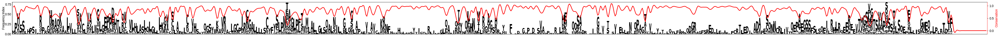

In [3]:
# Sequences for mammalian STING downloaded from: https://www.orthodb.org/?level=40674&species=40674&query=399134at40674
#!wget https://data.orthodb.org/v12/fasta?id=399134at40674&seqtype=protein&species=40674 -O sting.fasta

# Aligned the sequences using MAFFT web server: https://mafft.cbrc.jp/alignment/server/
# Default arguments
alignment = "STING_Alignment.fa"
# Load the alignment
data = dict()
hsapien_txid = "9606_0"
mmusculus_txid = "10090_0"
with open(alignment) as f:
    for record in FastaIterator(f):
        txid = record.id.split(":")[0]
        if txid in data:
            txid += "_1"
        data[txid] = str(record.seq)

# Next, remove all positions which are gaps in the mouse sequence
mouse_gap_positions = [i for i, aa in enumerate(data[mmusculus_txid]) if aa == "-"]
for txid, sequence in list(data.items()):
    data[txid] = "".join([aa for i, aa in enumerate(sequence) if i not in mouse_gap_positions]).replace("-", " ")

mouse_conservation = dict(mouse_position=[], mouse_AA=[], conservation=[])
for i, row in pd.DataFrame({k: list(v) for k,v in data.items()}).iterrows():
    mouse_aa = row[mmusculus_txid]
    mouse_conservation['mouse_position'].append(i)
    mouse_conservation['mouse_AA'].append(mouse_aa)
    # Get the conservation
    conservation = np.sum(row == mouse_aa) / len(row)
    mouse_conservation['conservation'].append(conservation)
pd.DataFrame(mouse_conservation).to_csv("conservation.csv")

# Finally, we will generate a logo of conservation
# Get all the possible AAs
logo_df = dict()
for sequence in data.values():
    for aa in set(sequence):
        if aa not in logo_df:
            logo_df[aa] = np.zeros(len(sequence))

for i, sequence in enumerate(data.values()):
    for j, aa in enumerate(sequence):
        logo_df[aa][j] += 1
logo_df = pd.DataFrame(logo_df)
# Set the index by the position
logo_df.index = [f"{i+1}" for i, aa in enumerate(data[mmusculus_txid])]
# Compute bits (Shannon entropy)
orig_logo_df = logo_df.div(logo_df.sum(axis=1), axis=0)  # Normalize to relative frequencies

# Compute the entropy bits to normalize our frequencies by
bits = orig_logo_df.copy()
for col in list(bits.columns):
    bits[col] = bits[col].map(lambda x: x * np.log2(x) if x > 0 else 0)
bits = -bits.sum(axis=1)
bits = bits / np.log2(20)  # Normalize to bits

# Multiply the frequencies by our bits
logo_df = orig_logo_df.mul(bits, axis=0)

# Colors
#22B573, 2212CF, CF0878, CF6508, CECF12
# No grids in plots
# Single grey with different transparency?

# variants_of_interest = [
#     "Y3", "V27", "A48", "L56", "G57", "K61", "E68", "E69", "K83", "V85",
#     "C91", "C95", "H185", "L197", "L200", "L203", "C205", "A232", "S240",
#     "L298", "L324", "L373"
# ]


# to_highlight = [v + "X" for v in variants_of_interest] + controls
to_highlight = controls

# Insert the controls to our logo data
for control in controls:
    # Try to extract the number in the middle
    try:
        num = int(control[1:-1])
        first_aa = control[0]
        values = logo_df[str(num)].values.flatten()
        orig_values = orig_logo_df[str(num)].values.flatten()
    except:
        # 0 for each column for non-substitution variants
        values = np.zeros(logo_df.shape[1])
        orig_values = np.zeros(logo_df.shape[1])
    # Add the position as a new row
    logo_df.loc[control] = values
    orig_logo_df.loc[control] = orig_values

def make_logo(ax, positions: list[str] = None, include_conservation=False, logo_df=logo_df, orig_logo_df=orig_logo_df, annotate_positions: list[str] = None):
    logo_df = logo_df.copy()
    orig_logo_df = orig_logo_df.copy()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        if positions is not None:
            # Map to integers
            new_positions = []
            for position in positions:
                try:
                    position_sub = position[1:-1]  # Try to get a position
                    position_i = str(int(position_sub))
                    if position_i not in logo_df.index.values and position.endswith("X"):
                        # Add dummy row
                        logo_df.loc[position_i] = 0
                        orig_logo_df.loc[position_i] = 0
                        new_positions.append(position_i)
                    elif position not in logo_df.index.values and not position.endswith('X'):  # Control variant
                        logo_df.loc[position] = logo_df.loc[position_i]
                        orig_logo_df.loc[position] = orig_logo_df.loc[position_i]
                        new_positions.append(position)
                    else:
                        if position in logo_df.index.values:
                            new_positions.append(position)
                        elif position_i in logo_df.index.values:
                            new_positions.append(position_i)
                        else:
                            raise ValueError("Position {} not in logo df".format(position_i))
                except:
                    if position not in logo_df.index.values:
                        logo_df.loc[position] = 0
                        orig_logo_df.loc[position] = 0
                        new_positions.append(position)
                    else:
                        new_positions.append(position)
            rearranged_logo_df = logo_df.loc[new_positions]
            rearranged_original_logo_df = orig_logo_df.loc[new_positions]
        else:
            rearranged_logo_df = logo_df
            rearranged_original_logo_df = orig_logo_df

        logo_plt = logomaker.Logo(
            rearranged_logo_df.reset_index(drop=True, inplace=False),
            stack_order='big_on_top',
            # color_scheme='dmslogo_funcgroup',
            # All black color scheme
            color_scheme={aa: 'black' for aa in rearranged_logo_df.columns},
            ax=ax
        )
        logo_plt.style_spines(visible=False)
        logo_plt.ax.set_ylabel("Frequency Index", labelpad=-1)
        logo_plt.ax.yaxis.set_ticks_position('none')
        logo_plt.ax.yaxis.set_tick_params(size=0)
        # Make grid lines invisible
        logo_plt.ax.xaxis.grid(False)
        logo_plt.ax.yaxis.grid(False)
        logo_plt.ax.spines['left'].set_visible(True)
        logo_plt.ax.xaxis.set_ticks_position('none')
        logo_plt.ax.xaxis.set_tick_params(size=0)
        plt.setp(ax.get_xticklabels(), visible=False)

        if annotate_positions:
            annotation_mask = rearranged_logo_df.index.isin(annotate_positions)
            for i, mask in enumerate(annotation_mask):
                ax.text(i, -.01, '*' if mask else ' ', ha='center', va='top')

        if include_conservation:
            # Plot a red line for conservation
            # Compute the % of top amino acid per position
            conservation = rearranged_original_logo_df.max(axis=1)
            # Plot the conservation
            from scipy.interpolate import BSpline, make_interp_spline
            spl = make_interp_spline(range(len(conservation)), conservation, k=3)
            smoothed = spl(np.linspace(0, len(conservation) - 1, 1000))
            secondary = logo_plt.ax.twinx()
            secondary.plot(np.linspace(0, len(conservation) - 1, 1000), smoothed, color='red', linewidth=2)
            secondary.set_ylabel("Conservation", color='red')
            secondary.spines['right'].set_color('red')
        return logo_plt

fig, ax = plt.subplots(figsize=(60, 2))
make_logo(ax, include_conservation=True)

<Axes: ylabel='# Mutated'>

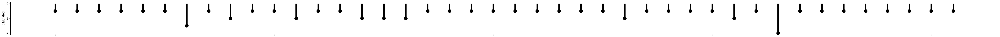

In [4]:
# Lollipop plots of mutations
lollipop_df = pd.read_csv("human_STING_cancer_variants.csv")  # Manually created by searching for TMEM173 and counting occurrences for each position
# https://www.cbioportal.org/results/mutations?case_set_id=all&gene_list=STING1&cancer_study_list=5c8a7d55e4b046111fee2296
lollipop_df['ref'] = lollipop_df['variant'].str[0]
lollipop_df['alt'] = lollipop_df['variant'].str[-1]
lollipop_df['position'] = lollipop_df['variant'].str[1:-1].astype(int)

# Convert the positions to mouse (Humans have an additional AA in position 108)
# Drop 108
lollipop_df = lollipop_df[lollipop_df['position'] != 108]
# Shift the positions after 108
lollipop_df['position'] = lollipop_df['position'].apply(lambda x: x - 1 if x > 108 else x)
lollipop_df['position'] = lollipop_df['position'].astype(str)
lollipop_df['variant'] = lollipop_df['ref'] + lollipop_df['position'] + lollipop_df['alt']

tcga_variants = lollipop_df.variant.unique().tolist()
lollipop_df = lollipop_df.groupby('position').size().reset_index(name='count')

def make_lollipop(ax, positions: list[str] = None):
    new_df = lollipop_df.copy()
    if positions is not None:
        new_df = pd.DataFrame({'position': [], 'count': []})
        for position in positions:
            try:
                position_sub = position[1:-1]  # Try to get a position
                position_i = str(int(position_sub))
                if position_i not in lollipop_df['position'].values and position.endswith('X'):
                    # Add dummy row
                    new_df = pd.concat([new_df, pd.DataFrame({'position': [str(position_i)], 'count': [0]})], ignore_index=True)
                else:
                    # Get value for the position
                    if position_i in lollipop_df['position'].values:
                        count = lollipop_df[lollipop_df['position'] == position_i]['count'].values[0]
                        new_df = pd.concat([new_df, pd.DataFrame({'position': [position_i], 'count': [count]})], ignore_index=True)
                    else:
                        new_df = pd.concat([new_df, pd.DataFrame({'position': [position_i], 'count': [0]})], ignore_index=True)
            except:
                new_df = pd.concat([new_df, pd.DataFrame({'position': [str(position)], 'count': [0]})], ignore_index=True)
    new_df['index'] = np.arange(len(new_df))
    new_df = new_df[new_df['count'] > 0]
    # ax.stem(new_df['index'], new_df['count'], markerfmt='o', basefmt=' ')  # Uses default color
    # Color lollipops black
    markerline, stemlines, baseline = ax.stem(new_df['index'], new_df['count'], markerfmt='o', basefmt=' ', linefmt='black')
    stemlines.set_linewidth(5)        # thickens the vertical stems
    markerline.set_markeredgewidth(6) # makes marker edges thicker
    # Disable all splines except the left and bottom
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.invert_yaxis()
    # Disable x ticks
    # ax.xaxis.set_ticks([])
    # Disable grid lines
    # ax.grid(False)
    ax.xaxis.grid(False)
    ax.yaxis.grid(False)
    ax.set_ylabel("# Mutated")
    plt.setp(ax.get_xticklabels(), visible=False)
    return ax

fig, ax = plt.subplots(figsize=(60, 2))
make_lollipop(ax)

In [5]:
tcga_variants

['S126T',
 'R219C',
 'R168W',
 'V112L',
 'Q358K',
 'S354F',
 'V328F',
 'T375K',
 'Y273C',
 'R252W',
 'L49I',
 'R374C',
 'R196Q',
 'R179Q',
 'H231Y',
 'Q275P',
 'R374H',
 'L201I',
 'K288R',
 'G165R',
 'R219H',
 'K337N',
 'N61H',
 'R283M',
 'S4C',
 'G90C',
 'R190Q',
 'L201F',
 'W82R',
 'P370L',
 'E335D',
 'W34L',
 'Q334H',
 'W160L',
 'E38D',
 'P140Q',
 'R76M',
 'D209N',
 'G343C',
 'R252Q',
 'D318E',
 'R333L',
 'A317T',
 'P202S',
 'E173K',
 'L123Q']

In [6]:
conservation = pd.read_csv("conserved_residues.csv")
# Remove the deletion in mouse sting
conservation = conservation[conservation['mouse STING'] != "'X'"]
# Convert Conserved 0/1 values to colors (white or black)
conservation['color'] = conservation['Conserved'].apply(lambda x: 'black' if x == 1 else 'white')
conservation['mouse STING'] = conservation['mouse STING'].str.replace("'", "")
conservation['mouse pos int'] = conservation['mouse STING'].str.extract(r'(\d+)').fillna("0").astype(int)
colname2np = {
    'white': np.array([1., 1., 1.]),
    'black': np.array([0., 0., 0.])
}
position2position_names = defaultdict(list)
position2color = defaultdict(lambda: colname2np['white'])
for _, row in conservation.iterrows():
    position = row['mouse STING']
    position_int = row['mouse pos int']
    position2color[position] = colname2np[row['color']]
    position2position_names[position_int].append(position)
    # Replace the X with every amino acid
    for aa in protein_letters_1to3.keys():
        position2color[position[:-1] + aa] = colname2np[row['color']]
        position2position_names[position_int].append(position[:-1] + aa)
    # Also include just the position number
    position2color[position_int] = colname2np[row['color']]

# Add all the control positions
for name in controls:
    if name == 'REF' or name == 'WT':
        position2color[name] = colname2np['black']
    elif (name[:-1] + "X") in position2color:
        position2color[name] = position2color[(name[:-1] + "X")]
    else:
        position2color[name] = colname2np['white']
conservation_df = conservation

In [7]:
# From Matt:
# Transmembrane domain (#218F9B) = 18-34, 45-69, 92-106, 116-133
# Cyclic dinucleotide-binding domain (CBD) (#F4A92F) = 152-339
# C-terminal tail (CTT) (#DA3B25) = 339-378
# Default: White
domain2color = defaultdict(lambda: np.array([255, 255, 255]) / 255)

for i in range(18, 35):  # Transmembrane domain
    domain2color[i] = np.array([33, 143, 155]) / 255
    # Get the mouse string
    for pos in position2position_names[i]:
        domain2color[pos] = np.array([33, 143, 155]) / 255
for i in range(45, 70):  # Transmembrane domain
    domain2color[i] = np.array([33, 143, 155]) / 255
    # Get the mouse string
    for pos in position2position_names[i]:
        domain2color[pos] = np.array([33, 143, 155]) / 255
for i in range(92, 107):  # Transmembrane domain
    domain2color[i] = np.array([33, 143, 155]) / 255
    # Get the mouse string
    for pos in position2position_names[i]:
        domain2color[pos] = np.array([33, 143, 155]) / 255
for i in range(116, 134):  # Transmembrane domain
    domain2color[i] = np.array([33, 143, 155]) / 255
    # Get the mouse string
    for pos in position2position_names[i]:
        domain2color[pos] = np.array([33, 143, 155]) / 255

for i in range(152, 340):  # CBD
    domain2color[i] = np.array([244, 169, 47]) / 255
    # Get the mouse string
    for pos in position2position_names[i]:
        domain2color[pos] = np.array([244, 169, 47]) / 255

for i in range(339, 379):  # CTT
    domain2color[i] = np.array([218, 59, 37]) / 255
    # Get the mouse string
    for pos in position2position_names[i]:
        domain2color[pos] = np.array([218, 59, 37]) / 255

In [7]:
def compute_read_counts_dists(abundance_df: pd.DataFrame):
    is_initial = abundance_df.experiment.str.startswith("Initial")
    initial_abundance = abundance_df[is_initial].drop("experiment", axis=1)
    non_initial = abundance_df[~is_initial].groupby(['position', 'variant', 'umi'])['count'].sum().reset_index()

    initial_abundance.set_index(['position', 'variant', 'umi'], inplace=True)
    non_initial.set_index(['position', 'variant', 'umi'], inplace=True)

    # Perform the merges using indexes
    abundance_df = non_initial.join(initial_abundance, how='outer', lsuffix='', rsuffix='_initial').fillna(0).reset_index()

    # Plot the number of reads per clone
    plt.figure(figsize=(10,10))
    plt.hist(np.log1p(initial_abundance.groupby(['position', 'variant', 'umi'])['count'].sum() / initial_abundance['count'].sum() * 1e6), bins=100, alpha=0.5, label="Initial")
    plt.hist(np.log1p(non_initial.groupby(['position', 'variant', 'umi'])['count'].sum() / non_initial['count'].sum() * 1e6), bins=100, alpha=0.5, label='Mice')
    plt.legend()
    plt.xlabel("TPM")
    plt.ylabel("Frequency")
    plt.title("Clonal frequencies")
    plt.show()
    plt.clf()

    # Count unique umis
    abundance_df = abundance_df.groupby(['position', 'variant']).agg({
        'umi': 'nunique',
        'count': 'sum',
        'count_initial': 'sum'
    }).reset_index()

    # Normalize to TPM
    abundance_df['count'] = abundance_df['count']/abundance_df['count'].sum() * 1e6
    abundance_df['count_initial'] = abundance_df['count_initial']/abundance_df['count_initial'].sum() * 1e6

    # with PdfPages("figures/read_distributions_by_position.pdf") as pdf:
    #     for position, data in tqdm(abundance_df.groupby('position')):
    #         plt.figure(figsize=(12,8))
    #         sns.histplot(x=data['count_initial'], y=data['count'], bins=25)
    #         plt.title(position)
    #         plt.xlabel("Initial TPM")
    #         plt.ylabel("Treatment TPM")
    #         pdf.savefig()
    #         plt.close()
    #         plt.clf()


    initial = initial_abundance.reset_index().groupby(['position']).agg({
        'count': 'sum',
        'umi': 'nunique',
        'variant': 'nunique'
    }).reset_index()
    non_initial = non_initial.reset_index().groupby(['position']).agg({
        'count': 'sum',
        'umi': 'nunique',
        'variant': 'nunique'
    }).reset_index()

    plt.figure(figsize=(12,8))
    ax = sns.scatterplot(
        initial, x='count', y='umi', size='variant', c='black'
    )
    sns.scatterplot(
        non_initial, x='count', y='umi', size='variant', c='red', ax=ax
    )
    plt.xscale("log")
    plt.yscale("log")
    plt.show()
    plt.clf()

compute_read_counts_dists(pd.read_csv("4T1_Mammary_Fat_Pad_Initial_vs_Met/4T1_Mammary_Fat_Pad_Initial_vs_Met_abundance_with_variant.csv"))

FileNotFoundError: [Errno 2] No such file or directory: '4T1_Mammary_Fat_Pad_Initial_vs_Met/4T1_Mammary_Fat_Pad_Initial_vs_Met_abundance_with_variant.csv'

In [8]:
experiments = {
    "4T1_Initial_vs_Tail_Vein": fix_nans(pd.read_csv("../results/4T1_Tail_Vein_vs_Lung_Met/4T1_Tail_Vein_vs_Lung_Met_boot.csv")),
    "4T1_Ref_Stop_C147_K159_Initial_vs_Tail_Vein": fix_nans(pd.read_csv("../results/4T1_Ref_Stop_C147_K159_Initial_vs_Tail_Vein/4T1_Ref_Stop_C147_K159_Initial_vs_Tail_Vein_boot.csv")),
    "4T1_Mammary_Fat_Pad_Initial_vs_Primary": fix_nans(pd.read_csv("../results/4T1_Mammary_Fat_Pad_Initial_vs_Primary/4T1_Mammary_Fat_Pad_Initial_vs_Primary_boot.csv")),
    "4T1_Mammary_Fat_Pad_Initial_vs_Met": fix_nans(pd.read_csv("../results/4T1_Mammary_Fat_Pad_Initial_vs_Met/4T1_Mammary_Fat_Pad_Initial_vs_Met_boot.csv")),
    "4T1_Mammary_Fat_Pad_Primary_vs_Met": fix_nans(pd.read_csv("../results/4T1_Mammary_Fat_Pad_Primary_vs_Met/4T1_Mammary_Fat_Pad_Primary_vs_Met_boot.csv")),
    "EO771_Initial_vs_Tail_Vein": fix_nans(pd.read_csv("../results/EO771_Initial_vs_Tail_Vein/EO771_Initial_vs_Tail_Vein_boot.csv")),
    "EO771_Mammary_Fat_Pad_Initial_vs_Primary": fix_nans(pd.read_csv("../results/EO771_Mammary_Fat_Pad_Initial_vs_Primary/EO771_Mammary_Fat_Pad_Initial_vs_Primary_boot.csv")),
    "4T1_Initial_vs_MitogenHigh_p5": fix_nans(pd.read_csv("../results/4T1_Initial_vs_MitogenHigh_p5/4T1_Initial_vs_MitogenHigh_p5_boot.csv")),
    "4T1_Initial_vs_MitogenHigh_p10": fix_nans(pd.read_csv("../results/4T1_Initial_vs_MitogenHigh_p10/4T1_Initial_vs_MitogenHigh_p10_boot.csv")),
    "4T1_Initial_vs_MitogenHigh_p20": fix_nans(pd.read_csv("../results/4T1_Initial_vs_MitogenHigh_p20/4T1_Initial_vs_MitogenHigh_p20_boot.csv")),
    "4T1_Initial_vs_MitogenLow_p5": fix_nans(pd.read_csv("../results/4T1_Initial_vs_MitogenLow_p5/4T1_Initial_vs_MitogenLow_p5_boot.csv")),
    "4T1_Initial_vs_MitogenLow_p10": fix_nans(pd.read_csv("../results/4T1_Initial_vs_MitogenLow_p10/4T1_Initial_vs_MitogenLow_p10_boot.csv")),
    "4T1_Initial_vs_MitogenLow_p20": fix_nans(pd.read_csv("../results/4T1_Initial_vs_MitogenLow_p20/4T1_Initial_vs_MitogenLow_p20_boot.csv")),
    "EO771_Initial_vs_MitogenHigh_p5": fix_nans(pd.read_csv("../results/EO771_Initial_vs_MitogenHigh_p5/EO771_Initial_vs_MitogenHigh_p5_boot.csv")),
    "EO771_Initial_vs_MitogenHigh_p10": fix_nans(pd.read_csv("../results/EO771_Initial_vs_MitogenHigh_p10/EO771_Initial_vs_MitogenHigh_p10_boot.csv")),
    "EO771_Initial_vs_MitogenHigh_p20": fix_nans(pd.read_csv("../results/EO771_Initial_vs_MitogenHigh_p20/EO771_Initial_vs_MitogenHigh_p20_boot.csv")),
    "4T1_MitogenHigh_p5_vs_p10": fix_nans(pd.read_csv("../results/4T1_MitogenHigh_p5_vs_p10/4T1_MitogenHigh_p5_vs_p10_boot.csv")),
    "4T1_MitogenHigh_p10_vs_p20": fix_nans(pd.read_csv("../results/4T1_MitogenHigh_p10_vs_p20/4T1_MitogenHigh_p10_vs_p20_boot.csv")),
    "4T1_MitogenLow_p5_vs_p10": fix_nans(pd.read_csv("../results/4T1_MitogenLow_p5_vs_p10/4T1_MitogenLow_p5_vs_p10_boot.csv")),
    "4T1_MitogenLow_p10_vs_p20": fix_nans(pd.read_csv("../results/4T1_MitogenLow_p10_vs_p20/4T1_MitogenLow_p10_vs_p20_boot.csv")),
    "EO771_MitogenHigh_p5_vs_p10": fix_nans(pd.read_csv("../results/EO771_MitogenHigh_p5_vs_p10/EO771_MitogenHigh_p5_vs_p10_boot.csv")),
    "EO771_MitogenHigh_p10_vs_p20": fix_nans(pd.read_csv("../results/EO771_MitogenHigh_p10_vs_p20/EO771_MitogenHigh_p10_vs_p20_boot.csv")),
}

# Ignore the non-injected variants
experiments["4T1_Ref_Stop_C147_K159_Initial_vs_Tail_Vein"] = experiments["4T1_Ref_Stop_C147_K159_Initial_vs_Tail_Vein"][experiments["4T1_Ref_Stop_C147_K159_Initial_vs_Tail_Vein"]['position'].astype(str).isin(["REF", "STOP", "151", "78", "147"])].copy()

mice = list(range(316, 346))
mouse_exps = []
for mouse in mice:
    exp_name = f"4T1 {mouse} Mammary_Fat_Pad_Primary_vs_Met"
    df = experiments['4T1_Mammary_Fat_Pad_Primary_vs_Met']
    df = df[df['experiment'] == f"{mouse}_Mammory_Fat_Pad_Lung_Metastasis"].copy()
    df['experiment'] = exp_name
    experiments[exp_name] = df
    mouse_exps.append(exp_name)

experiments.keys()

/var/folders/w7/fjjnft7n129766g0r_d2g88w0000gn/T/ipykernel_8290/2725782117.py:2: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  "4T1_Initial_vs_Tail_Vein": fix_nans(pd.read_csv("../results/4T1_Tail_Vein_vs_Lung_Met/4T1_Tail_Vein_vs_Lung_Met_boot.csv")),
/var/folders/w7/fjjnft7n129766g0r_d2g88w0000gn/T/ipykernel_8290/2725782117.py:4: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  "4T1_Mammary_Fat_Pad_Initial_vs_Primary": fix_nans(pd.read_csv("../results/4T1_Mammary_Fat_Pad_Initial_vs_Primary/4T1_Mammary_Fat_Pad_Initial_vs_Primary_boot.csv")),
/var/folders/w7/fjjnft7n129766g0r_d2g88w0000gn/T/ipykernel_8290/2725782117.py:5: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  "4T1_Mammary_Fat_Pad_Initial_vs_Met": fix_nans(pd.read_csv("../results/4T1_Mammary_Fat_Pad_Initial_vs_Met/4T1_Mammary_Fat_Pad_Initial_vs_Met_boot.csv")),
/var/

dict_keys(['4T1_Initial_vs_Tail_Vein', '4T1_Ref_Stop_C147_K159_Initial_vs_Tail_Vein', '4T1_Mammary_Fat_Pad_Initial_vs_Primary', '4T1_Mammary_Fat_Pad_Initial_vs_Met', '4T1_Mammary_Fat_Pad_Primary_vs_Met', 'EO771_Initial_vs_Tail_Vein', 'EO771_Mammary_Fat_Pad_Initial_vs_Primary', '4T1_Initial_vs_MitogenHigh_p5', '4T1_Initial_vs_MitogenHigh_p10', '4T1_Initial_vs_MitogenHigh_p20', '4T1_Initial_vs_MitogenLow_p5', '4T1_Initial_vs_MitogenLow_p10', '4T1_Initial_vs_MitogenLow_p20', 'EO771_Initial_vs_MitogenHigh_p5', 'EO771_Initial_vs_MitogenHigh_p10', 'EO771_Initial_vs_MitogenHigh_p20', '4T1_MitogenHigh_p5_vs_p10', '4T1_MitogenHigh_p10_vs_p20', '4T1_MitogenLow_p5_vs_p10', '4T1_MitogenLow_p10_vs_p20', 'EO771_MitogenHigh_p5_vs_p10', 'EO771_MitogenHigh_p10_vs_p20', '4T1 316 Mammary_Fat_Pad_Primary_vs_Met', '4T1 317 Mammary_Fat_Pad_Primary_vs_Met', '4T1 318 Mammary_Fat_Pad_Primary_vs_Met', '4T1 319 Mammary_Fat_Pad_Primary_vs_Met', '4T1 320 Mammary_Fat_Pad_Primary_vs_Met', '4T1 321 Mammary_Fat_Pad_Pr

In [9]:
# Annotate by top percentiles
def annotate_extreme(threshold, upper_name, neutral_name):
    def annot_fn(df, name1, name2):
        cutoff = np.quantile(np.concatenate([df[f'observed_fitness_{name1}'].abs().values, df[f'observed_fitness_{name2}'].abs().values]), 1 - threshold)
        extreme_mask = ((df[f'observed_fitness_{name1}'].abs() > cutoff) | (df[f'observed_fitness_{name2}'].abs() > cutoff)) & (~df[f'observed_fitness_{name1}'].isna()) & (~df[f'observed_fitness_{name2}'].isna())
        df['extreme_points'] = extreme_mask
        df.loc[df['extreme_points'], 'colors'] = 'red'
        return df

    return annot_fn, {upper_name: 'red', neutral_name: 'black'}


def no_annotations():
    def annot_fn(df, name1, name2):
        df['extreme_points'] = False
        return df

    return annot_fn, {'': 'black'}


# Annotate by quadrant
def annotate_enrichment(minimum, first_enrichment_name, second_enrichment_name, require_both=False):
    def annot_fn(df, name1, name2):
        enriched_first = df[f'observed_fitness_{name1}'] > minimum
        enriched_second = df[f'observed_fitness_{name2}'] > minimum
        df['Enrichment'] = 'Neither'
        if require_both:
            df.loc[(enriched_first | enriched_second) & (df[f'observed_fitness_{name1}'] > minimum) & (df[f'observed_fitness_{name2}'] <= -minimum), 'Enrichment'] = first_enrichment_name
            df.loc[(enriched_first | enriched_second) & (df[f'observed_fitness_{name1}'] <= -minimum) & (df[f'observed_fitness_{name2}'] > minimum), 'Enrichment'] = second_enrichment_name
            df.loc[(enriched_first | enriched_second) & (df[f'observed_fitness_{name1}'] > minimum) & (df[f'observed_fitness_{name2}'] > minimum), 'Enrichment'] = 'Both Enriched'
        else:
            df.loc[(enriched_first | enriched_second) & ((df[f'observed_fitness_{name1}'] > minimum) & (df[f'observed_fitness_{name2}'] < 0.)), 'Enrichment'] = first_enrichment_name
            df.loc[(enriched_first | enriched_second) & ((df[f'observed_fitness_{name1}'] < 0.) & (df[f'observed_fitness_{name2}'] > minimum)), 'Enrichment'] = second_enrichment_name
            df.loc[(enriched_first | enriched_second) & ((df[f'observed_fitness_{name1}'] > 0) & (df[f'observed_fitness_{name2}'] > 0)), 'Enrichment'] = 'Both Enriched'

        df.loc[df['Enrichment'] == first_enrichment_name, 'colors'] = 'blue'
        df.loc[df['Enrichment'] == second_enrichment_name, 'colors'] = 'green'
        df.loc[df['Enrichment'] == 'Both Enriched', 'colors'] = 'red'

        df['extreme_points'] = df['Enrichment'] != 'Neither'
        return df

    return annot_fn, {first_enrichment_name: 'blue', second_enrichment_name: 'green', 'Both Enriched': 'red'}


def correlate_experiments(name1, name2, annot_fn, legend, show_legend=True, as_density=False, color_with_facs=False):
    df1 = summarize_data(experiments[name1].copy(), keep_variants_independent=True, infill_positions=[])[1]
    df2 = summarize_data(experiments[name2].copy(), keep_variants_independent=True, infill_positions=[])[1]

    if name1 == name2:
        name1 += " 1"
        name2 += " 2"

    df1['Name'] = name1
    df2['Name'] = name2
    joined = pd.merge(df1, df2, on=['variant', 'position', 'residue', 'is_control'], suffixes=('_' + name1, '_' + name2)).dropna().reset_index()
    if annot_fn:
        joined = annot_fn(joined, name1, name2)
    joined = joined.dropna()
    # Data merged, now generate the correlation figure
    # Make square plot
    fig, ax = plt.subplots(figsize=(10, 10))

    # Log axis:
    ax.set_xscale("symlog")
    ax.set_yscale("symlog")

    color = 'black'
    if color_with_facs:
        cmap = plt.get_cmap('coolwarm')
        norm = mpl.colors.TwoSlopeNorm(vmin=-2., vcenter=0., vmax=2.)
        color = []
        for i, row in joined.iterrows():
            variant = row['variant']
            if variant not in facs['variant'].values:
                facs_fit = 0.
            else:
                # Get facs ratio
                facs_fit = facs.loc[facs['variant'] == variant]['fitness'].iloc[0]
            color.append(cmap(norm(facs_fit)))


    # Add a linear best fit line:
    sns.regplot(
        data=joined, x=f'observed_fitness_{name1}', y=f'observed_fitness_{name2}',
        scatter=False, ax=ax, color='red', line_kws={"linewidth": 1, "linestyle": "--"},
        ci=None
    )

    # Create a scatter plot
    if as_density:
        # Greyscale density
        # sns.histplot(
        #     data=joined, x=f'observed_fitness_{name1}', y=f'observed_fitness_{name2}',
        #     edgecolor='none', ax=ax, color='black'
        # )
        density_scatter(joined[f'observed_fitness_{name1}'], joined[f'observed_fitness_{name2}'], ax=ax, size=5)
        show_legend=False
    else:
        sns.scatterplot(data=joined, x=f'observed_fitness_{name1}', y=f'observed_fitness_{name2}', ax=ax, color=color, edgecolor='none', alpha=0.85)


    # Disable grid lines
    ax.grid(False)
    # Square x and y axis range
    # lim = max(joined[f'observed_fitness_{name1}'].abs().max(), joined[f'observed_fitness_{name2}'].abs().max())*1.05
    # Set the dynamic range to for negative and positive directions
    ax.set_xlim(-1.5, 1.5)
    ax.set_ylim(-1.5, 1.5)
    # Disable top and right spines
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    # Add lines for 0s
    # ax.axvline(0, color='grey', linewidth=0.5)
    # ax.axhline(0, color='grey', linewidth=0.5)
    # Title
    ax.set_title(f"{name1} vs {name2}")
    # Label the axes
    ax.set_xlabel(name1 + " Fitness")
    ax.set_ylabel(name2 + " Fitness")

    # Label the extreme points by quadrant
    texts = []
    # Upper left corner
    upper_left = joined[(joined[f'observed_fitness_{name1}'] < 0) & (joined[f'observed_fitness_{name2}'] > 0) & joined['extreme_points']].copy()
    # Sort by furthest from 0,0
    upper_left['distance'] = np.sqrt((upper_left[f'observed_fitness_{name1}']**2 + upper_left[f'observed_fitness_{name2}']**2))
    upper_left = upper_left.sort_values('distance', ascending=False)
    for _, row in upper_left.head(20).iterrows():
        texts.append(ax.annotate(row['variant'], (row[f'observed_fitness_{name1}'], row[f'observed_fitness_{name2}']), fontsize=8, ha='left', backgroundcolor=('white', 0.25)))

    # Upper right corner
    upper_right = joined[(joined[f'observed_fitness_{name1}'] > 0) & (joined[f'observed_fitness_{name2}'] > 0) & joined['extreme_points']].copy()
    # Sort by furthest from 0,0
    upper_right['distance'] = np.sqrt((upper_right[f'observed_fitness_{name1}']**2 + upper_right[f'observed_fitness_{name2}']**2))
    upper_right = upper_right.sort_values('distance', ascending=False)
    for _, row in upper_right.head(20).iterrows():
        texts.append(ax.annotate(row['variant'], (row[f'observed_fitness_{name1}'], row[f'observed_fitness_{name2}']), fontsize=8, ha='right', backgroundcolor=('white', 0.25)))

    # Lower right corner
    lower_right = joined[(joined[f'observed_fitness_{name1}'] > 0) & (joined[f'observed_fitness_{name2}'] < 0) & joined['extreme_points']].copy()
    # Sort by furthest from 0,0
    lower_right['distance'] = np.sqrt((lower_right[f'observed_fitness_{name1}']**2 + lower_right[f'observed_fitness_{name2}']**2))
    lower_right = lower_right.sort_values('distance', ascending=False)
    for _, row in lower_right.head(20).iterrows():
        texts.append(ax.annotate(row['position'], (row[f'observed_fitness_{name1}'], row[f'observed_fitness_{name2}']), fontsize=8, ha='right', backgroundcolor=('white', 0.25)))

    # Lower left corner
    lower_left = joined[(joined[f'observed_fitness_{name1}'] < 0) & (joined[f'observed_fitness_{name2}'] < 0) & joined['extreme_points']].copy()
    # Sort by furthest from 0,0
    lower_left['distance'] = np.sqrt((lower_left[f'observed_fitness_{name1}']**2 + lower_left[f'observed_fitness_{name2}']**2))
    lower_left = lower_left.sort_values('distance', ascending=False)
    for _, row in lower_left.head(20).iterrows():
        texts.append(ax.annotate(row['variant'], (row[f'observed_fitness_{name1}'], row[f'observed_fitness_{name2}']), fontsize=8, ha='left', backgroundcolor=('white', 0.25)))

    # # Annotate Spike ins
    # if color_spike_ins:
    #     spike_ins = joined[joined['is_control']].copy()
    #     for _, row in spike_ins.iterrows():
    #         texts.append(ax.annotate(row['variant'], (row[f'observed_fitness_{name1}'], row[f'observed_fitness_{name2}']), fontsize=8, ha='center', backgroundcolor=('white', 0.25)))

    adjustText.adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle='-', color='black'), force_points=(2.6, 2.6), force_text=(1.55, 1.75), force_explode=(0.6, 0.6), expand=(1.15, 1.3), force_static=(0.7, 0.7), iter_lim=1000)

    # Place legend outside of the plot
    if legend and show_legend and len(legend) > 1:
        # Legend is a group name to color mapping dictionary
        ax.legend(handles=[plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=color, markersize=10, label=name) for name, color in legend.items()], loc='upper right', bbox_to_anchor=(1.2, 1))

    res = pearsonr(joined[f'observed_fitness_{name1}'],joined[f'observed_fitness_{name2}'])
    print(f"Correlation between {name1} and {name2}: {res.correlation} (p-value: {res.pvalue})")

    fig.tight_layout()

    return ax, joined

In [10]:
from scipy.stats import gaussian_kde
def all_pairwise_correlation(experiment, samples, title):
    df = experiments[experiment].copy()
    df = df[df['experiment'].isin(samples)]
    df = df[['experiment', 'observed_fitness', 'variant']]
    df = df.set_index(['variant'])
    # Prepend "Sample " to the experiment name
    df['experiment'] = "Sample " + df['experiment']
    # Pivot experiment to be the columns
    df = df.pivot(columns='experiment', values='observed_fitness')
    # Make a large correlation matrix plot (pair plot)
    # Disable grid and make black and white
    plt.figure(figsize=(10, 10))
    # Pair plot with density indicated by color
    # Greyscale density color
    grid = sns.PairGrid(df)
    grid.map_offdiag(density_scatter)
    grid.map_diag(sns.histplot, color='black')
    # grid = sns.pairplot(df, plot_kws={'color': 'black', 'edgecolor': 'none', 'size': 2}, diag_kws={'color': 'black'})
    for ax in grid.axes.flatten():
        ax.grid(False)
    # Add global title
    plt.suptitle(title, y=1.02)
    return ax

In [ ]:
all_pairwise_correlation(
    "EO771_Mammary_Fat_Pad_Initial_vs_Primary",
    ["10A_501_706", "10B_501_707", "10C_501_709", "10D_501_711", "10E_501_712"],
    "Correlation of internal samples (mouse 10) in EO771.lmb Initial vs MFP"
)
plt.savefig("figures/correlations/EO771_MFP_Initial_vs_Primary_internal_control_correlation.svg")
plt.savefig("figures/correlations/EO771_MFP_Initial_vs_Primary_internal_control_correlation.pdf")
plt.show()

In [ ]:
correlate_experiments(
    "4T1_Mammary_Fat_Pad_Initial_vs_Primary",
    "4T1_Mammary_Fat_Pad_Initial_vs_Met",
    as_density=True,
    *no_annotations()
)
plt.savefig("figures/correlations/4T1_MFP_Initial_vs_Primary_and_Initial_vs_Met_NO_ANNOTATIONS.svg")
plt.savefig("figures/correlations/4T1_MFP_Initial_vs_Primary_and_Initial_vs_Met_NO_ANNOTATIONS.pdf")
plt.show()

In [ ]:
correlate_experiments(
    "4T1_Mammary_Fat_Pad_Initial_vs_Primary",
    "4T1_Mammary_Fat_Pad_Initial_vs_Met",
    as_density=True,
    *no_annotations()
)
plt.savefig("figures/correlations/4T1_MFP_Initial_vs_Primary_and_Initial_vs_Met_NO_ANNOTATIONS.svg")
plt.savefig("figures/correlations/4T1_MFP_Initial_vs_Primary_and_Initial_vs_Met_NO_ANNOTATIONS.pdf")
plt.show()

In [ ]:
correlate_experiments(
    "4T1_Initial_vs_Tail_Vein",
    "4T1_Mammary_Fat_Pad_Initial_vs_Met",
    as_density=True,
    *no_annotations()
)
plt.savefig("figures/correlations/4T1_Initial_vs_Tail_Vein_and_MFP_Initial_vs_Met_NO_ANNOTATIONS.svg")
plt.savefig("figures/correlations/4T1_Initial_vs_Tail_Vein_and_MFP_Initial_vs_Met_NO_ANNOTATIONS.pdf")
plt.show()

In [ ]:
correlate_experiments(
    "EO771_Mammary_Fat_Pad_Initial_vs_Primary",
    "EO771_Initial_vs_Tail_Vein",
    *annotate_enrichment(.1, "EO771 MFP Enrichment", "EO771 Tail Vein Enrichment")
)
# plt.savefig("figures/correlations/EO771_MFP_Initial_vs_Primary_and_Initial_vs_Tail_Vein.svg")
# plt.savefig("figures/correlations/EO771_MFP_Initial_vs_Primary_and_Initial_vs_Tail_Vein.pdf")
plt.show()

In [ ]:
ax, df = correlate_experiments(
    "EO771_Mammary_Fat_Pad_Initial_vs_Primary",
    "4T1_Mammary_Fat_Pad_Initial_vs_Primary",
    *no_annotations(),
    as_density=True,
    # *annotate_extreme(0.01, "Top 1%", "Remaining")
)
df.to_excel( "figures/correlations/EO771_and_4T1_Initial_vs_MFP.xlsx")
plt.savefig("figures/correlations/EO771_and_4T1_Initial_vs_MFP.svg")
plt.savefig("figures/correlations/EO771_and_4T1_Initial_vs_MFP.pdf")
plt.show()

In [ ]:
ax, df = correlate_experiments(
    "EO771_Initial_vs_Tail_Vein",
    "4T1_Initial_vs_Tail_Vein",
    *no_annotations()
)
df.to_excel( "figures/correlations/EO771_and_4T1_Initial_vs_Tail_Vein.xlsx")
plt.savefig("figures/correlations/EO771_and_4T1_Initial_vs_Tail_Vein.svg")
plt.savefig("figures/correlations/EO771_and_4T1_Initial_vs_Tail_Vein.pdf")
plt.show()

In [ ]:
ax, df = correlate_experiments(
    "EO771_Initial_vs_MitogenHigh_p5",
    "4T1_Initial_vs_MitogenHigh_p5",
    *annotate_extreme(0.01, "Top 1%", "Remaining")
)
df.to_excel( "figures/correlations/EO771_and_4T1_Initial_vs_MitogenHigh_p5.xlsx")
plt.savefig("figures/correlations/EO771_and_4T1_Initial_vs_MitogenHigh_p5.svg")
plt.savefig("figures/correlations/EO771_and_4T1_Initial_vs_MitogenHigh_p5.pdf")
plt.show()

In [ ]:
ax, df = correlate_experiments(
    "EO771_Initial_vs_MitogenHigh_p10",
    "4T1_Initial_vs_MitogenHigh_p10",
    *annotate_extreme(0.01, "Top 1%", "Remaining")
)
df.to_excel( "figures/correlations/EO771_and_4T1_Initial_vs_MitogenHigh_p10.xlsx")
plt.savefig("figures/correlations/EO771_and_4T1_Initial_vs_MitogenHigh_p10.svg")
plt.savefig("figures/correlations/EO771_and_4T1_Initial_vs_MitogenHigh_p10.pdf")
plt.show()

In [ ]:
ax, df = correlate_experiments(
    "EO771_Initial_vs_MitogenHigh_p20",
    "4T1_Initial_vs_MitogenHigh_p20",
    *annotate_extreme(0.01, "Top 1%", "Remaining")
)
df.to_excel( "figures/correlations/EO771_and_4T1_Initial_vs_MitogenHigh_p20.xlsx")
plt.savefig("figures/correlations/EO771_and_4T1_Initial_vs_MitogenHigh_p20.svg")
plt.savefig("figures/correlations/EO771_and_4T1_Initial_vs_MitogenHigh_p20.pdf")
plt.show()

In [ ]:
ax, df = correlate_experiments(
    "4T1_Mammary_Fat_Pad_Initial_vs_Primary",
    "4T1_Mammary_Fat_Pad_Primary_vs_Met",
    *annotate_extreme(0.01, "Top 1%", "Remaining")
)
df.to_excel( "figures/correlations/4T1_MFP_Initial_vs_Primary_and_Primary_vs_Met.xlsx")
plt.savefig("figures/correlations/4T1_MFP_Initial_vs_Primary_and_Primary_vs_Met.svg")
plt.savefig("figures/correlations/4T1_MFP_Initial_vs_Primary_and_Primary_vs_Met.pdf")
plt.show()

In [ ]:
ax, df = correlate_experiments(
    "4T1_Mammary_Fat_Pad_Initial_vs_Primary",
    "4T1_Mammary_Fat_Pad_Initial_vs_Met",
    # *no_annotations()
    # *annotate_extreme(0.01, "Top 1%", "Remaining")
    *annotate_enrichment(.1, "Primary Enriched", "Met Enriched"),
    show_legend=False, color_spike_ins=True
)
df.to_excel("figures/correlations/4T1_MFP_Initial_vs_Primary_and_Initial_vs_Met.xlsx")
plt.savefig("figures/correlations/4T1_MFP_Initial_vs_Primary_and_Initial_vs_Met.svg")
plt.savefig("figures/correlations/4T1_MFP_Initial_vs_Primary_and_Initial_vs_Met.pdf")
plt.show()

In [ ]:
ax, df = correlate_experiments(
    "4T1_Mammary_Fat_Pad_Initial_vs_Primary",
    "4T1_Initial_vs_Tail_Vein",
    # *no_annotations()
    # *annotate_extreme(0.01, "Top 1%", "Remaining")
    *annotate_enrichment(.1, "Primary Enriched", "Met Enriched"),
    show_legend=False, color_spike_ins=True
)
df.to_excel("figures/correlations/4T1_MFP_Initial_vs_Primary_and_Initial_vs_Tail_Vein.xlsx")
plt.savefig("figures/correlations/4T1_MFP_Initial_vs_Primary_and_Initial_vs_Tail_Vein_Met.svg")
plt.savefig("figures/correlations/4T1_MFP_Initial_vs_Primary_and_Initial_vs_Tail_Vein_Met.pdf")
plt.show()

In [ ]:
ax, df =correlate_experiments(
    "4T1_Initial_vs_Tail_Vein",
    "4T1_Mammary_Fat_Pad_Initial_vs_Met",
    # *no_annotations()
    # *annotate_extreme(0.01, "Top 1%", "Remaining")
    *annotate_enrichment(.1, "Tail Vein Met Enriched", "MFP Met Enriched"),
    show_legend=False, color_spike_ins=True
)
df.to_excel( "figures/correlations/4T1_Initial_vs_Tail_Vein_and_MFP_Initial_vs_Met.xlsx")
plt.savefig("figures/correlations/4T1_Initial_vs_Tail_Vein_and_MFP_Initial_vs_Met.svg")
plt.savefig("figures/correlations/4T1_Initial_vs_Tail_Vein_and_MFP_Initial_vs_Met.pdf")
plt.show()

In [ ]:
ax, df =correlate_experiments(
    "4T1_Initial_vs_Tail_Vein",
    "4T1_Mammary_Fat_Pad_Initial_vs_Met",
    # *no_annotations()
    # *annotate_extreme(0.01, "Top 1%", "Remaining")
    *annotate_enrichment(.1, "Tail Vein Met Enriched", "MFP Met Enriched"),
    show_legend=False, color_spike_ins=True
)
df.to_excel( "figures/correlations/4T1_Initial_vs_Tail_Vein_and_MFP_Initial_vs_Met.xlsx")
plt.savefig("figures/correlations/4T1_Initial_vs_Tail_Vein_and_MFP_Initial_vs_Met.svg")
plt.savefig("figures/correlations/4T1_Initial_vs_Tail_Vein_and_MFP_Initial_vs_Met.pdf")
plt.show()

In [ ]:
def self_clustered_heatmap(df, exp2colors, title, collapse=False):
    if collapse:
        # df = df.groupby(['variant', 'experiment'])['observed_fitness'].median().reset_index()
        # df = df.pivot(index='variant', columns='experiment', values='observed_fitness')
        # FIXME
        raise NotImplementedError()
    else:
        df = df.pivot(index=['variant'], columns='experiment', values='observed_fitness')
    # Remove all NaN rows/columns
    df = df.dropna(axis=0, how='all')
    df = df.dropna(axis=1, how='all')
    df = df.fillna(0)  # Fill NaNs with 0

    colors = None
    if exp2colors is not None:
        for i, exp in enumerate(df.columns):
            if colors is None:
                colors = [[] for _ in range(len(exp2colors[exp]))]
            for color_list, color in zip(colors, exp2colors[exp]):
                color_list.append(color)

    ax = sns.clustermap(df.corr('spearman'), cmap='bwr', center=0, vmin=-1, vmax=1, xticklabels=True, yticklabels=True, figsize=(30, 30), col_colors=colors, row_colors=colors, metric='euclidean')
    ax.cax.set_ylabel('Spearman Correlation')
    plt.suptitle(title, y=1.02)

    return ax

In [ ]:
df = pd.concat([experiments['4T1_Mammary_Fat_Pad_Initial_vs_Primary'].copy(), experiments['4T1_Mammary_Fat_Pad_Initial_vs_Met'].copy()])
df['Mouse'] = df['experiment'].str.split('_').str[0]
df['exp'] = "Primary"
df.loc[df['experiment'].str.contains('Met'), 'exp'] = "Met"
df['experiment'] = df['Mouse'] + ' ' + df['exp']
sample_palette = sns.color_palette('flare', 2)
color_dict = {e: [sample_palette[1]] if 'Met' in e else [sample_palette[0]] for e in df['experiment'].unique()}

self_clustered_heatmap(
    df,
    color_dict,
    "4T1 Initial vs Primary and Initial vs Met Fitness"
)
plt.savefig("figures/heatmaps/4T1_MFP_Initial_vs_Primary_and_Initial_vs_Met_clustered_heatmap.svg")
plt.savefig("figures/heatmaps/4T1_MFP_Initial_vs_Primary_and_Initial_vs_Met_clustered_heatmap.pdf")
plt.show()

In [ ]:
exps2corr = [
    '4T1_Initial_vs_Tail_Vein',
    '4T1_Mammary_Fat_Pad_Initial_vs_Primary',
    '4T1_Mammary_Fat_Pad_Initial_vs_Met',
    '4T1_Initial_vs_MitogenHigh_p5',
    '4T1_Initial_vs_MitogenHigh_p10',
    '4T1_Initial_vs_MitogenHigh_p20',
    '4T1_Initial_vs_MitogenLow_p5',
    '4T1_Initial_vs_MitogenLow_p10',
    '4T1_Initial_vs_MitogenLow_p20',
]
sample_palette = sns.color_palette('Set3', 4)
color_dict = dict()
data2plot = []
for exp in exps2corr:
    df = experiments[exp].copy()
    df['Mouse'] = df['experiment'].str.split('_').str[0]
    # Mitogen experiments have a different naming convention
    if 'Mitogen' in exp:
        df['Mouse'] = df['experiment'].str.split('_').str[-2]
        # exp = "Growth"
        color_i = np.array([255, 255, 0]) / 255
    elif 'Tail_Vein' in exp:
        # exp = "Tail Vein"
        color_i = np.array([0, 97, 255]) / 255
    elif 'Primary' in exp:
        # exp = 'Primary'
        color_i = np.array([255, 67, 22]) / 255
    elif 'Met' in exp:
        # exp = "Metastasis"
        color_i = np.array([0, 251, 255]) / 255
    df['exp'] = exp
    df['experiment'] = df['Mouse'] + ' ' + df['exp']
    data2plot.append(df)
    for i, row in df.drop_duplicates(subset=['experiment', 'exp']).iterrows():
        color_dict[row['experiment']] = [color_i]
        color_dict[row['exp']] = [color_i]
data2plot = pd.concat(data2plot)
self_clustered_heatmap(
    data2plot,
    color_dict,
    "4T1 Experiments Fitness by variant barcode"
)
plt.savefig("figures/heatmaps/4T1_MFP_Primary_MFP_Met_Tail_Vein_Mitogen_clustered_heatmap.svg")
plt.savefig("figures/heatmaps/4T1_MFP_Primary_MFP_Met_Tail_Vein_Mitogen_clustered_heatmap.pdf")
plt.show()

In [ ]:
# Replace experiments with "mitogen" to just contain that word
data2plot['exp2'] = data2plot['exp'].replace({e: 'Mitogen' for e in data2plot[data2plot.exp.str.contains("Mitogen")]['exp'].unique()})
per_variant = pd.pivot(
    data2plot.groupby(["exp2", 'variant'])['observed_fitness'].mean().reset_index(),
    columns='exp2',
    index=['variant'],
    values='observed_fitness'
).reset_index()
# Annotate top
per_position = pd.pivot(
    data2plot.groupby(["exp2", "position", 'is_control'])['observed_fitness'].mean().reset_index().groupby(["exp2", "position", 'is_control'])['observed_fitness'].mean().reset_index(),
    columns='exp2',
    index=['position', 'is_control'],
    values='observed_fitness'
).reset_index()

# Annotate top and bottom 5% in each experiment
for experiment in data2plot.exp2.unique():
    lower_threshold = per_variant[experiment].quantile(0.05)
    upper_threshold = per_variant[experiment].quantile(0.95)
    per_variant[experiment + "_annotation"] = np.where(per_variant[experiment] <= lower_threshold, "Bottom 5%",
        np.where(per_variant[experiment] >= upper_threshold, "Top 5%", "Middle"))
    lower_threshold = per_position[experiment].quantile(0.05)
    upper_threshold = per_position[experiment].quantile(0.95)
    per_position[experiment + "_annotation"] = np.where(per_position[experiment] <= lower_threshold, "Bottom 5%",
        np.where(per_position[experiment] >= upper_threshold, "Top 5%", "Middle"))

per_variant.to_csv("figures/per_variant_individual_sample_experiment_fitness.csv")
per_position.to_csv("figures/per_position_individual_sample_experiment_fitness.csv")
per_position

In [ ]:
exps2corr = [
    '4T1_Initial_vs_Tail_Vein',
    '4T1_Mammary_Fat_Pad_Initial_vs_Primary',
    '4T1_Mammary_Fat_Pad_Initial_vs_Met',
    'EO771_Initial_vs_Tail_Vein',
    'EO771_Mammary_Fat_Pad_Initial_vs_Primary',
    # '4T1_Initial_vs_MitogenHigh_p5',
    # '4T1_Initial_vs_MitogenHigh_p10',
    # '4T1_Initial_vs_MitogenHigh_p20',
    # '4T1_Initial_vs_MitogenLow_p5',
    # '4T1_Initial_vs_MitogenLow_p10',
    # '4T1_Initial_vs_MitogenLow_p20',
    # 'EO771_Initial_vs_MitogenHigh_p5',
    # 'EO771_Initial_vs_MitogenHigh_p10',
    # 'EO771_Initial_vs_MitogenHigh_p20',
]
sample_palette = sns.color_palette('Set3', len(exps2corr))
data2plot = []
for exp in exps2corr:
    df = experiments[exp].copy()
    if 'EO771_Initial_vs_Tail_Vein' in exp:
        df['Mouse'] = df['experiment']
    # Mitogen experiments have a different naming convention
    elif 'Mitogen' in exp:
        df['Mouse'] = df['experiment'].str.split('_').str[-2]
    else:
        df['Mouse'] = df['experiment'].str.split('_').str[0]
    df['exp'] = exp
    df['experiment'] = df['Mouse'] + ' ' + df['exp']
    data2plot.append(df)

data2plot = pd.concat(data2plot)
# color_dict = dict()
# for i, row in data2plot.drop_duplicates(subset=['experiment', 'exp']).iterrows():
#     color_dict[row['experiment']] = [sample_palette[data2plot.exp.unique().tolist().index(row['exp'])]]

color_dict = dict()
for experiment in data2plot.experiment.unique():
    if 'Primary' in experiment:
        color_dict[experiment] = [np.array([193, 180, 154]) / 255]
    elif 'Met' in experiment:
        color_dict[experiment] = [np.array([224, 148, 109]) / 255]
    elif 'Tail' in experiment:
        color_dict[experiment] = [np.array([207, 8, 120]) / 255]
    elif 'Mito' in experiment:
        color_dict[experiment] = [np.array([63, 63, 63]) / 255]
    else:
        raise AssertionError()


self_clustered_heatmap(
    data2plot[data2plot['experiment'].str.contains("4T1")].copy(),
    color_dict,
    "4T1 Experiments Fitness by variant barcode"
)
plt.savefig("figures/heatmaps/4T1_Experiments_clustered_heatmap.svg")
plt.savefig("figures/heatmaps/4T1_Experiments_clustered_heatmap.pdf")
plt.show()
self_clustered_heatmap(
    data2plot.copy(),
    color_dict,
    "All Experiments Fitness",
    # "All Experiments Fitness, collapsed by position",
    # collapse=True
)
plt.savefig("figures/heatmaps/All_Experiments_clustered_heatmap.svg")
plt.savefig("figures/heatmaps/All_Experiments_clustered_heatmap.pdf")
plt.show()
self_clustered_heatmap(
    data2plot[data2plot['experiment'].str.contains("EO771")].copy(),
    color_dict,
    "EO771 Experiments Fitness by variant barcode"
)
plt.savefig("figures/heatmaps/EO771_Experiments_clustered_heatmap.svg")
plt.savefig("figures/heatmaps/EO771_Experiments_clustered_heatmap.pdf")
plt.show()

In [ ]:
def reshape_clustermap(cmap, cell_width=0.01, cell_height=0.01):  # https://stackoverflow.com/a/75026914
    ny, nx = cmap.data2d.shape

    hmap_width = nx * cell_width
    hmap_height = ny * cell_height

    hmap_orig_pos = cmap.ax_heatmap.get_position()
    cmap.ax_heatmap.set_position(
        [hmap_orig_pos.x0, hmap_orig_pos.y0, hmap_width, hmap_height]
    )

    if cmap.ax_col_colors:
        col_colors_pos = cmap.ax_col_colors.get_position()
        cmap.ax_col_colors.set_position(
            [col_colors_pos.x0, hmap_orig_pos.y0 + hmap_height, hmap_width, col_colors_pos.height]
        )
        col_height = col_colors_pos.height
    else:
        col_height = 0

    if cmap.ax_row_colors:
        row_colors_pos = cmap.ax_row_colors.get_position()
        cmap.ax_row_colors.set_position(
            [row_colors_pos.x0, row_colors_pos.y0, row_colors_pos.width, hmap_height]
        )
        row_width = row_colors_pos.width
    else:
        row_width = 0

    top_dg_pos = cmap.ax_col_dendrogram.get_position()
    cmap.ax_col_dendrogram.set_position(
        [hmap_orig_pos.x0, hmap_orig_pos.y0 + hmap_height + col_height, hmap_width, top_dg_pos.height]
    )

    left_dg_pos = cmap.ax_row_dendrogram.get_position()
    cmap.ax_row_dendrogram.set_position(
        [left_dg_pos.x0, left_dg_pos.y0, left_dg_pos.width, hmap_height]
    )

    # top_dg_pos = cmap.ax_col_dendrogram.get_position()
    # cmap.ax_col_dendrogram.set_position(
    #     [hmap_orig_pos.x0, hmap_orig_pos.y0 + hmap_height, hmap_width, top_dg_pos.height]
    # )
    #
    # left_dg_pos = cmap.ax_row_dendrogram.get_position()
    # cmap.ax_row_dendrogram.set_position(
    #     [left_dg_pos.x0, left_dg_pos.y0, left_dg_pos.width, hmap_height]
    # )

    if cmap.ax_cbar:
        cbar_pos = cmap.ax_cbar.get_position()
        hmap_pos = cmap.ax_heatmap.get_position()
        cmap.ax_cbar.set_position(
            [cbar_pos.x0, hmap_pos.y1, cbar_pos.width, cbar_pos.height]
        )

    plt.tight_layout()
    return cmap


def variant_by_sample_clustered_heatmap(df, exp2colors, title, normalize: bool = True, min_score: float = None):
    if min_score is not None:
        # Filter variants that are all below the minimum score
        df = df.groupby(['variant', 'is_control']).filter(lambda x: x['observed_fitness'].abs().max() > min_score)

    if normalize:  # Z-score per experiment
        df['observed_fitness'] = df.groupby('experiment')['observed_fitness'].transform(lambda x: (x - x.mean()) / x.std())

    positions = df['position'].str.extract(r'(\d+)').fillna("0").iloc[:, 0].str.strip().astype(int).tolist()
    df['position_int'] = positions
    df = df.sort_values('position_int')

    df_counts = df.pivot_table(index='experiment', columns='variant', values='count', aggfunc='sum')
    df = df.pivot_table(index='experiment', columns='variant', values='observed_fitness', aggfunc='median')
    position_ints = df.columns.str.extract(r'(\d+)').fillna("0").astype(int).iloc[:, 0].tolist()

    # Compute SDI for each position and for each experiment
    position2sdi = []
    experiment2sdi = []
    for position in df.columns:
        position2sdi.append(shannon_diversity_index(df_counts[position].dropna()))
    for experiment in df.index:
        experiment2sdi.append(shannon_diversity_index(df_counts.loc[experiment].dropna()))
    # Color scale for SDI (flare)
    sdi_colors = sns.color_palette('flare', as_cmap=True)
    position2sdi = [sdi_colors(sdi / max(position2sdi)) for sdi in position2sdi]
    experiment2sdi = [sdi_colors(sdi / max(experiment2sdi)) for sdi in experiment2sdi]

    # position_colors = sns.color_palette('flare', max(position_ints)+1)  # Darker values are closer to the end
    # position_colors = [position_colors[int(pos)] for pos in position_ints]
    domain_colors = [domain2color[int(pos)] for pos in position_ints]
    conservation_colors = [position2color[int(pos)] for pos in position_ints]

    colors = None
    if exp2colors is not None:
        for i, exp in enumerate(df.index.values):
            if colors is None:
                colors = [[] for _ in range(len(exp2colors[exp]))]
            for color_list, color in zip(colors, exp2colors[exp]):
                color_list.append(color)
    if colors is None:
        colors = []
    colors.append(experiment2sdi)

    ax = sns.clustermap(df.fillna(0), cmap='bwr', center=0, vmin=-2, vmax=2, xticklabels=True, yticklabels=True, figsize=(45, 60), row_colors=colors, col_colors=[domain_colors, conservation_colors, position2sdi])
    # Set the font size
    ax.ax_heatmap.set_xticklabels(ax.ax_heatmap.get_xmajorticklabels(), fontsize = 14, rotation=90)
    ax.ax_heatmap.set_yticklabels(ax.ax_heatmap.get_ymajorticklabels(), fontsize = 18, rotation=0)
    # Label the color bar
    # Increase the font size for the color bar axis
    ax.cax.set_ylabel('Fitness Z-score' if normalize else 'Fitness', fontsize=24)
    ax.cax.set_yticklabels(ax.cax.get_yticklabels(), fontsize=18)

    # Add Legend for the domain colors and conservation colors
    patches = [
        mpatches.Patch(color=(1., 1., 1.), label=f"No Domain"),
        mpatches.Patch(color=(33 / 255, 102 / 255, 172 / 255), label=f"CTT"),
        mpatches.Patch(color=(218 / 255, 59 / 255, 37 / 255), label=f"CTD"),
        mpatches.Patch(color=(0 / 255, 176 / 255, 240 / 255), label=f"Transmembrane"),

        mpatches.Patch(color=(1., 1., 1.), label=f"No Conservation"),
        mpatches.Patch(color=(0., 0., 0.), label=f"Conserved"),

        mpatches.Patch(color=sdi_colors(0.), label=f"Low Diversity"),
        mpatches.Patch(color=sdi_colors(1.), label=f"High Diversity"),
    ]
    # Locate to the right and OUTSIDE of the column colors
    ax.ax_col_colors.legend(handles=patches, loc='center right', bbox_to_anchor=(1.1, 0.5), fontsize=18)

    return ax

In [ ]:
ax = variant_by_sample_clustered_heatmap(
    data2plot.copy(),
    color_dict,
    "All Experiments Fitness Z-Normalized",
    normalize=True
)
plt.savefig("figures/heatmaps/All_Mice_Fitness_Z-Normalized_clustered_heatmap.svg")
plt.show()

In [ ]:
variant_by_sample_clustered_heatmap(
    data2plot.copy(),
    color_dict,
    "All Experiments Fitness",
    normalize=False
)
plt.savefig("figures/heatmaps/All_Mice_Fitness_non-normalized_clustered_heatmap.svg")
plt.show()

In [ ]:
# # Redo above but aggregate each sample
# data2plot = []
# for exp in exps2corr:
#     exp_df = experiments[exp].copy()
#     exp_df = aggregate_fitness(exp_df).reset_index()
#     exp_df['experiment'] = exp
#     data2plot.append(exp_df)
#
# data2plot = pd.concat(data2plot)
# color_dict = dict()
# for i, row in data2plot.iterrows():
#     color_dict[row['experiment']] = [sample_palette[exps2corr.index(row['experiment'])]]
#
# ax = self_clustered_heatmap(
#     data2plot.copy(),
#     #color_dict,
#     None,
#     "All Experiments, variant barcodes collapsed by taking median"
# )
# # Increase font size
# ax.ax_heatmap.set_xticklabels(ax.ax_heatmap.get_xmajorticklabels(), fontsize = 12)
# ax.ax_heatmap.set_yticklabels(ax.ax_heatmap.get_ymajorticklabels(), fontsize = 12)
# plt.savefig("figures/heatmaps/All_Experiments_median_position_Fitness_clustered_heatmap.svg")
# plt.savefig("figures/heatmaps/All_Experiments_median_position_Fitness_clustered_heatmap.pdf")
# plt.show()

In [ ]:
# ax = variant_by_sample_clustered_heatmap(
#     data2plot.copy(),
#     # color_dict,
#     None,
#     "All Experiments Fitness Z-Normalized",
#     normalize=True
# )
# reshape_clustermap(ax)
# plt.savefig("figures/All_Experiments_Fitness_Z-Normalized_clustered_heatmap.svg")
# plt.show()

In [ ]:
# variant_by_sample_clustered_heatmap(
#     data2plot.copy(),
#     # color_dict,
#     None,
#     "All Experiments Fitness",
#     normalize=False
# )
# plt.savefig("figures/All_Experiments_Fitness_non-normalized_clustered_heatmap.svg")
# plt.show()

In [ ]:
# Just 4T1 experiments
# variant_by_sample_clustered_heatmap(
#     data2plot[data2plot.experiment.str.contains('4T1')].copy(),
#     # color_dict,
#     None,
#     "4T1 Experiments Fitness Z-Normalized",
#     normalize=True
# )
# plt.savefig("figures/4T1_All_Experiments_Fitness_Z-Normalized_clustered_heatmap.svg")
# plt.show()

In [ ]:
# Just 4T1 experiments
# variant_by_sample_clustered_heatmap(
#     data2plot[data2plot.experiment.str.contains('4T1')].copy(),
#     # color_dict,
#     None,
#     "4T1 Experiments Fitness",
#     normalize=False
# )
# plt.savefig("figures/4T1_All_Experiments_Fitness_non-normalized_clustered_heatmap.svg")
# plt.show()

In [ ]:
# Just EO771 experiments
# variant_by_sample_clustered_heatmap(
#     data2plot[data2plot.experiment.str.contains('EO771')].copy(),
#     # color_dict,
#     None,
#     "EO771 Experiments Fitness Z-Normalized",
#     normalize=True
# )
# plt.savefig("figures/EO771_All_Experiments_Fitness_Z-Normalized_clustered_heatmap.svg")
# plt.show()

In [ ]:
# Just EO771 experiments
# variant_by_sample_clustered_heatmap(
#     data2plot[data2plot.experiment.str.contains('EO771')].copy(),
#     # color_dict,
#     None,
#     "EO771 Experiments Fitness",
#     normalize=False
# )
# plt.savefig("figures/EO771_All_Experiments_Fitness_non-normalized_clustered_heatmap.svg")
# plt.show()

# Plot on a PCA

# Proliferation Rates plots

In [ ]:
mito_high_4t1 = [
    experiments['4T1_Initial_vs_MitogenHigh_p5'].copy().assign(experiment='p5'),
    experiments['4T1_MitogenHigh_p5_vs_p10'].copy().assign(experiment='p10'),
    experiments['4T1_MitogenHigh_p10_vs_p20'].copy().assign(experiment='p20')
]
mito_high_eo771 = [
    experiments['EO771_Initial_vs_MitogenHigh_p5'].copy().assign(experiment='p5'),
    experiments['EO771_MitogenHigh_p5_vs_p10'].copy().assign(experiment='p10'),
    experiments['EO771_MitogenHigh_p10_vs_p20'].copy().assign(experiment='p20')
]
mito_low_4t1 = [
    experiments['4T1_Initial_vs_MitogenLow_p5'].copy().assign(experiment='p5'),
    experiments['4T1_MitogenLow_p5_vs_p10'].copy().assign(experiment='p10'),
    experiments['4T1_MitogenLow_p10_vs_p20'].copy().assign(experiment='p20')
]

In [ ]:
def compute_slopes(dfs):
    df = pd.concat(dfs, ignore_index=True)
    variants = df.variant.unique().tolist()
    passages = [5, 10, 20]
    fitness_mat = np.full((len(variants), len(passages)), fill_value=np.nan)
    for i, variant in enumerate(variants):
        for j, passage in enumerate(passages):
            data = df[(df['variant'] == variant) & (df['experiment'] == f'p{passage}')]
            if data.empty:
                continue
            fit = np.nanmedian(data['observed_fitness'].values)
            fitness_mat[i, j] = fit

    #Compute the slope of fitness change by passage for each variant, ignoring nans
    slopes = dict(variant=[], slope=[])
    for i, variant in enumerate(variants):
        valid_indices = ~np.isnan(fitness_mat[i, :])
        if np.sum(valid_indices) > 1:  # Ensure at least two valid points
            x = np.array(passages)[valid_indices]
            y = fitness_mat[i, valid_indices]
            slope, _ = np.polyfit(x, y, 1)  # Linear fit: y = slope * x + intercept
            slopes['variant'].append(variant)
            slopes['slope'].append(slope)

    return pd.DataFrame(slopes).sort_values(by=['slope'], ascending=False)

In [ ]:
mito_df = compute_slopes(mito_high_4t1)
ax = sns.histplot(data=mito_df, x='slope', color='grey')
# Center at 0
ax.set_xlim(-mito_df['slope'].abs().max(), mito_df['slope'].abs().max())
ax.grid(False)
plt.savefig("figures/4t1_mitogen_high_slope_NO_LABEL.svg")
plt.savefig("figures/4t1_mitogen_high_slope_NO_LABEL.pdf")

to_plot = [
    "STOP",
    "REF",
    "ΔCTT",
    "ΔUPR",
    "RRAA",
    "RRDD",
    "S365A",
    "V146L",
    "N153S",
    "V154M",
    "S161A",
    "I229A",
    "Y239S",
    "N241A"
]
for var in to_plot:
    slope = mito_df[mito_df['variant'] == var]['slope'].iloc[0]
    ax.axvline(x=slope, color='red', linestyle='-.')
    ax.text(slope, 0.98, var, va='top', ha='right', transform=ax.get_xaxis_transform(), rotation=90)
plt.xlabel('Slope for: Median Fitness = Passage x Slope + Intercept')
plt.title("4T1 Mitogen High")
plt.savefig("figures/4t1_mitogen_high_slope.svg")
plt.savefig("figures/4t1_mitogen_high_slope.pdf")
plt.show()
mito_df.to_excel("figures/4t1_mitogen_high_slope.xlsx")
print(mito_df.head())
print(mito_df.tail())

In [ ]:
mito_df = compute_slopes(mito_low_4t1)
ax = sns.histplot(data=mito_df, x='slope', color='grey')
# Center at 0
ax.set_xlim(-mito_df['slope'].abs().max(), mito_df['slope'].abs().max())
ax.grid(False)
plt.savefig("figures/4t1_mitogen_low_slope_NO_LABEL.svg")
plt.savefig("figures/4t1_mitogen_low_slope_NO_LABEL.pdf")

to_plot = [
    "STOP",
    "REF",
    "ΔCTT",
    "ΔUPR",
    "RRAA",
    "RRDD",
    "S365A",
    "V146L",
    "N153S",
    "V154M",
    "S161A",
    "I229A",
    "Y239S",
    "N241A"
]
for var in to_plot:
    slope = mito_df[mito_df['variant'] == var]['slope'].iloc[0]
    ax.axvline(x=slope, color='red', linestyle='-.')
    ax.text(slope, 0.98, var, va='top', ha='right', transform=ax.get_xaxis_transform(), rotation=90)
plt.xlabel('Slope for: Median Fitness = Passage x Slope + Intercept')
plt.title("4T1 Mitogen Low")
plt.savefig("figures/4t1_mitogen_low_slope.svg")
plt.savefig("figures/4t1_mitogen_low_slope.pdf")
plt.show()
mito_df.to_excel("figures/4t1_mitogen_low_slope.xlsx")
print(mito_df.head())
print(mito_df.tail())

In [ ]:
mito_df = compute_slopes(mito_high_eo771)
ax = sns.histplot(data=mito_df, x='slope', color='grey')
# Center at 0
ax.set_xlim(-mito_df['slope'].abs().max(), mito_df['slope'].abs().max())
ax.grid(False)
plt.savefig("figures/eo771_mitogen_high_slope_NO_LABEL.svg")
plt.savefig("figures/eo771_mitogen_high_slope_NO_LABEL.pdf")

to_plot = [
    "STOP",
    "REF",
    "ΔCTT",
    "ΔUPR",
    "RRAA",
    "RRDD",
    "S365A",
    "V146L",
    "N153S",
    "V154M",
    "S161A",
    "I229A",
    "Y239S",
    "N241A"
]
for var in to_plot:
    slope = mito_df[mito_df['variant'] == var]['slope'].iloc[0]
    ax.axvline(x=slope, color='red', linestyle='-.')
    ax.text(slope, 0.98, var, va='top', ha='right', transform=ax.get_xaxis_transform(), rotation=90)

plt.xlabel('Slope for: Median Fitness = Passage x Slope + Intercept')
plt.title("EO771 Mitogen High")
plt.savefig("figures/eo771_mitogen_high_slope.svg")
plt.savefig("figures/eo771_mitogen_high_slope.pdf")
plt.show()
mito_df.to_excel("figures/eo771_mitogen_high_slope.xlsx")
print(mito_df.head())
print(mito_df.tail())

Barplots

In [11]:
plt.rcParams.update({
    "font.size": 18,
})

C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:1005: RuntimeWarning: All-NaN slice encountered
  results['observed_fitness'].append(np.nanmedian(position_data[res_idx, :]))
C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:1024: RuntimeWarning: All-NaN slice encountered
  results['observed_fitness'].append(np.nanmedian(position_data[res_idx, :]))
C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:984: RuntimeWarning: All-NaN slice encountered
  results['observed_fitness'].append(np.nanmedian(position_data[res_idx, :]))
C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:962: RuntimeWarning: All-NaN slice encountered
  results['observed_fitness'].append(np.nanmedian(position_data[res_idx, :]))
C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:643: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in 

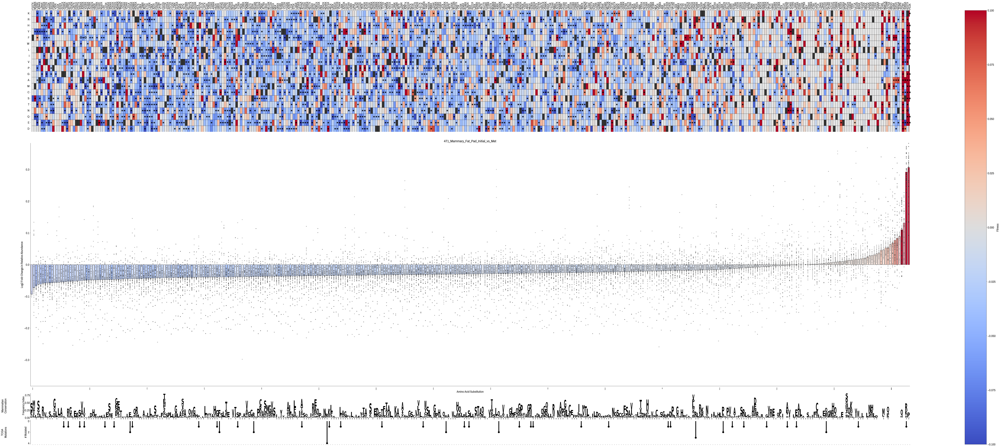

<Figure size 640x480 with 0 Axes>

In [10]:
initial_vs_met = "4T1_Mammary_Fat_Pad_Initial_vs_Met"
# position2facs = defaultdict(lambda k: np.array([1., 1., 1.]))
# mean_obs_fitness_cmap = mpl.colormaps.get_cmap('coolwarm')
# mean_obs_fitness_range = mpl.colors.TwoSlopeNorm(vmin=min(facs_grouped['logratios'].min(), -.1), vmax=max(facs_grouped['logratios'].max(), 0.1), vcenter=0)
# mean_obs_fitness_colors = mean_obs_fitness_cmap(mean_obs_fitness_range(np.nan_to_num(facs_df['logratios'].values)))
# for i, row in facs_grouped.iterrows():
#     pos = row['variant']
#     ratio = row['logratios']
#     position2facs[pos] = mean_obs_fitness_cmap(mean_obs_fitness_range(np.nan_to_num(ratio)))
# Stack two bar plots
make_fitness_barplot(
    total_output=experiments[initial_vs_met].copy(),
    # secondary_output=experiments[initial_vs_primary].copy(),
    #additional_outputs=[("Mitogen High", experiments[mito_high_p20].copy()), ("Mitogen Low", experiments[mito_low_p20].copy())],
    title=initial_vs_met,
    # secondary_output_title=initial_vs_primary,
    wt_sequence=mSTING,
    color_points=False,
    color_by_residue=False,
    # color_by_residue=True,
    # split_by_residue=True,
    # plot_by_residues=True,
    symmetrical_y_axis=True,
    weighted=False,
    highlighted_positions=to_highlight,
    # important_variants=tcga_variants,
    intermediate_output_file="figures/barplots/4T1_Met_Barplot.xlsx",
    tracks=[
        # ("FACS Log(Log(TPM UP) / Log(TPM DOWN))", position2facs),
        # ("Human\nConservation", position2color),
        # ("Domain", domain2color),
        ("Mammalian\nConservation", functools.partial(make_logo, annotate_positions=conservation_df[conservation_df['Conserved'] == 1]['mouse pos int'].astype(str).values.tolist() + ['REF'])),
        ("TCGA\nMutations", make_lollipop)
    ]
)
plt.savefig(f"figures/barplots/4T1_Met_Barplot.svg")
plt.savefig(f"figures/barplots/4T1_Met_Barplot.pdf")
plt.show()
plt.clf()

In [12]:
df = pd.concat(experiments.values())

df = df[~df.duplicated(['position', 'is_control'])].copy()
def convert(p):
    try:
        return int(p)
    except ValueError:
        return 0
df.position = df.position.apply(convert)
df = df.sort_values(['is_control', 'position'])
df.loc[~df['is_control'], 'variant'] = df[~df['is_control']].variant.str[:-1] + 'X'
positional_ordering = df.variant.values.tolist()
positional_ordering

['M1X',
 'P2X',
 'Y3X',
 'S4X',
 'N5X',
 'L6X',
 'H7X',
 'P8X',
 'A9X',
 'I10X',
 'P11X',
 'R12X',
 'P13X',
 'R14X',
 'G15X',
 'H16X',
 'R17X',
 'S18X',
 'K19X',
 'Y20X',
 'V21X',
 'A22X',
 'L23X',
 'I24X',
 'F25X',
 'L26X',
 'V27X',
 'A28X',
 'S29X',
 'L30X',
 'M31X',
 'I32X',
 'L33X',
 'W34X',
 'V35X',
 'A36X',
 'K37X',
 'D38X',
 'P39X',
 'P40X',
 'N41X',
 'H42X',
 'T43X',
 'L44X',
 'K45X',
 'Y46X',
 'L47X',
 'A48X',
 'L49X',
 'H50X',
 'L51X',
 'A52X',
 'S53X',
 'H54X',
 'E55X',
 'L56X',
 'G57X',
 'L58X',
 'L59X',
 'L60X',
 'K61X',
 'N62X',
 'L63X',
 'C64X',
 'C65X',
 'L66X',
 'A67X',
 'E68X',
 'E69X',
 'L70X',
 'C71X',
 'H72X',
 'V73X',
 'Q74X',
 'S75X',
 'R76X',
 'Y77X',
 'Q78X',
 'G79X',
 'S80X',
 'Y81X',
 'W82X',
 'K83X',
 'A84X',
 'V85X',
 'R86X',
 'A87X',
 'C88X',
 'L89X',
 'G90X',
 'C91X',
 'P92X',
 'I93X',
 'H94X',
 'C95X',
 'M96X',
 'A97X',
 'M98X',
 'I99X',
 'L100X',
 'L101X',
 'S102X',
 'S103X',
 'Y104X',
 'F105X',
 'Y106X',
 'F107X',
 'L108X',
 'Q109X',
 'N110X',
 'T111X'

C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:1005: RuntimeWarning: All-NaN slice encountered
  results['observed_fitness'].append(np.nanmedian(position_data[res_idx, :]))
C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:1024: RuntimeWarning: All-NaN slice encountered
  results['observed_fitness'].append(np.nanmedian(position_data[res_idx, :]))
C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:984: RuntimeWarning: All-NaN slice encountered
  results['observed_fitness'].append(np.nanmedian(position_data[res_idx, :]))
C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:962: RuntimeWarning: All-NaN slice encountered
  results['observed_fitness'].append(np.nanmedian(position_data[res_idx, :]))
C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:643: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in 

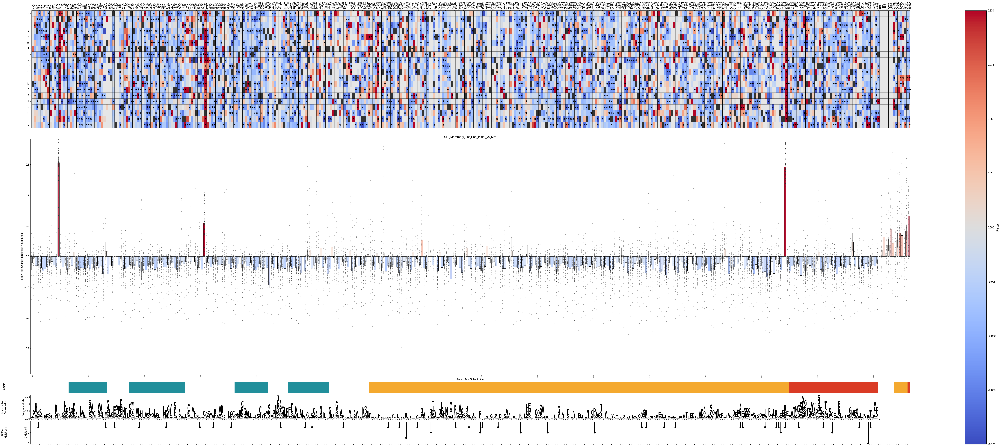

<Figure size 640x480 with 0 Axes>

In [12]:
initial_vs_met = "4T1_Mammary_Fat_Pad_Initial_vs_Met"
# position2facs = defaultdict(lambda k: np.array([1., 1., 1.]))
# mean_obs_fitness_cmap = mpl.colormaps.get_cmap('coolwarm')
# mean_obs_fitness_range = mpl.colors.TwoSlopeNorm(vmin=min(facs_grouped['logratios'].min(), -.1), vmax=max(facs_grouped['logratios'].max(), 0.1), vcenter=0)
# mean_obs_fitness_colors = mean_obs_fitness_cmap(mean_obs_fitness_range(np.nan_to_num(facs_df['logratios'].values)))
# for i, row in facs_grouped.iterrows():
#     pos = row['variant']
#     ratio = row['logratios']
#     position2facs[pos] = mean_obs_fitness_cmap(mean_obs_fitness_range(np.nan_to_num(ratio)))
# Stack two bar plots
make_fitness_barplot(
    total_output=experiments[initial_vs_met].copy(),
    # secondary_output=experiments[initial_vs_primary].copy(),
    #additional_outputs=[("Mitogen High", experiments[mito_high_p20].copy()), ("Mitogen Low", experiments[mito_low_p20].copy())],
    title=initial_vs_met,
    # secondary_output_title=initial_vs_primary,
    # Order by position
    wt_sequence=mSTING,
    ordering=positional_ordering,
    color_by_residue=False,
    # color_by_residue=True,
    # split_by_residue=True,
    # plot_by_residues=True,
    symmetrical_y_axis=True,
    weighted=False,
    highlighted_positions=to_highlight,
    # important_variants=tcga_variants,
    tracks=[
        # ("FACS Log(Log(TPM UP) / Log(TPM DOWN))", position2facs),
        # ("Human\nConservation", position2color),
        ("Domain", domain2color),
        ("Mammalian\nConservation", functools.partial(make_logo, annotate_positions=conservation_df[conservation_df['Conserved'] == 1]['mouse pos int'].astype(str).values.tolist() + ['REF'])),
        ("TCGA\nMutations", make_lollipop)
    ]
)
plt.savefig(f"figures/barplots/4T1_Met_Barplot_POS_ORDERED.svg")
plt.savefig(f"figures/barplots/4T1_Met_Barplot_POS_ORDERED.pdf")
plt.show()
plt.clf()

C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:1005: RuntimeWarning: All-NaN slice encountered
  results['observed_fitness'].append(np.nanmedian(position_data[res_idx, :]))
C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:1024: RuntimeWarning: All-NaN slice encountered
  results['observed_fitness'].append(np.nanmedian(position_data[res_idx, :]))
C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:984: RuntimeWarning: All-NaN slice encountered
  results['observed_fitness'].append(np.nanmedian(position_data[res_idx, :]))
C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:962: RuntimeWarning: All-NaN slice encountered
  results['observed_fitness'].append(np.nanmedian(position_data[res_idx, :]))
C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:643: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in 

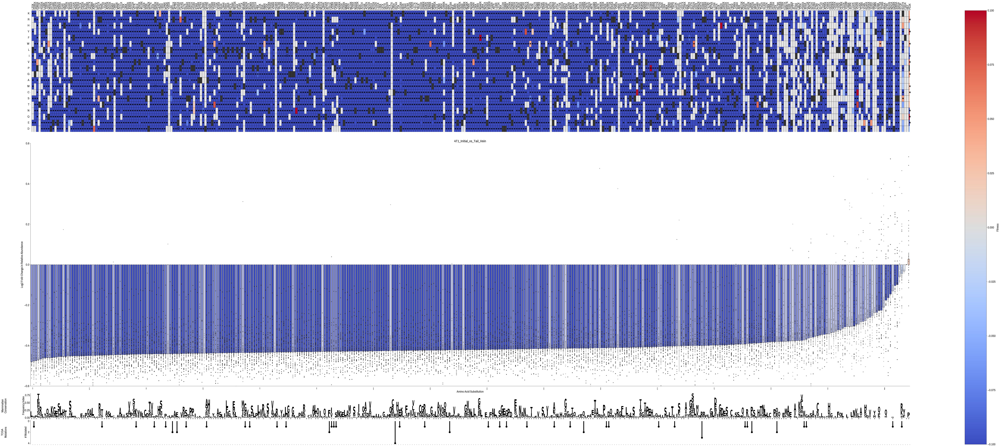

<Figure size 640x480 with 0 Axes>

In [13]:
initial_vs_met = "4T1_Initial_vs_Tail_Vein"
# position2facs = defaultdict(lambda k: np.array([1., 1., 1.]))
# mean_obs_fitness_cmap = mpl.colormaps.get_cmap('coolwarm')
# mean_obs_fitness_range = mpl.colors.TwoSlopeNorm(vmin=min(facs_grouped['logratios'].min(), -.1), vmax=max(facs_grouped['logratios'].max(), 0.1), vcenter=0)
# mean_obs_fitness_colors = mean_obs_fitness_cmap(mean_obs_fitness_range(np.nan_to_num(facs_df['logratios'].values)))
# for i, row in facs_grouped.iterrows():
#     pos = row['variant']
#     ratio = row['logratios']
#     position2facs[pos] = mean_obs_fitness_cmap(mean_obs_fitness_range(np.nan_to_num(ratio)))
# Stack two bar plots
make_fitness_barplot(
    total_output=experiments[initial_vs_met].copy(),
    # secondary_output=experiments[initial_vs_primary].copy(),
    #additional_outputs=[("Mitogen High", experiments[mito_high_p20].copy()), ("Mitogen Low", experiments[mito_low_p20].copy())],
    title=initial_vs_met,
    # secondary_output_title=initial_vs_primary,
    wt_sequence=mSTING,
    color_points=False,
    color_by_residue=False,
    # color_by_residue=True,
    # split_by_residue=True,
    # plot_by_residues=True,
    symmetrical_y_axis=True,
    weighted=False,
    highlighted_positions=to_highlight,
    # important_variants=tcga_variants,
    intermediate_output_file="figures/barplots/4T1_Tail_Vein_Barplot.xlsx",
    tracks=[
        # ("FACS Log(Log(TPM UP) / Log(TPM DOWN))", position2facs),
        # ("Human\nConservation", position2color),
        # ("Domain", domain2color),
        ("Mammalian\nConservation", functools.partial(make_logo, annotate_positions=conservation_df[conservation_df['Conserved'] == 1]['mouse pos int'].astype(str).values.tolist() + ['REF'])),
        ("TCGA\nMutations", make_lollipop)
    ]
)
plt.savefig(f"figures/barplots/4T1_Tail_Vein_Barplot.svg")
plt.savefig(f"figures/barplots/4T1_Tail_Vein_Barplot.pdf")
plt.show()
plt.clf()

C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:1005: RuntimeWarning: All-NaN slice encountered
  results['observed_fitness'].append(np.nanmedian(position_data[res_idx, :]))
C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:1024: RuntimeWarning: All-NaN slice encountered
  results['observed_fitness'].append(np.nanmedian(position_data[res_idx, :]))
C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:984: RuntimeWarning: All-NaN slice encountered
  results['observed_fitness'].append(np.nanmedian(position_data[res_idx, :]))
C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:962: RuntimeWarning: All-NaN slice encountered
  results['observed_fitness'].append(np.nanmedian(position_data[res_idx, :]))
C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:643: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in 

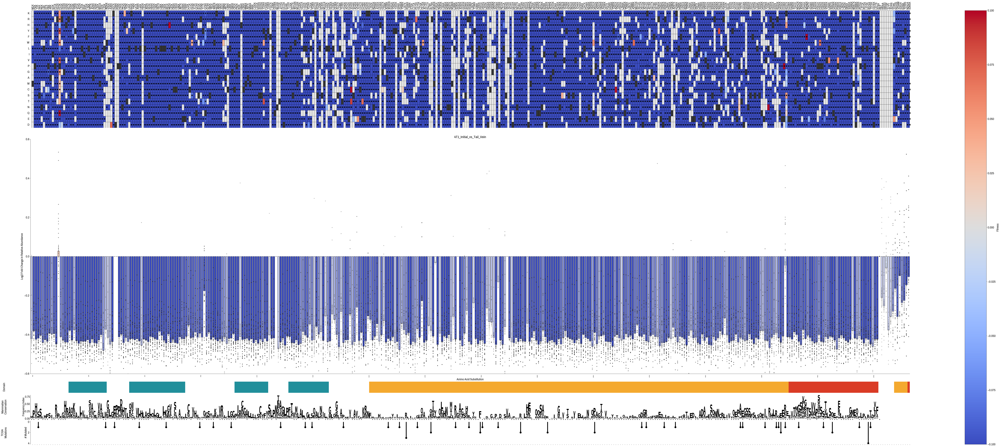

<Figure size 640x480 with 0 Axes>

In [14]:
initial_vs_met = "4T1_Initial_vs_Tail_Vein"
# position2facs = defaultdict(lambda k: np.array([1., 1., 1.]))
# mean_obs_fitness_cmap = mpl.colormaps.get_cmap('coolwarm')
# mean_obs_fitness_range = mpl.colors.TwoSlopeNorm(vmin=min(facs_grouped['logratios'].min(), -.1), vmax=max(facs_grouped['logratios'].max(), 0.1), vcenter=0)
# mean_obs_fitness_colors = mean_obs_fitness_cmap(mean_obs_fitness_range(np.nan_to_num(facs_df['logratios'].values)))
# for i, row in facs_grouped.iterrows():
#     pos = row['variant']
#     ratio = row['logratios']
#     position2facs[pos] = mean_obs_fitness_cmap(mean_obs_fitness_range(np.nan_to_num(ratio)))
# Stack two bar plots
make_fitness_barplot(
    total_output=experiments[initial_vs_met].copy(),
    # secondary_output=experiments[initial_vs_primary].copy(),
    #additional_outputs=[("Mitogen High", experiments[mito_high_p20].copy()), ("Mitogen Low", experiments[mito_low_p20].copy())],
    title=initial_vs_met,
    # secondary_output_title=initial_vs_primary,
    # Order by position
    wt_sequence=mSTING,
    ordering=positional_ordering,
    color_by_residue=False,
    # color_by_residue=True,
    # split_by_residue=True,
    # plot_by_residues=True,
    symmetrical_y_axis=True,
    weighted=False,
    highlighted_positions=to_highlight,
    # important_variants=tcga_variants,
    tracks=[
        # ("FACS Log(Log(TPM UP) / Log(TPM DOWN))", position2facs),
        # ("Human\nConservation", position2color),
        ("Domain", domain2color),
        ("Mammalian\nConservation", functools.partial(make_logo, annotate_positions=conservation_df[conservation_df['Conserved'] == 1]['mouse pos int'].astype(str).values.tolist() + ['REF'])),
        ("TCGA\nMutations", make_lollipop)
    ]
)
plt.savefig(f"figures/barplots/4T1_Tail_Vein_POS_ORDERED.svg")
plt.savefig(f"figures/barplots/4T1_Tail_Vein_POS_ORDERED.pdf")
plt.show()
plt.clf()

C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:1024: RuntimeWarning: All-NaN slice encountered
  results['observed_fitness'].append(np.nanmedian(position_data[res_idx, :]))
C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:1005: RuntimeWarning: All-NaN slice encountered
  results['observed_fitness'].append(np.nanmedian(position_data[res_idx, :]))
C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:984: RuntimeWarning: All-NaN slice encountered
  results['observed_fitness'].append(np.nanmedian(position_data[res_idx, :]))
C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:962: RuntimeWarning: All-NaN slice encountered
  results['observed_fitness'].append(np.nanmedian(position_data[res_idx, :]))
C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:643: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in 

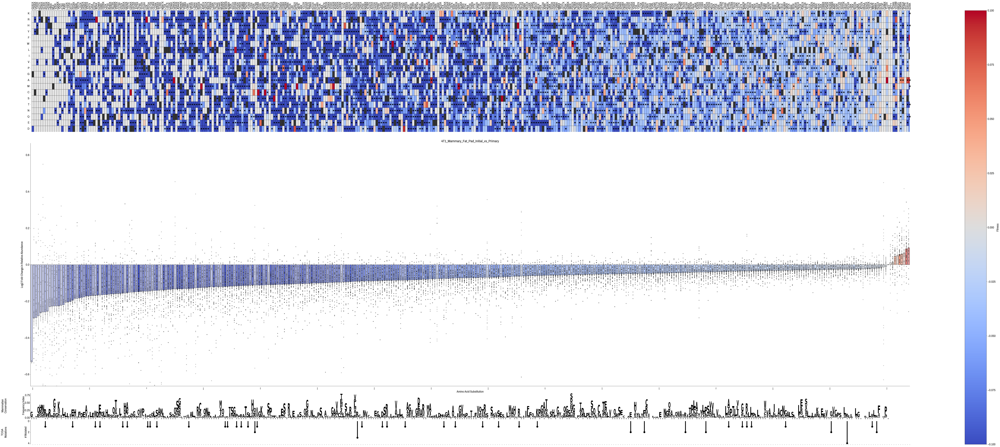

<Figure size 640x480 with 0 Axes>

In [15]:
initial_vs_met = "4T1_Mammary_Fat_Pad_Initial_vs_Primary"
# position2facs = defaultdict(lambda k: np.array([1., 1., 1.]))
# mean_obs_fitness_cmap = mpl.colormaps.get_cmap('coolwarm')
# mean_obs_fitness_range = mpl.colors.TwoSlopeNorm(vmin=min(facs_grouped['logratios'].min(), -.1), vmax=max(facs_grouped['logratios'].max(), 0.1), vcenter=0)
# mean_obs_fitness_colors = mean_obs_fitness_cmap(mean_obs_fitness_range(np.nan_to_num(facs_df['logratios'].values)))
# for i, row in facs_grouped.iterrows():
#     pos = row['variant']
#     ratio = row['logratios']
#     position2facs[pos] = mean_obs_fitness_cmap(mean_obs_fitness_range(np.nan_to_num(ratio)))
# Stack two bar plots
make_fitness_barplot(
    total_output=experiments[initial_vs_met].copy(),
    # secondary_output=experiments[initial_vs_primary].copy(),
    #additional_outputs=[("Mitogen High", experiments[mito_high_p20].copy()), ("Mitogen Low", experiments[mito_low_p20].copy())],
    title=initial_vs_met,
    # secondary_output_title=initial_vs_primary,
    wt_sequence=mSTING,
    color_by_residue=False,
    # color_by_residue=True,
    # split_by_residue=True,
    # plot_by_residues=True,
    symmetrical_y_axis=True,
    weighted=False,
    highlighted_positions=to_highlight,
    # important_variants=tcga_variants,
    intermediate_output_file="figures/barplots/4T1_MFP_Primary_Barplot.xlsx",
    tracks=[
        # ("FACS Log(Log(TPM UP) / Log(TPM DOWN))", position2facs),
        # ("Human\nConservation", position2color),
        # ("Domain", domain2color),
        ("Mammalian\nConservation", functools.partial(make_logo, annotate_positions=conservation_df[conservation_df['Conserved'] == 1]['mouse pos int'].astype(str).values.tolist() + ['REF'])),
        ("TCGA\nMutations", make_lollipop)
    ]
)
plt.savefig(f"figures/barplots/4T1_MFP_Primary.svg")
plt.savefig(f"figures/barplots/4T1_MFP_Primary.pdf")
plt.show()
plt.clf()

C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:1024: RuntimeWarning: All-NaN slice encountered
  results['observed_fitness'].append(np.nanmedian(position_data[res_idx, :]))
C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:1005: RuntimeWarning: All-NaN slice encountered
  results['observed_fitness'].append(np.nanmedian(position_data[res_idx, :]))
C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:984: RuntimeWarning: All-NaN slice encountered
  results['observed_fitness'].append(np.nanmedian(position_data[res_idx, :]))
C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:962: RuntimeWarning: All-NaN slice encountered
  results['observed_fitness'].append(np.nanmedian(position_data[res_idx, :]))
C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:643: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in 

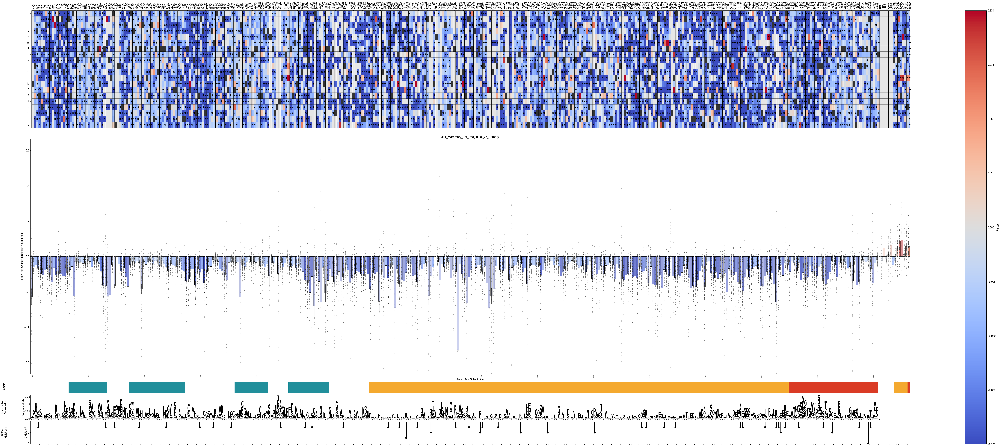

<Figure size 640x480 with 0 Axes>

In [16]:
initial_vs_met = "4T1_Mammary_Fat_Pad_Initial_vs_Primary"
# position2facs = defaultdict(lambda k: np.array([1., 1., 1.]))
# mean_obs_fitness_cmap = mpl.colormaps.get_cmap('coolwarm')
# mean_obs_fitness_range = mpl.colors.TwoSlopeNorm(vmin=min(facs_grouped['logratios'].min(), -.1), vmax=max(facs_grouped['logratios'].max(), 0.1), vcenter=0)
# mean_obs_fitness_colors = mean_obs_fitness_cmap(mean_obs_fitness_range(np.nan_to_num(facs_df['logratios'].values)))
# for i, row in facs_grouped.iterrows():
#     pos = row['variant']
#     ratio = row['logratios']
#     position2facs[pos] = mean_obs_fitness_cmap(mean_obs_fitness_range(np.nan_to_num(ratio)))
# Stack two bar plots
make_fitness_barplot(
    total_output=experiments[initial_vs_met].copy(),
    # secondary_output=experiments[initial_vs_primary].copy(),
    #additional_outputs=[("Mitogen High", experiments[mito_high_p20].copy()), ("Mitogen Low", experiments[mito_low_p20].copy())],
    title=initial_vs_met,
    # secondary_output_title=initial_vs_primary,
    # Order by position
    wt_sequence=mSTING,
    ordering=positional_ordering,
    color_points=False,
    color_by_residue=False,
    # color_by_residue=True,
    # split_by_residue=True,
    # plot_by_residues=True,
    symmetrical_y_axis=True,
    weighted=False,
    highlighted_positions=to_highlight,
    # important_variants=tcga_variants,
    tracks=[
        # ("FACS Log(Log(TPM UP) / Log(TPM DOWN))", position2facs),
        # ("Human\nConservation", position2color),
        ("Domain", domain2color),
        ("Mammalian\nConservation", functools.partial(make_logo, annotate_positions=conservation_df[conservation_df['Conserved'] == 1]['mouse pos int'].astype(str).values.tolist() + ['REF'])),
        ("TCGA\nMutations", make_lollipop)
    ]
)
plt.savefig(f"figures/barplots/4T1_MFP_Primary_POS_ORDERED.svg")
plt.savefig(f"figures/barplots/4T1_MFP_Primary_POS_ORDERED.pdf")
plt.show()
plt.clf()

C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:984: RuntimeWarning: All-NaN slice encountered
  results['observed_fitness'].append(np.nanmedian(position_data[res_idx, :]))
C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:1005: RuntimeWarning: All-NaN slice encountered
  results['observed_fitness'].append(np.nanmedian(position_data[res_idx, :]))
C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:1024: RuntimeWarning: All-NaN slice encountered
  results['observed_fitness'].append(np.nanmedian(position_data[res_idx, :]))
C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:962: RuntimeWarning: All-NaN slice encountered
  results['observed_fitness'].append(np.nanmedian(position_data[res_idx, :]))
C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:643: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in 

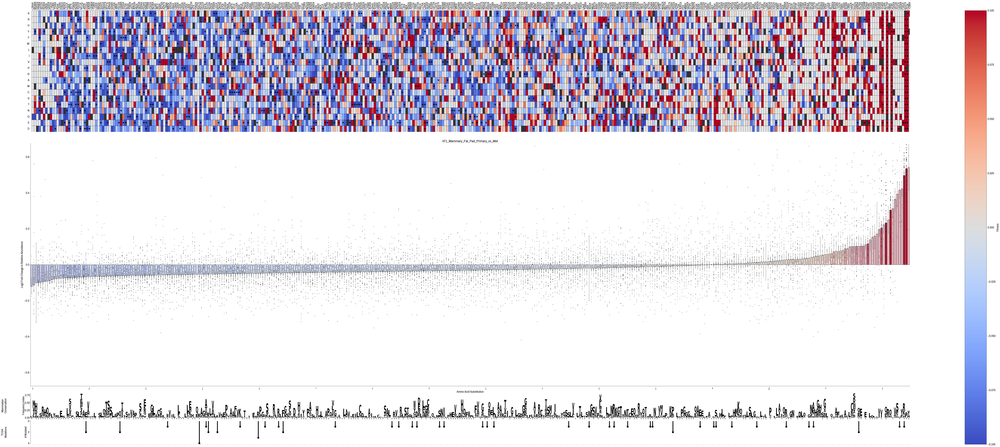

<Figure size 640x480 with 0 Axes>

In [17]:
initial_vs_met = "4T1_Mammary_Fat_Pad_Primary_vs_Met"
# position2facs = defaultdict(lambda k: np.array([1., 1., 1.]))
# mean_obs_fitness_cmap = mpl.colormaps.get_cmap('coolwarm')
# mean_obs_fitness_range = mpl.colors.TwoSlopeNorm(vmin=min(facs_grouped['logratios'].min(), -.1), vmax=max(facs_grouped['logratios'].max(), 0.1), vcenter=0)
# mean_obs_fitness_colors = mean_obs_fitness_cmap(mean_obs_fitness_range(np.nan_to_num(facs_df['logratios'].values)))
# for i, row in facs_grouped.iterrows():
#     pos = row['variant']
#     ratio = row['logratios']
#     position2facs[pos] = mean_obs_fitness_cmap(mean_obs_fitness_range(np.nan_to_num(ratio)))
# Stack two bar plots
make_fitness_barplot(
    total_output=experiments[initial_vs_met].copy(),
    # secondary_output=experiments[initial_vs_primary].copy(),
    #additional_outputs=[("Mitogen High", experiments[mito_high_p20].copy()), ("Mitogen Low", experiments[mito_low_p20].copy())],
    title=initial_vs_met,
    # secondary_output_title=initial_vs_primary,
    wt_sequence=mSTING,
    color_points=False,
    color_by_residue=False,
    # color_by_residue=True,
    # split_by_residue=True,
    # plot_by_residues=True,
    symmetrical_y_axis=True,
    weighted=False,
    highlighted_positions=to_highlight,
    # important_variants=tcga_variants,
    intermediate_output_file="figures/barplots/4T1_MFP_Primary_vs_Met_Barplot.xlsx",
    tracks=[
        # ("FACS Log(Log(TPM UP) / Log(TPM DOWN))", position2facs),
        # ("Human\nConservation", position2color),
        # ("Domain", domain2color),
        ("Mammalian\nConservation", functools.partial(make_logo, annotate_positions=conservation_df[conservation_df['Conserved'] == 1]['mouse pos int'].astype(str).values.tolist() + ['REF'])),
        ("TCGA\nMutations", make_lollipop)
    ]
)
plt.savefig(f"figures/barplots/4T1_MFP_Primary_vs_Met.svg")
plt.savefig(f"figures/barplots/4T1_MFP_Primary_vs_Met.pdf")
plt.show()
plt.clf()

/Users/austinv11/PycharmProjects/SatSeq-Quantification/analysis/../src/satseq_analysis.py:984: RuntimeWarning: All-NaN slice encountered
  results['observed_fitness'].append(np.nanmedian(position_data[res_idx, :]))
/Users/austinv11/PycharmProjects/SatSeq-Quantification/analysis/../src/satseq_analysis.py:1005: RuntimeWarning: All-NaN slice encountered
  results['observed_fitness'].append(np.nanmedian(position_data[res_idx, :]))
/Users/austinv11/PycharmProjects/SatSeq-Quantification/analysis/../src/satseq_analysis.py:1024: RuntimeWarning: All-NaN slice encountered
  results['observed_fitness'].append(np.nanmedian(position_data[res_idx, :]))
/Users/austinv11/PycharmProjects/SatSeq-Quantification/analysis/../src/satseq_analysis.py:962: RuntimeWarning: All-NaN slice encountered
  results['observed_fitness'].append(np.nanmedian(position_data[res_idx, :]))
/Users/austinv11/PycharmProjects/SatSeq-Quantification/analysis/../src/satseq_analysis.py:643: FutureWarning: DataFrameGroupBy.apply opera

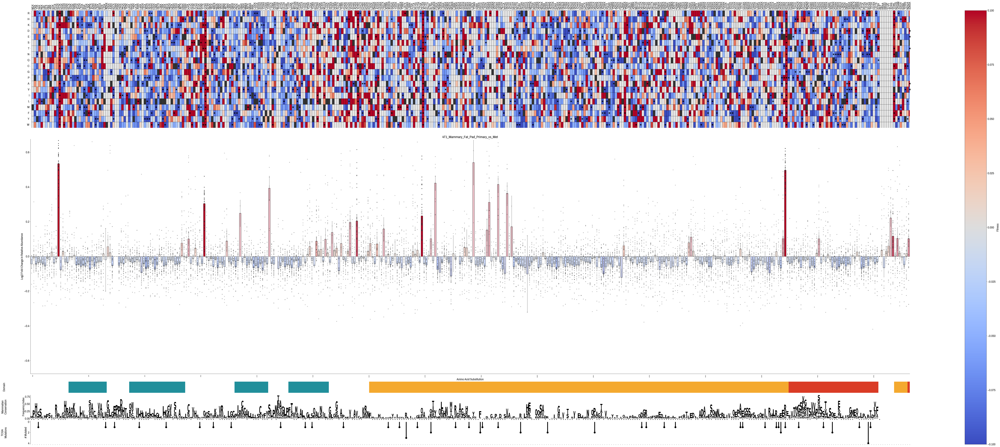

<Figure size 640x480 with 0 Axes>

In [13]:
initial_vs_met = "4T1_Mammary_Fat_Pad_Primary_vs_Met"
# position2facs = defaultdict(lambda k: np.array([1., 1., 1.]))
# mean_obs_fitness_cmap = mpl.colormaps.get_cmap('coolwarm')
# mean_obs_fitness_range = mpl.colors.TwoSlopeNorm(vmin=min(facs_grouped['logratios'].min(), -.1), vmax=max(facs_grouped['logratios'].max(), 0.1), vcenter=0)
# mean_obs_fitness_colors = mean_obs_fitness_cmap(mean_obs_fitness_range(np.nan_to_num(facs_df['logratios'].values)))
# for i, row in facs_grouped.iterrows():
#     pos = row['variant']
#     ratio = row['logratios']
#     position2facs[pos] = mean_obs_fitness_cmap(mean_obs_fitness_range(np.nan_to_num(ratio)))
# Stack two bar plots
make_fitness_barplot(
    total_output=experiments[initial_vs_met].copy(),
    # secondary_output=experiments[initial_vs_primary].copy(),
    #additional_outputs=[("Mitogen High", experiments[mito_high_p20].copy()), ("Mitogen Low", experiments[mito_low_p20].copy())],
    title=initial_vs_met,
    # secondary_output_title=initial_vs_primary,
    # Order by position
    wt_sequence=mSTING,
    ordering=positional_ordering,
    color_points=False,
    # color_by_residue=False,
    # color_by_residue=True,
    # split_by_residue=True,
    # plot_by_residues=True,
    symmetrical_y_axis=True,
    weighted=False,
    highlighted_positions=to_highlight,
    # important_variants=tcga_variants,
    tracks=[
        # ("FACS Log(Log(TPM UP) / Log(TPM DOWN))", position2facs),
        # ("Human\nConservation", position2color),
        ("Domain", domain2color),
        ("Mammalian\nConservation", functools.partial(make_logo, annotate_positions=conservation_df[conservation_df['Conserved'] == 1]['mouse pos int'].astype(str).values.tolist() + ['REF'])),
        ("TCGA\nMutations", make_lollipop)
    ]
)
plt.savefig(f"figures/barplots/4T1_MFP_Primary_vs_Met_POS_ORDERED.svg")
plt.savefig(f"figures/barplots/4T1_MFP_Primary_vs_Met_POS_ORDERED.pdf")
plt.show()
plt.clf()

C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:1024: RuntimeWarning: All-NaN slice encountered
  results['observed_fitness'].append(np.nanmedian(position_data[res_idx, :]))
C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:1005: RuntimeWarning: All-NaN slice encountered
  results['observed_fitness'].append(np.nanmedian(position_data[res_idx, :]))
C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:984: RuntimeWarning: All-NaN slice encountered
  results['observed_fitness'].append(np.nanmedian(position_data[res_idx, :]))
C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:962: RuntimeWarning: All-NaN slice encountered
  results['observed_fitness'].append(np.nanmedian(position_data[res_idx, :]))
C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:643: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in 

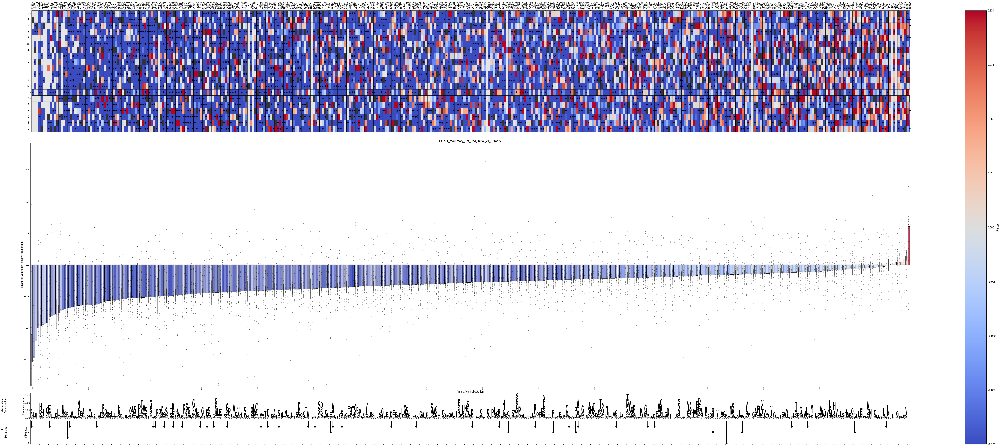

<Figure size 640x480 with 0 Axes>

In [19]:
initial_vs_met = "EO771_Mammary_Fat_Pad_Initial_vs_Primary"
# position2facs = defaultdict(lambda k: np.array([1., 1., 1.]))
# mean_obs_fitness_cmap = mpl.colormaps.get_cmap('coolwarm')
# mean_obs_fitness_range = mpl.colors.TwoSlopeNorm(vmin=min(facs_grouped['logratios'].min(), -.1), vmax=max(facs_grouped['logratios'].max(), 0.1), vcenter=0)
# mean_obs_fitness_colors = mean_obs_fitness_cmap(mean_obs_fitness_range(np.nan_to_num(facs_df['logratios'].values)))
# for i, row in facs_grouped.iterrows():
#     pos = row['variant']
#     ratio = row['logratios']
#     position2facs[pos] = mean_obs_fitness_cmap(mean_obs_fitness_range(np.nan_to_num(ratio)))
# Stack two bar plots
make_fitness_barplot(
    total_output=experiments[initial_vs_met].copy(),
    # secondary_output=experiments[initial_vs_primary].copy(),
    #additional_outputs=[("Mitogen High", experiments[mito_high_p20].copy()), ("Mitogen Low", experiments[mito_low_p20].copy())],
    title=initial_vs_met,
    # secondary_output_title=initial_vs_primary,
    wt_sequence=mSTING,
    color_points=False,
    color_by_residue=False,
    # color_by_residue=True,
    # split_by_residue=True,
    # plot_by_residues=True,
    symmetrical_y_axis=True,
    weighted=False,
    highlighted_positions=to_highlight,
    # important_variants=tcga_variants,
    intermediate_output_file="figures/barplots/EO771_MFP_Primary_Barplot.xlsx",
    tracks=[
        # ("FACS Log(Log(TPM UP) / Log(TPM DOWN))", position2facs),
        # ("Human\nConservation", position2color),
        # ("Domain", domain2color),
        ("Mammalian\nConservation", functools.partial(make_logo, annotate_positions=conservation_df[conservation_df['Conserved'] == 1]['mouse pos int'].astype(str).values.tolist() + ['REF'])),
        ("TCGA\nMutations", make_lollipop)
    ]
)
plt.savefig(f"figures/barplots/EO771_MFP_Primary.svg")
plt.savefig(f"figures/barplots/EO771_MFP_Primary.pdf")
plt.show()
plt.clf()

C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:1024: RuntimeWarning: All-NaN slice encountered
  results['observed_fitness'].append(np.nanmedian(position_data[res_idx, :]))
C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:1005: RuntimeWarning: All-NaN slice encountered
  results['observed_fitness'].append(np.nanmedian(position_data[res_idx, :]))
C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:984: RuntimeWarning: All-NaN slice encountered
  results['observed_fitness'].append(np.nanmedian(position_data[res_idx, :]))
C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:962: RuntimeWarning: All-NaN slice encountered
  results['observed_fitness'].append(np.nanmedian(position_data[res_idx, :]))
C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:643: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in 

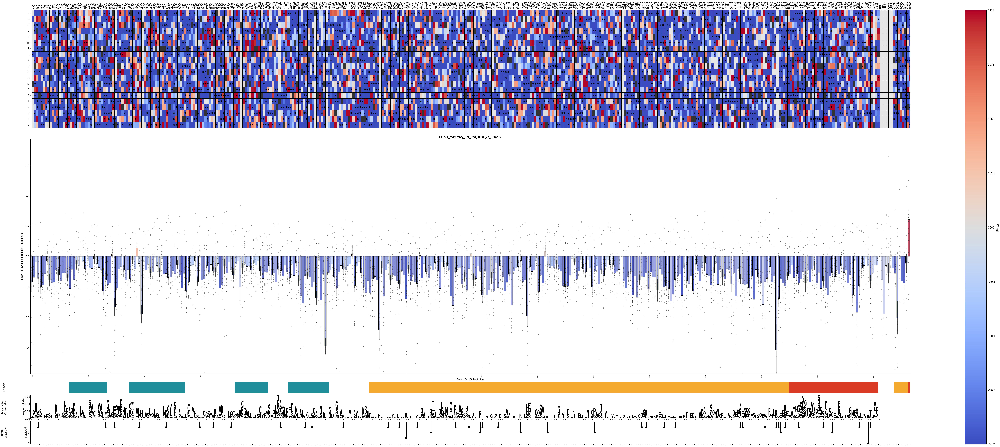

<Figure size 640x480 with 0 Axes>

In [20]:
initial_vs_met = "EO771_Mammary_Fat_Pad_Initial_vs_Primary"
# position2facs = defaultdict(lambda k: np.array([1., 1., 1.]))
# mean_obs_fitness_cmap = mpl.colormaps.get_cmap('coolwarm')
# mean_obs_fitness_range = mpl.colors.TwoSlopeNorm(vmin=min(facs_grouped['logratios'].min(), -.1), vmax=max(facs_grouped['logratios'].max(), 0.1), vcenter=0)
# mean_obs_fitness_colors = mean_obs_fitness_cmap(mean_obs_fitness_range(np.nan_to_num(facs_df['logratios'].values)))
# for i, row in facs_grouped.iterrows():
#     pos = row['variant']
#     ratio = row['logratios']
#     position2facs[pos] = mean_obs_fitness_cmap(mean_obs_fitness_range(np.nan_to_num(ratio)))
# Stack two bar plots
make_fitness_barplot(
    total_output=experiments[initial_vs_met].copy(),
    # secondary_output=experiments[initial_vs_primary].copy(),
    #additional_outputs=[("Mitogen High", experiments[mito_high_p20].copy()), ("Mitogen Low", experiments[mito_low_p20].copy())],
    title=initial_vs_met,
    # secondary_output_title=initial_vs_primary,
    # Order by position
    wt_sequence=mSTING,
    ordering=positional_ordering,
    color_points=False,
    color_by_residue=False,
    # color_by_residue=True,
    # split_by_residue=True,
    # plot_by_residues=True,
    symmetrical_y_axis=True,
    weighted=False,
    highlighted_positions=to_highlight,
    # important_variants=tcga_variants,
    tracks=[
        # ("FACS Log(Log(TPM UP) / Log(TPM DOWN))", position2facs),
        # ("Human\nConservation", position2color),
        ("Domain", domain2color),
        ("Mammalian\nConservation", functools.partial(make_logo, annotate_positions=conservation_df[conservation_df['Conserved'] == 1]['mouse pos int'].astype(str).values.tolist() + ['REF'])),
        ("TCGA\nMutations", make_lollipop)
    ]
)
plt.savefig(f"figures/barplots/EO771_MFP_Primary_POS_ORDERED.svg")
plt.savefig(f"figures/barplots/EO771_MFP_Primary_POS_ORDERED.pdf")
plt.show()
plt.clf()

C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:1024: RuntimeWarning: All-NaN slice encountered
  results['observed_fitness'].append(np.nanmedian(position_data[res_idx, :]))
C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:1005: RuntimeWarning: All-NaN slice encountered
  results['observed_fitness'].append(np.nanmedian(position_data[res_idx, :]))
C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:984: RuntimeWarning: All-NaN slice encountered
  results['observed_fitness'].append(np.nanmedian(position_data[res_idx, :]))
C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:962: RuntimeWarning: All-NaN slice encountered
  results['observed_fitness'].append(np.nanmedian(position_data[res_idx, :]))
C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:643: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in 

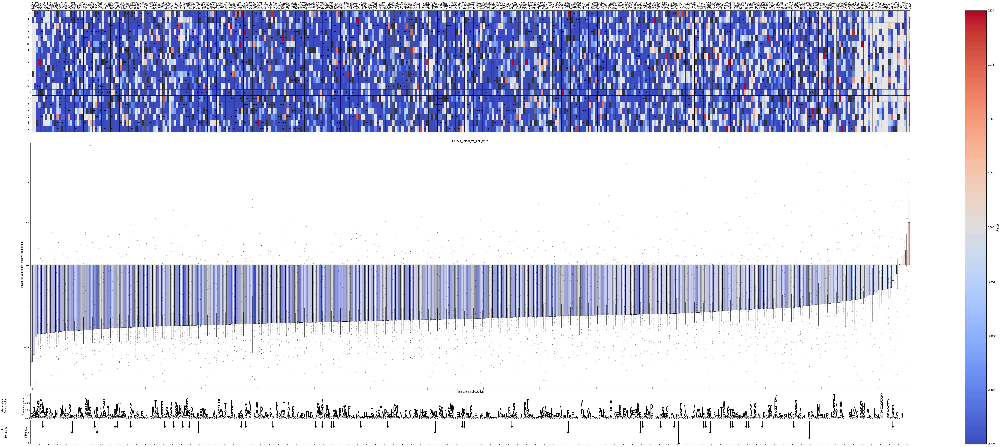

<Figure size 640x480 with 0 Axes>

In [21]:
initial_vs_met = "EO771_Initial_vs_Tail_Vein"
# position2facs = defaultdict(lambda k: np.array([1., 1., 1.]))
# mean_obs_fitness_cmap = mpl.colormaps.get_cmap('coolwarm')
# mean_obs_fitness_range = mpl.colors.TwoSlopeNorm(vmin=min(facs_grouped['logratios'].min(), -.1), vmax=max(facs_grouped['logratios'].max(), 0.1), vcenter=0)
# mean_obs_fitness_colors = mean_obs_fitness_cmap(mean_obs_fitness_range(np.nan_to_num(facs_df['logratios'].values)))
# for i, row in facs_grouped.iterrows():
#     pos = row['variant']
#     ratio = row['logratios']
#     position2facs[pos] = mean_obs_fitness_cmap(mean_obs_fitness_range(np.nan_to_num(ratio)))
# Stack two bar plots
make_fitness_barplot(
    total_output=experiments[initial_vs_met].copy(),
    # secondary_output=experiments[initial_vs_primary].copy(),
    #additional_outputs=[("Mitogen High", experiments[mito_high_p20].copy()), ("Mitogen Low", experiments[mito_low_p20].copy())],
    title=initial_vs_met,
    # secondary_output_title=initial_vs_primary,
    wt_sequence=mSTING,
    color_points=False,
    color_by_residue=False,
    # color_by_residue=True,
    # split_by_residue=True,
    # plot_by_residues=True,
    symmetrical_y_axis=True,
    weighted=False,
    highlighted_positions=to_highlight,
    # important_variants=tcga_variants,
    intermediate_output_file="figures/barplots/EO771_Tail_Vein_Barplot.xlsx",
    tracks=[
        # ("FACS Log(Log(TPM UP) / Log(TPM DOWN))", position2facs),
        # ("Human\nConservation", position2color),
        # ("Domain", domain2color),
        ("Mammalian\nConservation", functools.partial(make_logo, annotate_positions=conservation_df[conservation_df['Conserved'] == 1]['mouse pos int'].astype(str).values.tolist() + ['REF'])),
        ("TCGA\nMutations", make_lollipop)
    ]
)
plt.savefig(f"figures/barplots/EO771_Tail_Vein.svg")
plt.savefig(f"figures/barplots/EO771_Tail_Vein.pdf")
plt.show()
plt.clf()

C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:1024: RuntimeWarning: All-NaN slice encountered
  results['observed_fitness'].append(np.nanmedian(position_data[res_idx, :]))
C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:1005: RuntimeWarning: All-NaN slice encountered
  results['observed_fitness'].append(np.nanmedian(position_data[res_idx, :]))
C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:984: RuntimeWarning: All-NaN slice encountered
  results['observed_fitness'].append(np.nanmedian(position_data[res_idx, :]))
C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:962: RuntimeWarning: All-NaN slice encountered
  results['observed_fitness'].append(np.nanmedian(position_data[res_idx, :]))
C:\Users\Austin\PycharmProjects\SatSeq-Quantification\src\satseq_analysis.py:643: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in 

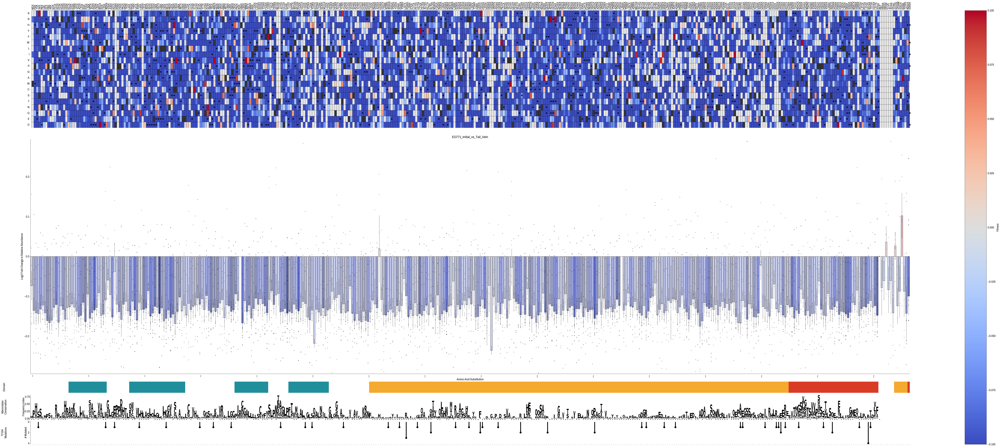

<Figure size 640x480 with 0 Axes>

In [22]:
initial_vs_met = "EO771_Initial_vs_Tail_Vein"
# position2facs = defaultdict(lambda k: np.array([1., 1., 1.]))
# mean_obs_fitness_cmap = mpl.colormaps.get_cmap('coolwarm')
# mean_obs_fitness_range = mpl.colors.TwoSlopeNorm(vmin=min(facs_grouped['logratios'].min(), -.1), vmax=max(facs_grouped['logratios'].max(), 0.1), vcenter=0)
# mean_obs_fitness_colors = mean_obs_fitness_cmap(mean_obs_fitness_range(np.nan_to_num(facs_df['logratios'].values)))
# for i, row in facs_grouped.iterrows():
#     pos = row['variant']
#     ratio = row['logratios']
#     position2facs[pos] = mean_obs_fitness_cmap(mean_obs_fitness_range(np.nan_to_num(ratio)))
# Stack two bar plots
make_fitness_barplot(
    total_output=experiments[initial_vs_met].copy(),
    # secondary_output=experiments[initial_vs_primary].copy(),
    #additional_outputs=[("Mitogen High", experiments[mito_high_p20].copy()), ("Mitogen Low", experiments[mito_low_p20].copy())],
    title=initial_vs_met,
    # secondary_output_title=initial_vs_primary,
    # Order by position
    wt_sequence=mSTING,
    ordering=positional_ordering,
    color_points=False,
    color_by_residue=False,
    # color_by_residue=True,
    # split_by_residue=True,
    # plot_by_residues=True,
    symmetrical_y_axis=True,
    weighted=False,
    highlighted_positions=to_highlight,
    # important_variants=tcga_variants,
    tracks=[
        # ("FACS Log(Log(TPM UP) / Log(TPM DOWN))", position2facs),
        # ("Human\nConservation", position2color),
        ("Domain", domain2color),
        ("Mammalian\nConservation", functools.partial(make_logo, annotate_positions=conservation_df[conservation_df['Conserved'] == 1]['mouse pos int'].astype(str).values.tolist() + ['REF'])),
        ("TCGA\nMutations", make_lollipop)
    ]
)
plt.savefig(f"figures/barplots/EO771_Tail_Vein_POS_ORDERED.svg")
plt.savefig(f"figures/barplots/EO771_Tail_Vein_POS_ORDERED.pdf")
plt.show()
plt.clf()

In [ ]:
def compare_pathway(name, exp_name='4T1_Mammary_Fat_Pad_Initial_vs_Primary'):
    exp = experiments[exp_name]
    pathway_df = pd.read_csv(f"gsea/{name}.csv")

    # Compute score
    pathway_df['score'] = -np.log10(pathway_df['fdr_q']+1e-7) * pathway_df['nes']

    pathways = [
        "CORE_UPR",
        "HALLMARK_INTERFERON_ALPHA_RESPONSE",
        "HALLMARK_TNFA_SIGNALING_VIA_NFKB",
        "HALLMARK_UNFOLDED_PROTEIN_RESPONSE"
    ]
    for pathway in pathways:
        subpath = pathway_df[pathway_df['name'] == pathway]
        subpath = pd.merge(exp.copy(), subpath, on='variant', how='left').dropna(subset=['observed_fitness', 'score'])
        subpath.plot(x='observed_fitness', y='score', kind='scatter', title=f'{exp_name}, {name}', c='fdr_q', cmap='plasma_r')
        plt.savefig(f"figures/{name}_{pathway}.svg")
        plt.savefig(f"figures/{name}_{pathway}.svg")
        plt.show()
        plt.clf()

In [ ]:
compare_pathway('4T1_in_cGAMP_variant_substitution_gsea_results')

compare_pathway('4T1_in_H2O_variant_substitution_gsea_results')

compare_pathway('4T1_in_tumor_variant_substitution_gsea_results')

compare_pathway('4T1_in_cGAMP_variant_substitution_gsea_results', exp_name='4T1_Mammary_Fat_Pad_Primary_vs_Met')

compare_pathway('4T1_in_H2O_variant_substitution_gsea_results', exp_name='4T1_Mammary_Fat_Pad_Primary_vs_Met')

compare_pathway('4T1_in_tumor_variant_substitution_gsea_results', exp_name='4T1_Mammary_Fat_Pad_Primary_vs_Met')

compare_pathway('4T1_in_cGAMP_variant_substitution_gsea_results', exp_name='EO771_Mammary_Fat_Pad_Initial_vs_Primary')

compare_pathway('4T1_in_H2O_variant_substitution_gsea_results', exp_name='EO771_Mammary_Fat_Pad_Initial_vs_Primary')

compare_pathway('4T1_in_tumor_variant_substitution_gsea_results', exp_name='EO771_Mammary_Fat_Pad_Initial_vs_Primary')

In [ ]:
experiments['4T1_Mammary_Fat_Pad_Initial_vs_Primary']

In [ ]:
def make_indep_heatmap(total_output, outline_cmap: dict[str, str] = None):
    # total_output_by_experiment, total_output_by_position = summarize_data(total_output,
    #                                                                       ordering=positional_ordering,
    #                                                                       infill_positions=[],
    #                                                                       keep_residues_independent=False)
    fitness_matrix, residues, experiments = make_fitness_df_matrix(total_output)
    fitness_test_df = test_residues(fitness_matrix, residues, compare_to_ref=False)  # Test for outlier residues
    wt_fitness_test_df = test_residues(fitness_matrix, residues, compare_to_ref=True)  # Test for difference to WT
    fitness_test_df = pd.merge(fitness_test_df, wt_fitness_test_df, on=['position', 'residue', 'observed_fitness'])
    # Add the referece residue to the fitness test
    ref_residue_df = pd.DataFrame({
        'position': [i+1 for i in range(len(mSTING))],
        'ref': list(mSTING),
    })
    fitness_test_df = fitness_test_df.rename(columns={
        'residue': 'alt'
    })
    fitness_test_df = pd.merge(fitness_test_df, ref_residue_df, on='position', how='left')

    fitness_test_df['variant'] = fitness_test_df['ref'] + fitness_test_df.position.astype(str) + \
                                  fitness_test_df['alt']

    # Remove the spike ins
    fitness_test_df = fitness_test_df[fitness_test_df['position'] != fitness_test_df['variant']]

    fig, ax = plt.subplots(figsize=(120, 20))
    return make_fitness_heatmap(fitness_test_df, mSTING,
                         outline_variants=outline_cmap,
                         annotated=tcga_variants, ax=ax)

In [ ]:
make_indep_heatmap(experiments['4T1_Mammary_Fat_Pad_Initial_vs_Met'])
plt.savefig("figures/heatmaps/4T1_MFP_Initial_vs_Met_positional_heatmap.svg")
plt.savefig("figures/heatmaps/4T1_MFP_Initial_vs_Met_positional_heatmap.pdf")
plt.show()

In [ ]:
make_indep_heatmap(experiments['4T1_Mammary_Fat_Pad_Initial_vs_Primary'])
plt.savefig("figures/heatmaps/4T1_MFP_Initial_vs_Primary_positional_heatmap.svg")
plt.savefig("figures/heatmaps/4T1_MFP_Initial_vs_Primary_positional_heatmap.pdf")
plt.show()

In [ ]:
make_indep_heatmap(experiments['4T1_Mammary_Fat_Pad_Primary_vs_Met'])
plt.savefig("figures/heatmaps/4T1_MFP_Primary_vs_Met_positional_heatmap.svg")
plt.savefig("figures/heatmaps/4T1_MFP_Primary_vs_Met_positional_heatmap.pdf")
plt.show()

In [ ]:
make_indep_heatmap(experiments['4T1_Initial_vs_Tail_Vein'])
plt.savefig("figures/heatmaps/4T1_MFP_Initial_vs_Tail_Vein_positional_heatmap.svg")
plt.savefig("figures/heatmaps/4T1_MFP_Initial_vs_Tail_Vein_positional_heatmap.pdf")
plt.show()

In [ ]:
make_indep_heatmap(experiments['EO771_Mammary_Fat_Pad_Initial_vs_Primary'])
plt.savefig("figures/heatmaps/EO771_MFP_Initial_vs_Primary_positional_heatmap.svg")
plt.savefig("figures/heatmaps/EO771_MFP_Initial_vs_Primary_positional_heatmap.pdf")
plt.show()

In [ ]:
make_indep_heatmap(experiments['EO771_Initial_vs_Tail_Vein'])
plt.savefig("figures/heatmaps/EO771_MFP_Initial_vs_Tail_Vein_positional_heatmap.svg")
plt.savefig("figures/heatmaps/EO771_MFP_Initial_vs_Tail_Vein_positional_heatmap.pdf")
plt.show()

In [ ]:
plt.rcParams.update({
    "font.size": 64,
})

In [ ]:
initial_vs_met = "4T1_Ref_Stop_C147_K159_Initial_vs_Tail_Vein"
# position2facs = defaultdict(lambda k: np.array([1., 1., 1.]))
# mean_obs_fitness_cmap = mpl.colormaps.get_cmap('coolwarm')
# mean_obs_fitness_range = mpl.colors.TwoSlopeNorm(vmin=min(facs_grouped['logratios'].min(), -.1), vmax=max(facs_grouped['logratios'].max(), 0.1), vcenter=0)
# mean_obs_fitness_colors = mean_obs_fitness_cmap(mean_obs_fitness_range(np.nan_to_num(facs_df['logratios'].values)))
# for i, row in facs_grouped.iterrows():
#     pos = row['variant']
#     ratio = row['logratios']
#     position2facs[pos] = mean_obs_fitness_cmap(mean_obs_fitness_range(np.nan_to_num(ratio)))
# Stack two bar plots
make_fitness_barplot(
    total_output=experiments[initial_vs_met].copy(),
    # secondary_output=experiments[initial_vs_primary].copy(),
    #additional_outputs=[("Mitogen High", experiments[mito_high_p20].copy()), ("Mitogen Low", experiments[mito_low_p20].copy())],
    title=initial_vs_met,
    # secondary_output_title=initial_vs_primary,
    # wt_sequence=mSTING,
    color_points=False,
    color_by_residue=False,
    symmetrical_y_axis=True,
    weighted=False,
    # highlighted_positions=to_highlight,
    intermediate_output_file="figures/barplots/4T1_Ref_Stop_C147_K151_Barplot.xlsx",
    include_heatmap=False,
    tracks=[
        # ("FACS Log(Log(TPM UP) / Log(TPM DOWN))", position2facs),
        # ("Human\nConservation", position2color),
        # ("Domain", domain2color),
        # ("Mammalian\nConservation", functools.partial(make_logo, annotate_positions=conservation_df[conservation_df['Conserved'] == 1]['mouse pos int'].astype(str).values.tolist() + ['REF'])),
        # ("TCGA\nMutations", make_lollipop)
    ]
)
plt.savefig(f"figures/barplots/4T1_Ref_Stop_C147_K151.svg")
plt.savefig(f"figures/barplots/4T1_Ref_Stop_C147_K151.pdf")
plt.show()
plt.clf()

In [ ]:
initial_vs_met = "4T1_Ref_Stop_C147_K159_Initial_vs_Tail_Vein"
# position2facs = defaultdict(lambda k: np.array([1., 1., 1.]))
# mean_obs_fitness_cmap = mpl.colormaps.get_cmap('coolwarm')
# mean_obs_fitness_range = mpl.colors.TwoSlopeNorm(vmin=min(facs_grouped['logratios'].min(), -.1), vmax=max(facs_grouped['logratios'].max(), 0.1), vcenter=0)
# mean_obs_fitness_colors = mean_obs_fitness_cmap(mean_obs_fitness_range(np.nan_to_num(facs_df['logratios'].values)))
# for i, row in facs_grouped.iterrows():
#     pos = row['variant']
#     ratio = row['logratios']
#     position2facs[pos] = mean_obs_fitness_cmap(mean_obs_fitness_range(np.nan_to_num(ratio)))
# Stack two bar plots
make_fitness_barplot(
    total_output=experiments[initial_vs_met].copy(),
    # secondary_output=experiments[initial_vs_primary].copy(),
    #additional_outputs=[("Mitogen High", experiments[mito_high_p20].copy()), ("Mitogen Low", experiments[mito_low_p20].copy())],
    title=initial_vs_met,
    # secondary_output_title=initial_vs_primary,
    # Order by position
    wt_sequence=mSTING,
    ordering=positional_ordering,
    split_by_residue=False,
    color_points=False,
    color_by_residue=False,
    symmetrical_y_axis=True,
    weighted=False,
    highlighted_positions=to_highlight,
    tracks=[
        # ("FACS Log(Log(TPM UP) / Log(TPM DOWN))", position2facs),
        # ("Human\nConservation", position2color),
        ("Domain", domain2color),
        ("Mammalian\nConservation", functools.partial(make_logo, annotate_positions=conservation_df[conservation_df['Conserved'] == 1]['mouse pos int'].astype(str).values.tolist() + ['REF'])),
        ("TCGA\nMutations", make_lollipop)
    ]
)
plt.savefig(f"figures/barplots/4T1_Ref_Stop_C147_K151_POS_ORDERED.svg")
plt.savefig(f"figures/barplots/4T1_Ref_Stop_C147_K151_POS_ORDERED.pdf")
plt.show()
plt.clf()

Sankeys

In [ ]:
def subsample_column(df, col, count):
    current_counts = df[col].values
    if current_counts.sum() == count:
        # No need to do anything
        return current_counts

    # Randomly subsample
    probabilities = current_counts / current_counts.sum()
    subsampled_indices = np.random.choice(len(current_counts), size=int(count), replace=True, p=probabilities)
    subsampled_counts = np.bincount(subsampled_indices, minlength=len(current_counts))

    return subsampled_counts


def extract_relative_abundance(df, normalize_by_previous, subsample):
    if subsample is not None:
        # Subsample the total to the given number
        df['count'] = subsample_column(df, 'count', subsample)
        df['initial_count'] = subsample_column(df, 'initial_count', subsample)

    df = df.groupby(['variant', 'is_control', 'experiment'])[['count', 'initial_count']].sum().reset_index()
    if normalize_by_previous:
        df['relative_abundance'] = (df['count'] / (df['initial_count']+1))
        df['initial_relative_abundance'] = 1
    else:  # Normalize by total
        df['relative_abundance'] = df['count'] / df['count'].sum()
        df['initial_relative_abundance'] = df['initial_count'] / df['initial_count'].sum()

    df['relative_abundance'] = (df['relative_abundance'] / df['relative_abundance'].sum()) * 100
    df['initial_relative_abundance'] = (df['initial_relative_abundance'] / df['initial_relative_abundance'].sum()) * 100
    # Ensure the relative abundances are normalized with respect to each other for better visualization
    df = df.sort_values('relative_abundance', ascending=False)
    return df

def make_node_list(df, cmap):
    experiment = df['experiment'].iloc[0]
    node_list = []
    for i, row in df.iterrows():
        if row['lower']:
            continue
        node_list.append((row['experiment'] + " " + row['position'], row['relative_abundance'], {'color': cmap[row['position']]}))
    node_list.append((experiment + " " + "Remaining", df[df['lower']].relative_abundance.sum(), {'color': cmap['Remaining']}))
    return node_list

def make_flow_list(df1, df2, position2color):
    state1 = df1['experiment'].iloc[0]
    state2 = df2['experiment'].iloc[0]
    flows = set()

    for i, row1 in df1.iterrows():
        pos = row1['position']
        if pos not in df2['position'].values:
            continue
        row2 = df2[df2['position'] == pos].iloc[0]
        if row1['lower'] and row2['lower']:
            continue
        # start_RA = remaining_start_RA if row1['lower'] else row1['relative_abundance']
        # end_RA = remaining_end_RA if row2['lower'] else row2['relative_abundance']
        start_RA = row1['relative_abundance']
        end_RA = row2['relative_abundance']
        start_state = state1 + " " + ("Remaining" if row1['lower'] else pos)
        end_state = state2 + " " + ("Remaining" if row2['lower'] else pos)
        flows.add((start_state, end_state, (start_RA, end_RA)))

    df_all_remaining = df1[df1['lower'] & df1['position'].isin(df2[df2['lower']]['position'])]
    flows.add((state1 + " " + "Remaining", state2 + " " + "Remaining", df_all_remaining.relative_abundance.sum()))

    return list(flows)

def make_sankey(dfs, title, include_initial=True, include_remaining_bar=True, label=True, normalize_by_previous=True, subsample=False, position2color=None):
    # Retrieve relative abundance
    min_count = min(min(df['count'].sum() for df in dfs), min(df['initial_count'].sum() for df in dfs))
    dfs = [extract_relative_abundance(df, normalize_by_previous, subsample=min_count if subsample else None) for df in dfs]
    if include_initial:
        # Add a psuedo df for the initial state
        initial_df = dfs[0].copy()
        initial_df['experiment'] = 'Initial'
        initial_df['relative_abundance'] = initial_df['initial_relative_abundance']
        dfs = [initial_df] + dfs
    # Compute lower 33% cumulative RA for each dataframe
    nonlower_variants = set()
    for df in dfs:
        df['RA_rank'] = df['relative_abundance'].rank(ascending=True)
        df.sort_values('RA_rank', inplace=True)
        df['RA_cumsum'] = df['relative_abundance'].cumsum()
        df['lower'] = df['RA_cumsum'] < 50.
        nonlower_variants.update(df[~df['lower']].variant)
        df.sort_values('RA_rank', ascending=False, inplace=True)
    # Set lower to false for all variants that are non lower in ANY of the dataframes
    for df in dfs:
        df['lower'] = ~df['variant'].isin(nonlower_variants)
    # Get every consecutive pair of experiments
    pairs = [(dfs[i], dfs[i + 1]) for i in range(len(dfs) - 1)]

    all_positions = set()
    for df in dfs:
        all_positions = all_positions | set(df.variant.unique())
    if not position2color:
        palette = color_palette('tab20', len(all_positions))
        position2color = {pos: palette[i] for i, pos in enumerate(all_positions)}
    if "Remaining" not in position2color:
        # Add grey for "Remaining"
        position2color['Remaining'] = np.array([0.5, 0.5, 0.5])

    flows = []
    # Add initial nodes
    nodes = [make_node_list(dfs[0], position2color)]
    for df1, df2 in pairs:
        flows += make_flow_list(df1, df2, position2color)
        nodes.append(make_node_list(df2, position2color))

    if not include_remaining_bar:
        nodes = [[n2 for n2 in n if 'Remaining' not in n2[0]] for n in nodes]
        flows = [f for f in flows if 'Remaining' not in f[0] and 'Remaining' not in f[1]]

    plt.figure(figsize=(20, 20), dpi=450)
    sankey = Sankey(flows=flows, nodes=nodes, node_height_pad_min=0.001, node_pad_y_min=.001, flow_color_mode='source')

    # Change font
    for nodes in sankey.nodes:
        for node in nodes:
            node.label_opts = {'fontsize': 8}
            node.label_pos = 'left'

    sankey.draw()
    ax = plt.gca()
    # Remove all the text elements if label is false
    if not label:
        for text in ax.texts:
            text.set_visible(False)
    plt.suptitle(title)

# Generate consistent colormappings
all_positions = set()
for exp in experiments.values():
    all_positions = all_positions | set(exp.variant.unique())
palette = color_palette('tab20', len(all_positions))
position2color = {pos: palette[i] for i, pos in enumerate(all_positions)}

In [ ]:
make_sankey([
    experiments['4T1_Initial_vs_MitogenHigh_p5'].copy().assign(experiment='p5'),
    experiments['4T1_MitogenHigh_p5_vs_p10'].copy().assign(experiment='p10'),
    experiments['4T1_MitogenHigh_p10_vs_p20'].copy().assign(experiment='p20')
], "4T1 Mitogen High Experiment", label=False, position2color=position2color)
plt.savefig("figures/sankey/4T1_Mitogen_High_sankey_NO_LABELS.svg")
plt.savefig("figures/sankey/4T1_Mitogen_High_sankey_NO_LABELS.pdf")
plt.clf()
make_sankey([
    experiments['4T1_Initial_vs_MitogenHigh_p5'].copy().assign(experiment='p5'),
    experiments['4T1_MitogenHigh_p5_vs_p10'].copy().assign(experiment='p10'),
    experiments['4T1_MitogenHigh_p10_vs_p20'].copy().assign(experiment='p20')
], "4T1 Mitogen High Experiment", position2color=position2color)
plt.savefig("figures/sankey/4T1_Mitogen_High_sankey.svg")
plt.savefig("figures/sankey/4T1_Mitogen_High_sankey.pdf")
plt.show()

In [ ]:
make_sankey([
    experiments['EO771_Initial_vs_MitogenHigh_p5'].copy().assign(experiment='p5'),
    experiments['EO771_MitogenHigh_p5_vs_p10'].copy().assign(experiment='p10'),
    experiments['EO771_MitogenHigh_p10_vs_p20'].copy().assign(experiment='p20')
], "EO771 Mitogen High Experiment", label=False, position2color=position2color)
plt.savefig("figures/sankey/EO771_Mitogen_High_sankey_NO_LABELS.svg")
plt.savefig("figures/sankey/EO771_Mitogen_High_sankey_NO_LABELS.pdf")
plt.clf()
make_sankey([
    experiments['EO771_Initial_vs_MitogenHigh_p5'].copy().assign(experiment='p5'),
    experiments['EO771_MitogenHigh_p5_vs_p10'].copy().assign(experiment='p10'),
    experiments['EO771_MitogenHigh_p10_vs_p20'].copy().assign(experiment='p20')
], "EO771 Mitogen High Experiment", position2color=position2color)
plt.savefig("figures/sankey/EO771_Mitogen_High_sankey.svg")
plt.savefig("figures/sankey/EO771_Mitogen_High_sankey.pdf")
plt.show()

In [ ]:
make_sankey([
    experiments['4T1_Initial_vs_MitogenLow_p5'].copy().assign(experiment='p5'),
    experiments['4T1_MitogenLow_p5_vs_p10'].copy().assign(experiment='p10'),
    experiments['4T1_MitogenLow_p10_vs_p20'].copy().assign(experiment='p20')
], "4T1 Mitogen Low Experiment", label=False, position2color=position2color)
plt.savefig("figures/sankey/4T1_Mitogen_Low_sankey_NO_LABELS.svg")
plt.savefig("figures/sankey/4T1_Mitogen_Low_sankey_NO_LABELS.pdf")
plt.clf()
make_sankey([
    experiments['4T1_Initial_vs_MitogenLow_p5'].copy().assign(experiment='p5'),
    experiments['4T1_MitogenLow_p5_vs_p10'].copy().assign(experiment='p10'),
    experiments['4T1_MitogenLow_p10_vs_p20'].copy().assign(experiment='p20')
], "4T1 Mitogen Low Experiment", position2color=position2color)
plt.savefig("figures/sankey/4T1_Mitogen_Low_sankey.svg")
plt.savefig("figures/sankey/4T1_Mitogen_Low_sankey.pdf")
plt.show()

In [ ]:
# Sankey for the 4T1 Initial -> Primary -> Metastasis
make_sankey([
    experiments['4T1_Mammary_Fat_Pad_Initial_vs_Primary'].copy().assign(experiment='Primary'),
    experiments['4T1_Mammary_Fat_Pad_Primary_vs_Met'].copy().assign(experiment='Metastasis')
], "4T1 Mammary Fat Pad Initial -> Primary -> Metastasis", label=False, position2color=position2color)
plt.savefig("figures/sankey/4T1_MFP_Initial_vs_Primary_vs_Met_sankey_NO_LABELS.svg")
plt.savefig("figures/sankey/4T1_MFP_Initial_vs_Primary_vs_Met_sankey_NO_LABELS.pdf")
plt.clf()
make_sankey([
    experiments['4T1_Mammary_Fat_Pad_Initial_vs_Primary'].copy().assign(experiment='Primary'),
    experiments['4T1_Mammary_Fat_Pad_Primary_vs_Met'].copy().assign(experiment='Metastasis')
], "4T1 Mammary Fat Pad Initial -> Primary -> Metastasis", position2color=position2color)
plt.savefig("figures/sankey/4T1_MFP_Initial_vs_Primary_vs_Met_sankey.svg")
plt.savefig("figures/sankey/4T1_MFP_Initial_vs_Primary_vs_Met_sankey.pdf")
plt.show()

In [ ]:
make_sankey([
    experiments['4T1_Mammary_Fat_Pad_Initial_vs_Primary'].copy().assign(experiment='Primary'),
    experiments['4T1_Mammary_Fat_Pad_Primary_vs_Met'].copy().assign(experiment='Metastasis')
], "4T1 Mammary Fat Pad Primary -> Metastasis", include_initial=False, label=False, position2color=position2color)
plt.savefig("figures/sankey/4T1_MFP_Initial_vs_Primary_vs_Met_sankey_NO_INITIAL_NO_LABELS.svg")
plt.savefig("figures/sankey/4T1_MFP_Initial_vs_Primary_vs_Met_sankey_NO_INITIAL_NO_LABELS.pdf")
plt.clf()
make_sankey([
    experiments['4T1_Mammary_Fat_Pad_Initial_vs_Primary'].copy().assign(experiment='Primary'),
    experiments['4T1_Mammary_Fat_Pad_Primary_vs_Met'].copy().assign(experiment='Metastasis')
], "4T1 Mammary Fat Pad Primary -> Metastasis", include_initial=False, position2color=position2color)
plt.savefig("figures/sankey/4T1_MFP_Initial_vs_Primary_vs_Met_sankey_NO_INITIAL.svg")
plt.savefig("figures/sankey/4T1_MFP_Initial_vs_Primary_vs_Met_sankey_NO_INITIAL.pdf")
plt.show()

In [ ]:
make_sankey([
    experiments['4T1_Mammary_Fat_Pad_Initial_vs_Primary'].copy().assign(experiment='Primary'),
    experiments['4T1_Mammary_Fat_Pad_Primary_vs_Met'].copy().assign(experiment='Metastasis')
], "4T1 Mammary Fat Pad Primary -> Metastasis", include_initial=False, include_remaining_bar=False, label=False, position2color=position2color)
plt.savefig("figures/sankey/4T1_MFP_Initial_vs_Primary_vs_Met_sankey_NO_INITIAL_REMOVED_SMALL_VARIANTS_NO_LABELS.svg")
plt.savefig("figures/sankey/4T1_MFP_Initial_vs_Primary_vs_Met_sankey_NO_INITIAL_REMOVED_SMALL_VARIANTS_NO_LABELS.pdf")
plt.clf()
make_sankey([
    experiments['4T1_Mammary_Fat_Pad_Initial_vs_Primary'].copy().assign(experiment='Primary'),
    experiments['4T1_Mammary_Fat_Pad_Primary_vs_Met'].copy().assign(experiment='Metastasis')
], "4T1 Mammary Fat Pad Primary -> Metastasis", include_initial=False, include_remaining_bar=False, position2color=position2color)
plt.savefig("figures/sankey/4T1_MFP_Initial_vs_Primary_vs_Met_sankey_NO_INITIAL_REMOVED_SMALL_VARIANTS.svg")
plt.savefig("figures/sankey/4T1_MFP_Initial_vs_Primary_vs_Met_sankey_NO_INITIAL_REMOVED_SMALL_VARIANTS.pdf")
plt.show()

In [ ]:
# Do per-mouse for 4t1
os.makedirs("figures/sankey/4T1_MFP_Per_Mouse/relative_to_previous", exist_ok=True)
for mouse in mice:
    initial_vs_primary = experiments['4T1_Mammary_Fat_Pad_Initial_vs_Primary']
    initial_vs_primary = initial_vs_primary[initial_vs_primary.experiment == f'{mouse}_Mammory_Fat_Pad_Primary_Tumor'].copy().assign(experiment='Primary')
    primary_vs_met = experiments['4T1_Mammary_Fat_Pad_Primary_vs_Met']
    primary_vs_met = primary_vs_met[primary_vs_met.experiment == f'{mouse}_Mammory_Fat_Pad_Lung_Metastasis'].copy().assign(experiment='Metastasis')
    make_sankey([
        initial_vs_primary,
        primary_vs_met
    ], f"4T1 Mammary Fat Pad Primary -> Metastasis, Mouse {mouse}", include_initial=False, include_remaining_bar=False, label=False, normalize_by_previous=True, position2color=position2color)
    plt.savefig(f"figures/sankey/4T1_MFP_Per_Mouse/relative_to_previous/mouse_{mouse}_sankey_NO_INITIAL_REMOVED_SMALL_VARIANTS_NO_LABELS.svg")
    plt.savefig(f"figures/sankey/4T1_MFP_Per_Mouse/relative_to_previous/mouse_{mouse}_sankey_NO_INITIAL_REMOVED_SMALL_VARIANTS_NO_LABELS.pdf")
    plt.clf()
    make_sankey([
        initial_vs_primary,
        primary_vs_met
    ], f"4T1 Mammary Fat Pad Primary -> Metastasis, Mouse {mouse}", include_initial=False, include_remaining_bar=False, normalize_by_previous=True, position2color=position2color)
    plt.savefig(f"figures/sankey/4T1_MFP_Per_Mouse/relative_to_previous/mouse_{mouse}_sankey_NO_INITIAL_REMOVED_SMALL_VARIANTS.svg")
    plt.savefig(f"figures/sankey/4T1_MFP_Per_Mouse/relative_to_previous/mouse_{mouse}_sankey_NO_INITIAL_REMOVED_SMALL_VARIANTS.pdf")
    plt.clf()

In [ ]:
# Do per-mouse for 4t1
os.makedirs("figures/sankey/4T1_MFP_Per_Mouse/relative_to_total", exist_ok=True)
for mouse in mice:
    initial_vs_primary = experiments['4T1_Mammary_Fat_Pad_Initial_vs_Primary']
    initial_vs_primary = initial_vs_primary[initial_vs_primary.experiment == f'{mouse}_Mammory_Fat_Pad_Primary_Tumor'].copy().assign(experiment='Primary')
    primary_vs_met = experiments['4T1_Mammary_Fat_Pad_Primary_vs_Met']
    primary_vs_met = primary_vs_met[primary_vs_met.experiment == f'{mouse}_Mammory_Fat_Pad_Lung_Metastasis'].copy().assign(experiment='Metastasis')
    make_sankey([
        initial_vs_primary,
        primary_vs_met
    ], f"4T1 Mammary Fat Pad Primary -> Metastasis, Mouse {mouse}", include_initial=False, include_remaining_bar=False, label=False, normalize_by_previous=False, position2color=position2color)
    plt.savefig(f"figures/sankey/4T1_MFP_Per_Mouse/relative_to_total/mouse_{mouse}_sankey_NO_INITIAL_REMOVED_SMALL_VARIANTS_NO_LABELS.svg")
    plt.savefig(f"figures/sankey/4T1_MFP_Per_Mouse/relative_to_total/mouse_{mouse}_sankey_NO_INITIAL_REMOVED_SMALL_VARIANTS_NO_LABELS.pdf")
    plt.clf()
    make_sankey([
        initial_vs_primary,
        primary_vs_met
    ], f"4T1 Mammary Fat Pad Primary -> Metastasis, Mouse {mouse}", include_initial=False, include_remaining_bar=False, normalize_by_previous=False, position2color=position2color)
    plt.savefig(f"figures/sankey/4T1_MFP_Per_Mouse/relative_to_total/mouse_{mouse}_sankey_NO_INITIAL_REMOVED_SMALL_VARIANTS.svg")
    plt.savefig(f"figures/sankey/4T1_MFP_Per_Mouse/relative_to_total/mouse_{mouse}_sankey_NO_INITIAL_REMOVED_SMALL_VARIANTS.pdf")
    plt.clf()

In [ ]:
# Do per-mouse for 4t1
os.makedirs("figures/sankey/4T1_MFP_Per_Mouse/relative_to_previous_SUBSAMPLED_TO_MIN", exist_ok=True)
for mouse in mice:
    initial_vs_primary = experiments['4T1_Mammary_Fat_Pad_Initial_vs_Primary']
    initial_vs_primary = initial_vs_primary[initial_vs_primary.experiment == f'{mouse}_Mammory_Fat_Pad_Primary_Tumor'].copy().assign(experiment='Primary')
    primary_vs_met = experiments['4T1_Mammary_Fat_Pad_Primary_vs_Met']
    primary_vs_met = primary_vs_met[primary_vs_met.experiment == f'{mouse}_Mammory_Fat_Pad_Lung_Metastasis'].copy().assign(experiment='Metastasis')
    make_sankey([
        initial_vs_primary,
        primary_vs_met
    ], f"4T1 Mammary Fat Pad Primary -> Metastasis, Mouse {mouse}", include_initial=False, include_remaining_bar=False, label=False, normalize_by_previous=True, subsample=True, position2color=position2color)
    plt.savefig(f"figures/sankey/4T1_MFP_Per_Mouse/relative_to_previous_SUBSAMPLED_TO_MIN/mouse_{mouse}_sankey_NO_INITIAL_REMOVED_SMALL_VARIANTS_NO_LABELS.svg")
    plt.savefig(f"figures/sankey/4T1_MFP_Per_Mouse/relative_to_previous_SUBSAMPLED_TO_MIN/mouse_{mouse}_sankey_NO_INITIAL_REMOVED_SMALL_VARIANTS_NO_LABELS.pdf")
    plt.clf()
    make_sankey([
        initial_vs_primary,
        primary_vs_met
    ], f"4T1 Mammary Fat Pad Primary -> Metastasis, Mouse {mouse}", include_initial=False, include_remaining_bar=False, normalize_by_previous=True, subsample=True, position2color=position2color)
    plt.savefig(f"figures/sankey/4T1_MFP_Per_Mouse/relative_to_previous_SUBSAMPLED_TO_MIN/mouse_{mouse}_sankey_NO_INITIAL_REMOVED_SMALL_VARIANTS.svg")
    plt.savefig(f"figures/sankey/4T1_MFP_Per_Mouse/relative_to_previous_SUBSAMPLED_TO_MIN/mouse_{mouse}_sankey_NO_INITIAL_REMOVED_SMALL_VARIANTS.pdf")
    plt.clf()

In [ ]:
# Do per-mouse for 4t1
os.makedirs("figures/sankey/4T1_MFP_Per_Mouse/relative_to_total_SUBSAMPLED_TO_MIN", exist_ok=True)
for mouse in mice:
    initial_vs_primary = experiments['4T1_Mammary_Fat_Pad_Initial_vs_Primary']
    initial_vs_primary = initial_vs_primary[initial_vs_primary.experiment == f'{mouse}_Mammory_Fat_Pad_Primary_Tumor'].copy().assign(experiment='Primary')
    primary_vs_met = experiments['4T1_Mammary_Fat_Pad_Primary_vs_Met']
    primary_vs_met = primary_vs_met[primary_vs_met.experiment == f'{mouse}_Mammory_Fat_Pad_Lung_Metastasis'].copy().assign(experiment='Metastasis')
    make_sankey([
        initial_vs_primary,
        primary_vs_met
    ], f"4T1 Mammary Fat Pad Primary -> Metastasis, Mouse {mouse}", include_initial=False, include_remaining_bar=False, label=False, normalize_by_previous=False, subsample=True, position2color=position2color)
    plt.savefig(f"figures/sankey/4T1_MFP_Per_Mouse/relative_to_total_SUBSAMPLED_TO_MIN/mouse_{mouse}_sankey_NO_INITIAL_REMOVED_SMALL_VARIANTS_NO_LABELS.svg")
    plt.savefig(f"figures/sankey/4T1_MFP_Per_Mouse/relative_to_total_SUBSAMPLED_TO_MIN/mouse_{mouse}_sankey_NO_INITIAL_REMOVED_SMALL_VARIANTS_NO_LABELS.pdf")
    plt.clf()
    make_sankey([
        initial_vs_primary,
        primary_vs_met
    ], f"4T1 Mammary Fat Pad Primary -> Metastasis, Mouse {mouse}", include_initial=False, include_remaining_bar=False, normalize_by_previous=False, subsample=True, position2color=position2color)
    plt.savefig(f"figures/sankey/4T1_MFP_Per_Mouse/relative_to_total_SUBSAMPLED_TO_MIN/mouse_{mouse}_sankey_NO_INITIAL_REMOVED_SMALL_VARIANTS.svg")
    plt.savefig(f"figures/sankey/4T1_MFP_Per_Mouse/relative_to_total_SUBSAMPLED_TO_MIN/mouse_{mouse}_sankey_NO_INITIAL_REMOVED_SMALL_VARIANTS.pdf")
    plt.clf()